<a href="https://colab.research.google.com/github/joshua12cx/Metamodelo-interpretable-de-Machine-Learning-basado-en-ensemble-stacking-PR./blob/main/PREECLAMPSIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Metamodelo de Machine Learning basado en ensemble stacking para la detección temprana del riesgo de preeclampsia en gestantes peruanas**

Integrantes:
* Hidalgo Jauregui Karla Monica
* Pedraza Perez Joshua Josue
* Quispe Mamani Deyvis

## **FASE 1: ADQUISICIÓN Y EXPLORACIÓN DE DATOS**


### 1. Recolección de datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu
from scipy.stats import chi2_contingency
from pathlib import Path

# Carga del conjunto de datos
df = pd.read_csv("/content/Preeclampsia1.csv")

# Inspección inicial
print("===== INFORMACIÓN GENERAL DEL DATASET =====")
df.info()

print("\n===== COLUMNAS DEL DATASET =====")
print(df.columns)

print(f"\n===== DIMENSIONES DEL DATASET =====\nFilas: {df.shape[0]}\nColumnas: {df.shape[1]}")

print("\n===== PRIMEROS 10 REGISTROS =====")
display(df.head(10))

print("\n===== ÚLTIMOS 5 REGISTROS =====")
display(df.tail(5))

===== INFORMACIÓN GENERAL DEL DATASET =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4579 entries, 0 to 4578
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   edad            4579 non-null   int64  
 1   edad_gestacion  4579 non-null   int64  
 2   talla           4579 non-null   float64
 3   peso            4579 non-null   float64
 4   imc             4579 non-null   float64
 5   p_a_sistolica   4579 non-null   int64  
 6   p_a_diastolica  4579 non-null   int64  
 7   hemoglobina     4579 non-null   float64
 8   creatinina      4579 non-null   float64
 9   hipertension    4579 non-null   int64  
 10  diabetes        4579 non-null   int64  
 11  ant_fam_hiper   4579 non-null   int64  
 12  Preeclampsia    4579 non-null   int64  
dtypes: float64(5), int64(8)
memory usage: 465.2 KB

===== COLUMNAS DEL DATASET =====
Index(['edad', 'edad_gestacion', 'talla', 'peso', 'imc', 'p_a_sistolica',
       'p_a_di

,edad,edad_gestacion,talla,peso,imc,p_a_sistolica,p_a_diastolica,hemoglobina,creatinina,hipertension,diabetes,ant_fam_hiper,Preeclampsia
0,22,12,165.0,93.0,34.16,127,80,15.07,0.80,0,1,1,1
1,27,12,152.0,76.0,32.89,122,70,11.83,1.34,0,0,0,1
2,32,13,154.0,80.0,33.73,126,89,14.68,1.42,1,1,0,1
3,25,12,154.0,112.0,47.23,128,88,11.20,0.77,0,0,0,1
4,17,11,154.0,53.0,22.35,122,80,10.67,1.10,0,1,1,1
5,26,10,155.0,130.0,54.11,136,88,15.47,1.18,1,0,1,1
6,26,13,155.0,53.0,22.06,122,70,15.58,1.08,0,0,0,1
7,24,12,154.0,66.0,27.83,136,71,14.10,0.76,0,1,1,1
8,18,11,149.0,101.0,45.49,122,81,15.83,0.85,0,0,1,1
9,33,11,162.0,71.0,27.05,121,75,14.30,0.00,1,0,0,1



===== ÚLTIMOS 5 REGISTROS =====


,edad,edad_gestacion,talla,peso,imc,p_a_sistolica,p_a_diastolica,hemoglobina,creatinina,hipertension,diabetes,ant_fam_hiper,Preeclampsia
4574,32,12,149.0,88.0,39.64,113,73,12.00,0.0,0,0,0,0
4575,35,11,151.0,71.0,31.14,100,70,11.60,0.0,0,0,0,0
4576,28,11,158.0,90.0,36.05,124,74,11.23,0.0,0,0,0,0
4577,28,11,152.0,66.0,28.57,100,60,12.00,0.0,0,0,0,0
4578,36,11,150.0,78.0,34.67,108,63,12.40,0.0,0,0,0,0


**Interpretación inicial**

Se realizó la carga e inspección inicial del conjunto de datos `Preeclampsia1.csv`, constituido por **4,579 registros y 13 variables**, de las cuales 12 corresponden a características clínicas y antecedentes maternos, mientras que la variable restante (`Preeclampsia`) representa el desenlace de interés.

Las variables disponibles comprenden características demográficas (edad materna), obstétricas (edad gestacional), antropométricas (talla, peso e índice de masa corporal), hemodinámicas (presión arterial sistólica y diastólica), bioquímicas (hemoglobina y creatinina) y antecedentes clínicos (hipertensión, diabetes y antecedentes familiares de hipertensión).

La inspección identificó **ocho columnas de tipo entero (`int64`) y cinco de tipo decimal (`float64`)**. Asimismo, las 13 variables presentaron 4,579 valores no nulos, por lo que no se identificaron valores ausentes representados como `NaN` en esta etapa.

**Observación:** Se identificaron valores de creatinina iguales a `0.00` en los registros visualizados. Aunque no se consideran valores nulos automáticamente, requieren una evaluación posterior para determinar su validez clínica y posible tratamiento durante el preprocesamiento.

### 2. Exploración y análisis descriptivo de datos

#### 2.1 Análisis descriptivo

In [ ]:
# Estructura y resumen estadístico
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

display(df.describe(include="all").T)

# Tipos de datos
print("\n*** Tipos por columna ***")
print(df.dtypes)

# Resumen categóricas (si existieran tipo object)
cat_cols = df.select_dtypes(include=["object"]).columns
if len(cat_cols):
    print("\n*** Resumen de variables categóricas (object) ***")
    display(df[cat_cols].describe().T)
else:
    print("\nNo hay columnas 'object' categóricas.")

# Distribución de la variable objetivo
clases = df["Preeclampsia"].value_counts()

print("\n*** Distribución de Preeclampsia ***")
print(clases)

print("\n*** Porcentajes ***")
print((clases / len(df) * 100).round(2))

# Relación de desbalance
IR = clases[0] / clases[1]
print(f"\nImbalance Ratio: {IR:.2f}")

Filas: 4579 | Columnas: 13


,count,mean,std,min,25%,50%,75%,max
edad,4579.0,29.709325,6.888269,13.00,24.000,30.00,35.00,46.00
edad_gestacion,4579.0,11.471937,0.924775,10.00,11.000,12.00,12.00,14.00
talla,4579.0,155.633654,6.540607,130.00,151.000,155.00,160.00,195.00
peso,4579.0,70.219181,14.201445,40.20,60.000,68.00,78.00,144.00
imc,4579.0,29.018253,5.708879,15.43,24.795,28.44,32.36,57.77
p_a_sistolica,4579.0,100.991920,32.090049,0.00,99.000,109.00,118.00,178.00
p_a_diastolica,4579.0,61.485040,20.091152,0.00,60.000,60.00,71.00,100.00
hemoglobina,4579.0,11.277045,3.302850,0.00,11.000,11.90,12.80,16.90
creatinina,4579.0,0.110378,0.332892,0.00,0.000,0.00,0.00,1.49
hipertension,4579.0,0.068356,0.252383,0.00,0.000,0.00,0.00,1.00



*** Tipos por columna ***
edad                int64
edad_gestacion      int64
talla             float64
peso              float64
imc               float64
p_a_sistolica       int64
p_a_diastolica      int64
hemoglobina       float64
creatinina        float64
hipertension        int64
diabetes            int64
ant_fam_hiper       int64
Preeclampsia        int64
dtype: object

No hay columnas 'object' categóricas.

*** Distribución de Preeclampsia ***
Preeclampsia
0    4013
1     566
Name: count, dtype: int64

*** Porcentajes ***
Preeclampsia
0    87.64
1    12.36
Name: count, dtype: float64

Imbalance Ratio: 7.09


El análisis descriptivo inicial comprendió 4,579 registros y 13 variables, incluyendo 12 características predictoras y la variable objetivo `Preeclampsia`.

La edad materna presentó una media de 29.71 ± 6.89 años, con valores comprendidos entre 13 y 46 años. La edad gestacional osciló entre 10 y 14 semanas, con una media de 11.47 ± 0.92 semanas. El índice de masa corporal (IMC) presentó una media de 29.02 ± 5.71 kg/m².

La presión arterial sistólica registró una media de 100.99 ± 32.09 mmHg, mientras que la presión arterial diastólica alcanzó 61.49 ± 20.09 mmHg. Estos estadísticos incluyen registros con valores iguales a cero, cuya validez deberá examinarse durante la evaluación de calidad de datos.

Respecto a la variable objetivo, 4,013 registros (87.64 %) correspondieron a gestantes sin preeclampsia y 566 (12.36 %) a gestantes con preeclampsia. La relación de desbalance (Imbalance Ratio, IR) fue de 7.09, evidenciando una representación considerablemente menor de la clase positiva.

Esta distribución justifica evaluar estrategias específicas para abordar el desbalance de clases durante el entrenamiento, evitando que los modelos favorezcan predominantemente a la clase mayoritaria.

#### 2.2 Análisis descriptivo (gráficos)

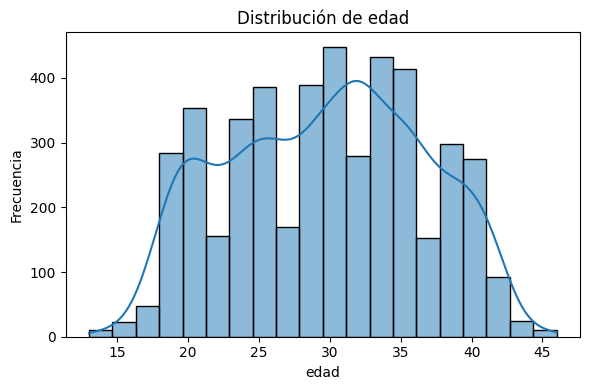

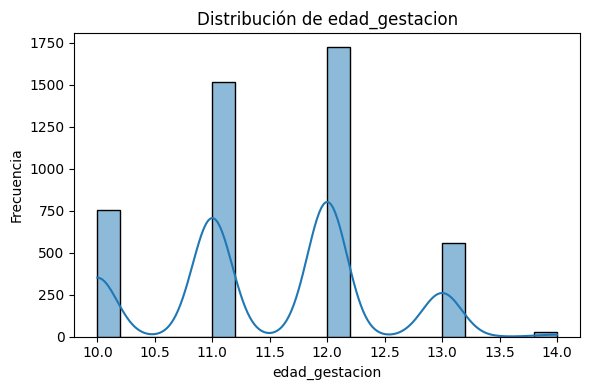

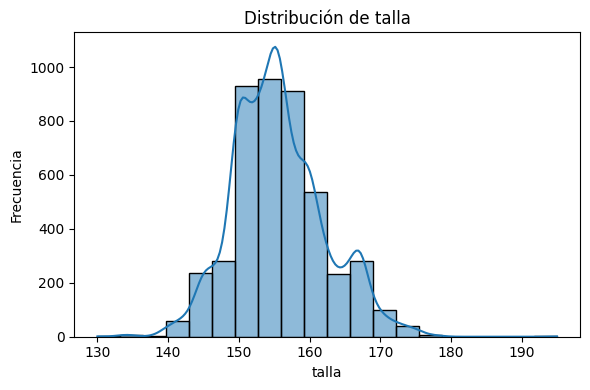

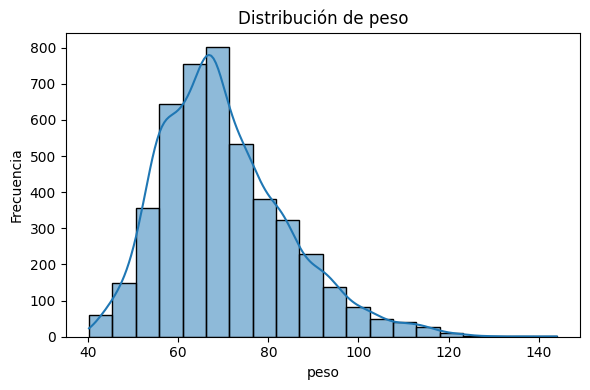

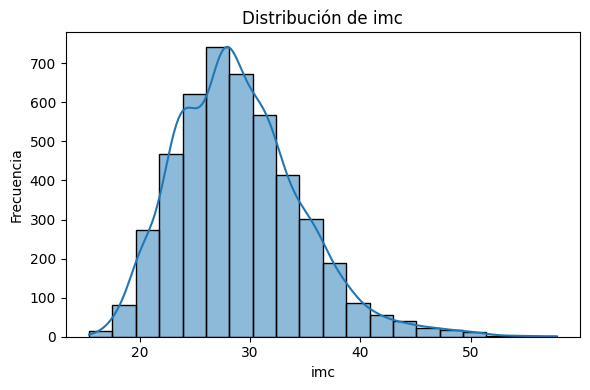

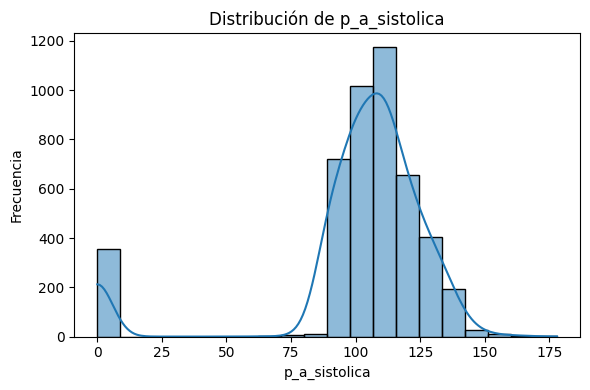

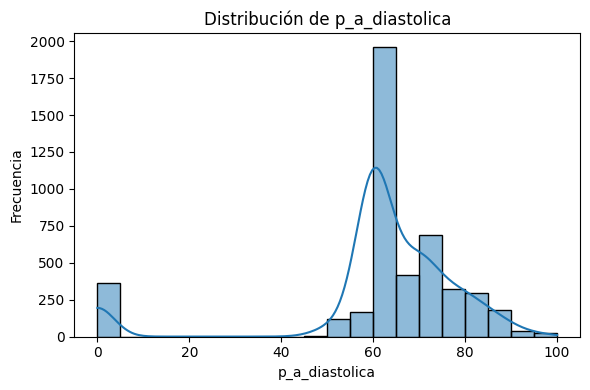

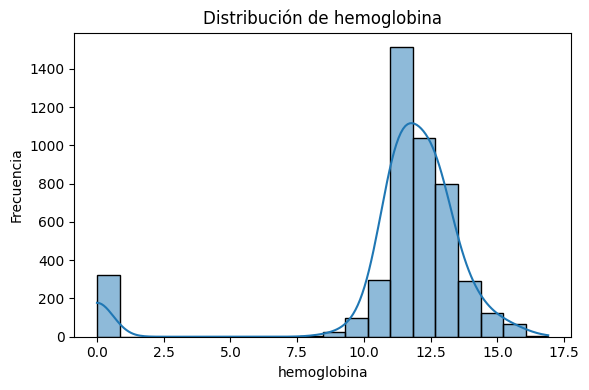

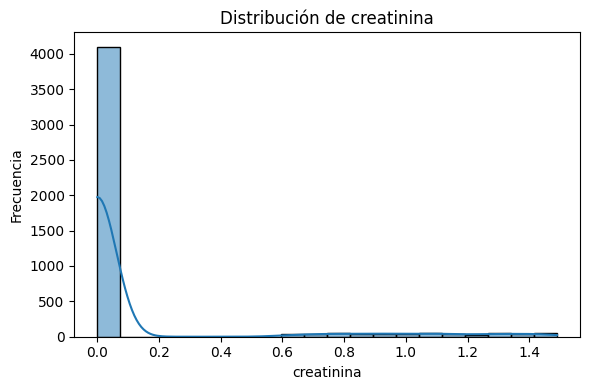

In [ ]:
# Distribución de variables numéricas

variables_numericas = [
    "edad",
    "edad_gestacion",
    "talla",
    "peso",
    "imc",
    "p_a_sistolica",
    "p_a_diastolica",
    "hemoglobina",
    "creatinina"
]

for col in variables_numericas:

    plt.figure(figsize=(6,4))

    sns.histplot(
        data=df,
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()

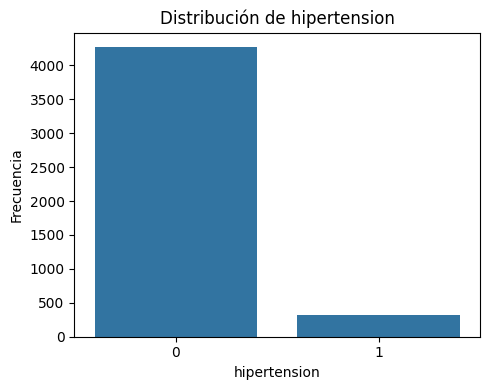

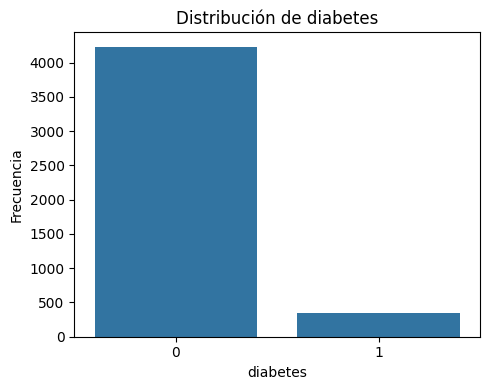

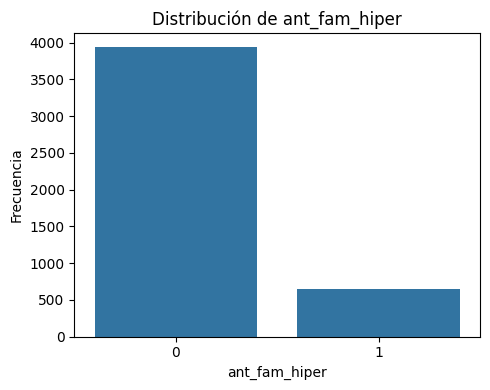

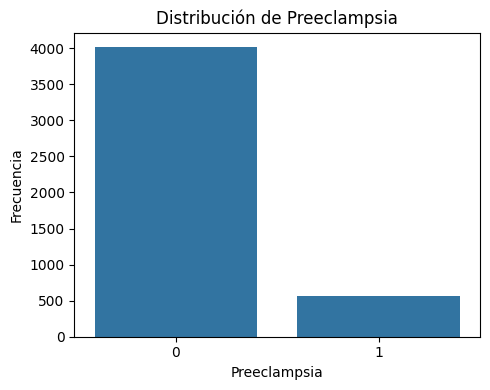

In [ ]:
# Distribución de variables binarias

variables_binarias = [
    "hipertension",
    "diabetes",
    "ant_fam_hiper",
    "Preeclampsia"
]

for col in variables_binarias:

    plt.figure(figsize=(5,4))

    sns.countplot(
        data=df,
        x=col
    )

    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()

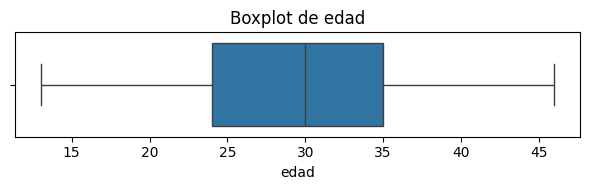

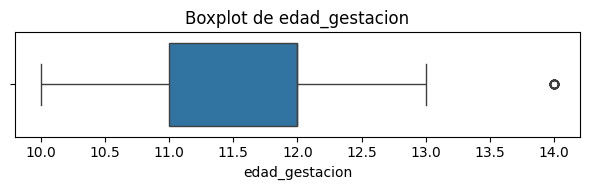

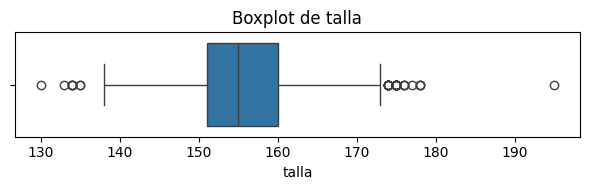

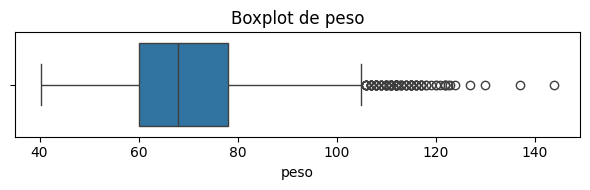

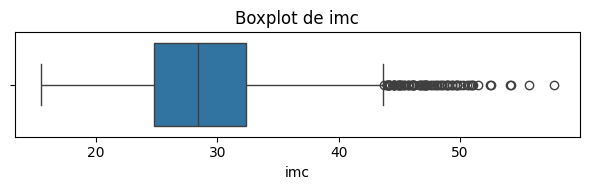

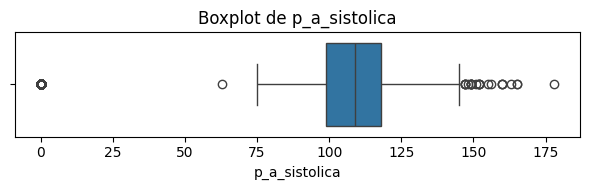

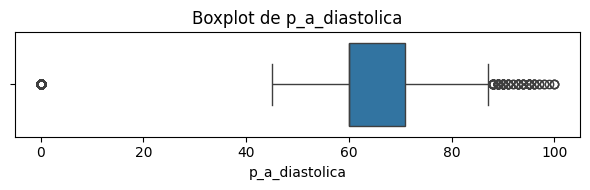

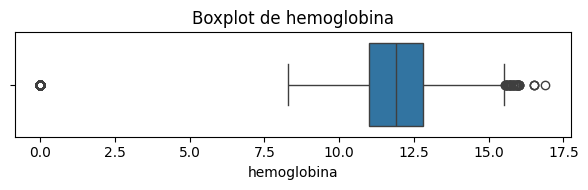

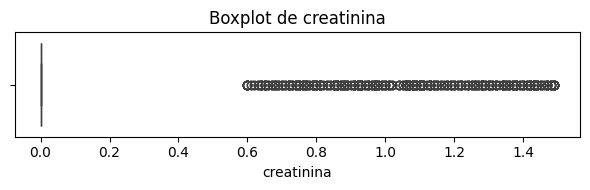

In [ ]:
# Detección visual de outliers

variables_numericas = [
    "edad",
    "edad_gestacion",
    "talla",
    "peso",
    "imc",
    "p_a_sistolica",
    "p_a_diastolica",
    "hemoglobina",
    "creatinina"
]

for col in variables_numericas:

    plt.figure(figsize=(6,2))

    sns.boxplot(
        x=df[col]
    )

    plt.title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

#### 2.3 Correlaciones y cruces de variables


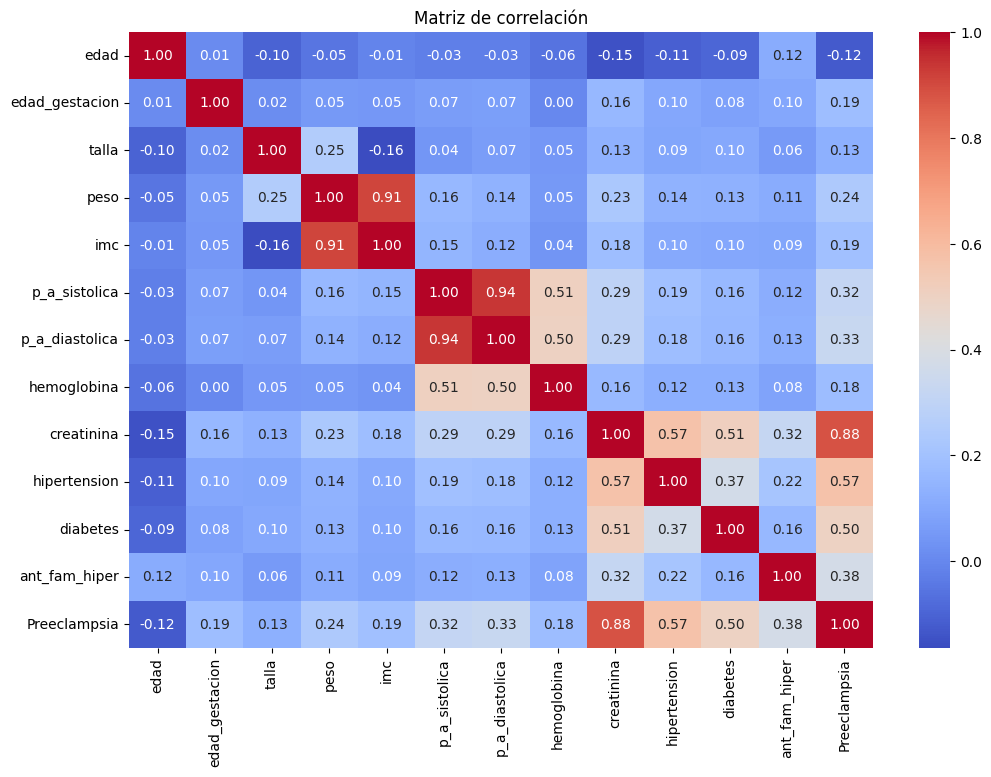

In [ ]:
# Matriz de correlación

plt.figure(figsize=(12,8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.show()

Preeclampsia      1.000000
creatinina        0.882982
hipertension      0.568753
diabetes          0.499773
ant_fam_hiper     0.376283
p_a_diastolica    0.329945
p_a_sistolica     0.315804
peso              0.236153
imc               0.191693
edad_gestacion    0.185769
hemoglobina       0.179937
talla             0.131525
edad             -0.123165
Name: Preeclampsia, dtype: float64


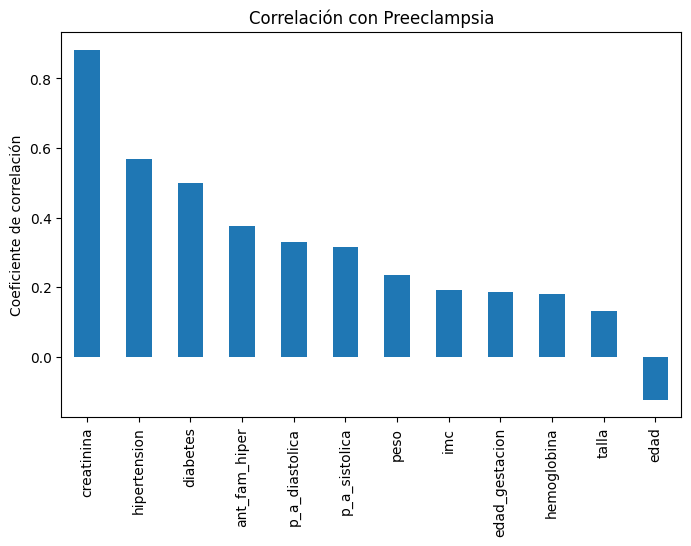

In [ ]:
# Correlación con la variable objetivo

corr_target = corr["Preeclampsia"].sort_values(ascending=False)

print(corr_target)

plt.figure(figsize=(8,5))

corr_target.drop("Preeclampsia").plot(
    kind="bar"
)

plt.title("Correlación con Preeclampsia")
plt.ylabel("Coeficiente de correlación")
plt.show()

Preeclampsia     0    1
hipertension           
0             3955  311
1               58  255


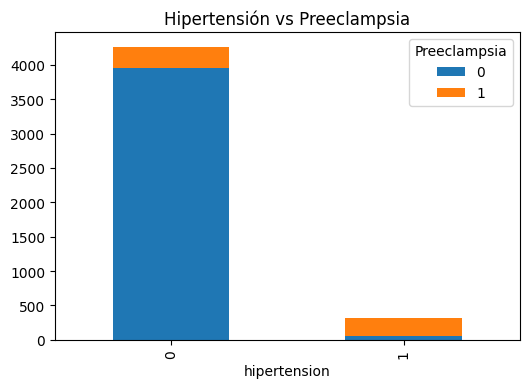

Preeclampsia     0    1
diabetes               
0             3907  323
1              106  243


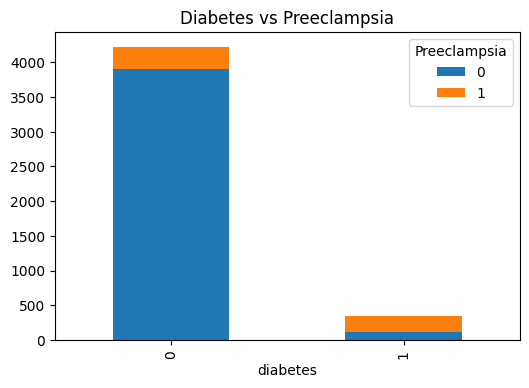

Preeclampsia      0    1
ant_fam_hiper           
0              3648  290
1               365  276


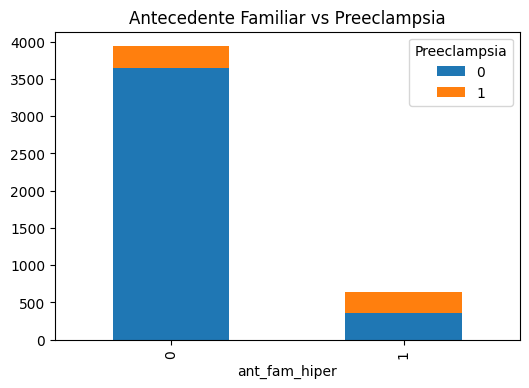

In [ ]:
# Cruce de variables binarias

# Hipertensión vs Preeclampsia
tabla_hip = pd.crosstab(
    df["hipertension"],
    df["Preeclampsia"]
)

print(tabla_hip)

tabla_hip.plot(
    kind="bar",
    stacked=True,
    figsize=(6,4)
)

plt.title("Hipertensión vs Preeclampsia")
plt.show()

# Diabetes vs Preeclampsia
tabla_dm = pd.crosstab(
    df["diabetes"],
    df["Preeclampsia"]
)

print(tabla_dm)

tabla_dm.plot(
    kind="bar",
    stacked=True,
    figsize=(6,4)
)

plt.title("Diabetes vs Preeclampsia")
plt.show()

# Antecedente familiar vs Preeclampsia
tabla_fam = pd.crosstab(
    df["ant_fam_hiper"],
    df["Preeclampsia"]
)

print(tabla_fam)
tabla_fam.plot(
    kind="bar",
    stacked=True,
    figsize=(6,4)
)

plt.title("Antecedente Familiar vs Preeclampsia")
plt.show()



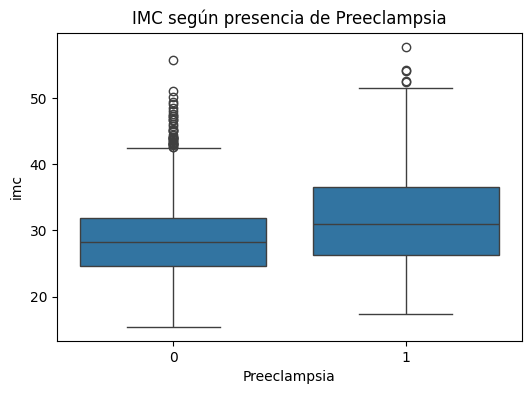

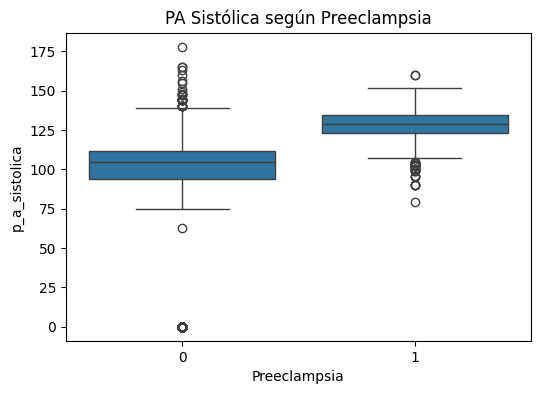

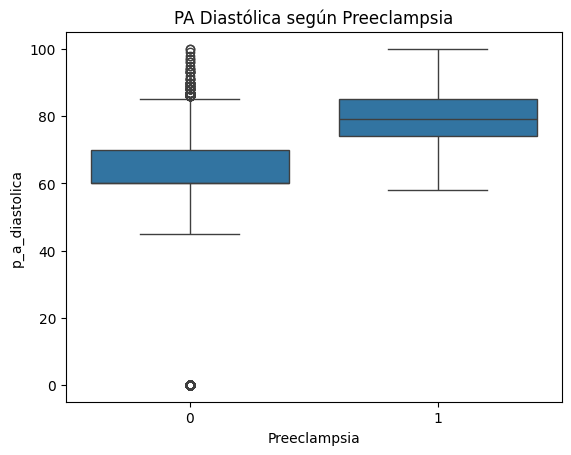

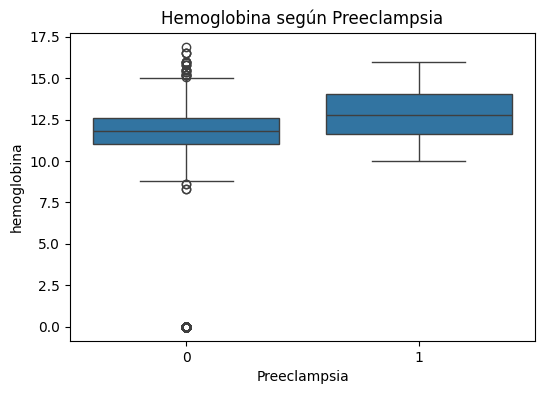

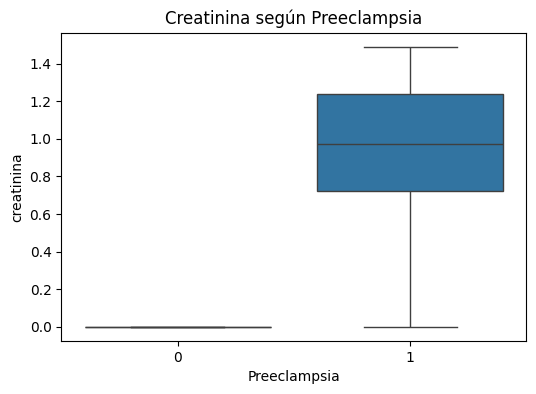

In [ ]:
#  Comparación de variables numéricas por clase

# IMC
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="Preeclampsia",
    y="imc"
)

plt.title("IMC según presencia de Preeclampsia")
plt.show()

# Presión Sistólica
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="Preeclampsia",
    y="p_a_sistolica"
)

plt.title("PA Sistólica según Preeclampsia")
plt.show()

# Presión Diastólica
sns.boxplot(
    data=df,
    x="Preeclampsia",
    y="p_a_diastolica"
)

plt.title("PA Diastólica según Preeclampsia")
plt.show()

# Hemoglobina
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="Preeclampsia",
    y="hemoglobina"
)

plt.title("Hemoglobina según Preeclampsia")
plt.show()

# Creatinina
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="Preeclampsia",
    y="creatinina"
)

plt.title("Creatinina según Preeclampsia")
plt.show()

#### 2.4 Diagnóstico de calidad inicial

In [ ]:
# Valores faltantes
# ------------------------------------------------------------

print("\n*** Valores faltantes (NaN) ***")

na_counts = df.isna().sum().sort_values(ascending=False)
na_pct = (na_counts / len(df) * 100).round(2)

quality_missing = pd.DataFrame({
    'missing': na_counts,
    'missing_%': na_pct
})

display(quality_missing)


*** Valores faltantes (NaN) ***


,missing,missing_%
edad,0,0.0
edad_gestacion,0,0.0
talla,0,0.0
peso,0,0.0
imc,0,0.0
p_a_sistolica,0,0.0
p_a_diastolica,0,0.0
hemoglobina,0,0.0
creatinina,0,0.0
hipertension,0,0.0


In [ ]:
# Registros duplicados
# ------------------------------------------------------------

print("\n*** Registros duplicados ***")

duplicados = df.duplicated().sum()

print(f"Duplicados encontrados: {duplicados}")


*** Registros duplicados ***
Duplicados encontrados: 5


In [ ]:
# Rangos clínicos
# ------------------------------------------------------------

print("\n*** Rangos clínicos de las variables ***")

variables = [
    "edad",
    "edad_gestacion",
    "talla",
    "peso",
    "imc",
    "p_a_sistolica",
    "p_a_diastolica",
    "hemoglobina",
    "creatinina",
    "hipertension",
    "diabetes",
    "ant_fam_hiper",
    "Preeclampsia"
]

for col in variables:

    print(
        f"{col}: "
        f"mín={df[col].min()} | "
        f"máx={df[col].max()}"
    )


*** Rangos clínicos de las variables ***
edad: mín=13 | máx=46
edad_gestacion: mín=10 | máx=14
talla: mín=130.0 | máx=195.0
peso: mín=40.2 | máx=144.0
imc: mín=15.43 | máx=57.77
p_a_sistolica: mín=0 | máx=178
p_a_diastolica: mín=0 | máx=100
hemoglobina: mín=0.0 | máx=16.9
creatinina: mín=0.0 | máx=1.49
hipertension: mín=0 | máx=1
diabetes: mín=0 | máx=1
ant_fam_hiper: mín=0 | máx=1
Preeclampsia: mín=0 | máx=1


In [ ]:
# Valores fisiológicamente no plausibles
# ------------------------------------------------------------

print("\n*** Valores iguales a cero ***")

columnas_revisar = [
    "hemoglobina",
    "creatinina",
    "p_a_sistolica",
    "p_a_diastolica"
]

for col in columnas_revisar:

    cantidad = (df[col] == 0).sum()

    porcentaje = round(
        cantidad / len(df) * 100,
        2
    )

    print(
        f"{col}: "
        f"{cantidad} registros "
        f"({porcentaje}%)"
    )


*** Valores iguales a cero ***
hemoglobina: 322 registros (7.03%)
creatinina: 4098 registros (89.5%)
p_a_sistolica: 355 registros (7.75%)
p_a_diastolica: 363 registros (7.93%)



*** Distribución de Preeclampsia ***
Preeclampsia
0    4013
1     566
Name: count, dtype: int64

*** Porcentaje por clase ***
Preeclampsia
0    87.64
1    12.36
Name: proportion, dtype: float64


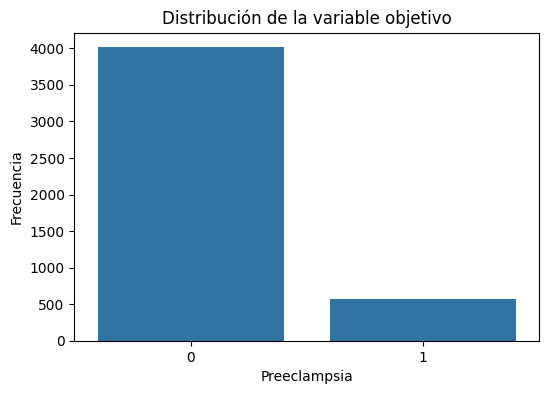

In [ ]:
# Distribución de la variable objetivo
# ------------------------------------------------------------

print("\n*** Distribución de Preeclampsia ***")

print(df["Preeclampsia"].value_counts())

print("\n*** Porcentaje por clase ***")

print(
    round(
        df["Preeclampsia"]
        .value_counts(normalize=True) * 100,
        2
    )
)

plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Preeclampsia"
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Preeclampsia")
plt.ylabel("Frecuencia")

plt.show()

#### 2.5 Pruebas estadísticas exploratorias

In [ ]:
# Prueba Mann-Whitney para variables numéricas

numeric_features_eda = [
    "edad",
    "edad_gestacion",
    "talla",
    "peso",
    "imc",
    "p_a_sistolica",
    "p_a_diastolica",
    "hemoglobina",
    "creatinina"
]

mann_results = []

for col in numeric_features_eda:
    grupo_0 = df[df["Preeclampsia"] == 0][col]
    grupo_1 = df[df["Preeclampsia"] == 1][col]

    stat, p_value = mannwhitneyu(
        grupo_0,
        grupo_1,
        alternative="two-sided"
    )

    mann_results.append({
        "Variable": col,
        "Mediana_No_Preeclampsia": grupo_0.median(),
        "Mediana_Preeclampsia": grupo_1.median(),
        "p_value": p_value
    })

mann_df = pd.DataFrame(mann_results)
mann_df["Significativo"] = mann_df["p_value"] < 0.05

display(mann_df.sort_values("p_value"))

,Variable,Mediana_No_Preeclampsia,Mediana_Preeclampsia,p_value,Significativo
8,creatinina,0.00,0.970,0.000000e+00,True
5,p_a_sistolica,105.00,129.000,1.945429e-234,True
6,p_a_diastolica,60.00,79.000,1.393001e-223,True
7,hemoglobina,11.80,12.795,1.320195e-44,True
3,peso,67.00,77.000,5.484396e-34,True
1,edad_gestacion,11.00,12.000,2.961670e-29,True
4,imc,28.23,30.910,1.655073e-20,True
0,edad,31.00,27.000,2.065603e-17,True
2,talla,155.00,155.000,9.565658e-12,True


In [ ]:
# Chi-cuadrado para variables binarias

binary_features_eda = [
    "hipertension",
    "diabetes",
    "ant_fam_hiper"
]

chi_results = []

for col in binary_features_eda:
    tabla = pd.crosstab(df[col], df["Preeclampsia"])

    chi2, p_value, dof, expected = chi2_contingency(tabla)

    chi_results.append({
        "Variable": col,
        "Chi2": chi2,
        "p_value": p_value,
        "Significativo": p_value < 0.05
    })

chi_df = pd.DataFrame(chi_results)

display(chi_df.sort_values("p_value"))

,Variable,Chi2,p_value,Significativo
0,hipertension,1474.372988,0.000000e+00,True
1,diabetes,1137.995274,1.823707e-249,True
2,ant_fam_hiper,645.043510,2.673354e-142,True


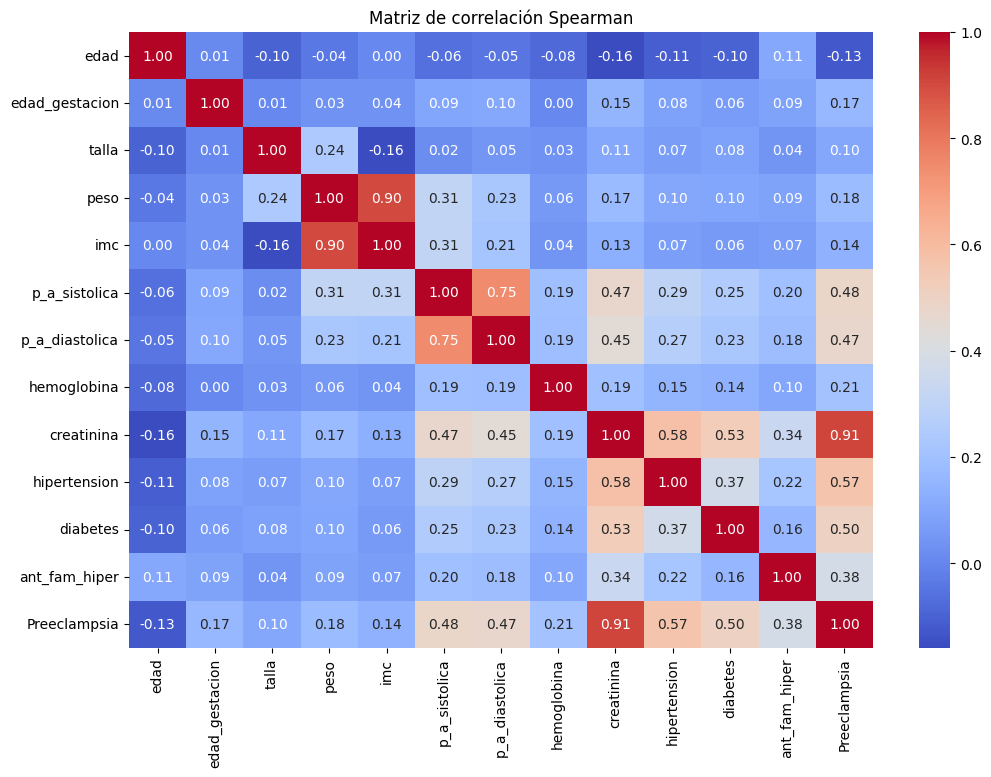

,Preeclampsia
Preeclampsia,1.000000
creatinina,0.910380
hipertension,0.568753
diabetes,0.499773
p_a_sistolica,0.483193
p_a_diastolica,0.471770
ant_fam_hiper,0.376283
hemoglobina,0.207089
peso,0.179626
edad_gestacion,0.165950


In [ ]:
# Correlación Spearman

corr_spearman = df.corr(
    method="spearman",
    numeric_only=True
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación Spearman")
plt.show()

corr_target_spearman = corr_spearman["Preeclampsia"].sort_values(
    ascending=False
)

display(corr_target_spearman)

#### 2.6 Hallazgos de la exploración

**1. Características generales del conjunto de datos**

- El conjunto de datos procedente de la Red Integrada de Salud Huarochirí (RIS Huarochirí) contiene **4,579 registros clínicos y 13 columnas**, correspondientes a 12 variables predictoras y una variable objetivo.
- Las variables comprenden características demográficas, obstétricas, antropométricas, mediciones de presión arterial, indicadores bioquímicos y antecedentes clínicos.
- Todas las variables se encuentran representadas mediante datos numéricos, incluidas las variables binarias codificadas como 0 y 1.
- Las edades gestacionales están comprendidas entre las **10 y 14 semanas**, con una media de 11.47 ± 0.92 semanas y una mediana de 12 semanas.
- La edad materna presentó una media de 29.71 ± 6.89 años, mientras que el IMC registró una media de 29.02 ± 5.71 kg/m².

**2. Distribución de la variable objetivo**

La variable objetivo `Preeclampsia` presentó la siguiente distribución antes de eliminar los registros duplicados:

- **Sin preeclampsia (0):** 4,013 registros (87.64 %).
- **Con preeclampsia (1):** 566 registros (12.36 %).
- **Imbalance Ratio (IR):** 7.09:1.

Esta distribución evidencia un desbalance de clases, caracterizado por una menor representación de los casos positivos. En consecuencia, durante el entrenamiento será necesario evaluar estrategias específicas para abordar este desbalance, considerando la presencia de variables numéricas continuas y binarias.

**3. Variables con mayor asociación con preeclampsia**

El análisis de correlación de Pearson identificó las siguientes variables con mayor asociación positiva con el desenlace:

- **Creatinina:** r = 0.8830.
- **Hipertensión:** r = 0.5688.
- **Diabetes:** r = 0.4998.
- **Antecedentes familiares de hipertensión:** r = 0.3763.
- **Presión arterial diastólica:** r = 0.3299.
- **Presión arterial sistólica:** r = 0.3158.

La creatinina presentó la mayor correlación positiva; sin embargo, este resultado requiere especial cautela debido a que el **89.50 % de los registros contiene valores iguales a cero**. Es necesario verificar si estos valores representan mediciones ausentes o errores de codificación, ya que podrían generar asociaciones artificiales con la variable objetivo.

Las pruebas U de Mann–Whitney identificaron diferencias estadísticamente significativas en las nueve variables numéricas analizadas (p < 0.001). Asimismo, las pruebas de Chi-cuadrado evidenciaron asociaciones estadísticamente significativas entre preeclampsia e hipertensión, diabetes y antecedentes familiares de hipertensión (p < 0.001).

Estos resultados tienen carácter exploratorio y no permiten establecer relaciones causales ni determinar de manera independiente la importancia predictiva de cada variable.

**4. Calidad de los datos**

- No se identificaron valores nulos explícitos (`NaN`) en ninguna de las 13 variables.
- Se detectaron **5 registros exactamente duplicados**, equivalentes aproximadamente al 0.11 % del conjunto original.
- Se identificaron valores iguales a cero en variables clínicas cuya validez requiere evaluación:

| Variable | Registros en 0 | Porcentaje |
|---|---:|---:|
| Hemoglobina | 322 | 7.03 % |
| Creatinina | 4,098 | 89.50 % |
| Presión arterial sistólica | 355 | 7.75 % |
| Presión arterial diastólica | 363 | 7.93 % |

Los valores iguales a cero de hemoglobina y presión arterial no representan mediciones fisiológicas válidas en las gestantes registradas, por lo que requieren tratamiento durante el preprocesamiento.

En el caso de creatinina, la elevada proporción de valores cero hace necesario investigar su origen y distribución según el desenlace antes de decidir su inclusión o exclusión del modelado.

Además, deberá verificarse que las variables predictoras correspondan a mediciones obtenidas antes del desarrollo o diagnóstico de preeclampsia, con el fin de evitar posibles problemas de fuga de información (*data leakage*).

**5. Siguientes pasos: Fase 2 — Preprocesamiento de datos**

A partir de los hallazgos identificados, se establecen las siguientes actividades para la preparación del conjunto de datos:

| Aspecto evaluado | Resultado inicial | Acción prevista para la Fase 2 |
|---|---|---|
| Registros iniciales | 4,579 | Conservar como referencia inicial |
| Registros duplicados | 5 | Eliminar duplicados exactos |
| Registros esperados tras depuración | 4,574 | Verificar dimensiones y distribución de clases |
| Desbalance inicial | 87.64 % / 12.36 % | Evaluar balanceo exclusivamente en entrenamiento |
| Creatinina en cero | 4,098 (89.50 %) | Investigar origen y evaluar inclusión o exclusión |
| PA sistólica en cero | 355 (7.75 %) | Tratar como faltantes e imputar según estrategia definida |
| PA diastólica en cero | 363 (7.93 %) | Tratar como faltantes e imputar según estrategia definida |
| Hemoglobina en cero | 322 (7.03 %) | Tratar como faltantes e imputar según estrategia definida |
| Tipos de variables | Numéricas y binarias | Preservar su naturaleza durante el preprocesamiento |

El tratamiento de los valores faltantes y el balanceo de clases deberán ajustarse exclusivamente con los datos de entrenamiento, evitando la transferencia de información hacia los conjuntos de validación y prueba.

**Conclusión de la Fase 1**

La exploración inicial permitió caracterizar la estructura, distribución y calidad del conjunto de datos, identificando un desbalance de clases, cinco registros duplicados y valores potencialmente inválidos en variables clínicas.

Asimismo, se observaron asociaciones estadísticas entre diversas características maternas y el desenlace de preeclampsia. No obstante, la elevada proporción de ceros en creatinina y la necesidad de verificar la temporalidad de las mediciones constituyen aspectos prioritarios antes del modelado.

En conjunto, los resultados proporcionan una base para desarrollar la fase de preprocesamiento y evaluar modelos de Machine Learning y Ensemble Stacking orientados a la predicción temprana del riesgo de preeclampsia.

## **FASE 2: PREPROCESAMIENTO Y PREPARACIÓN DEL DATASET**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

### 1. Limpieza y depuración de datos

In [ ]:
# Eliminación de registros duplicados

print("Data inicial:", df.shape)

duplicados = df.duplicated().sum()

print("Duplicados encontrados:", duplicados)

df = df.drop_duplicates()

print("Data después de eliminar duplicados:", df.shape)

Data inicial: (4579, 13)
Duplicados encontrados: 5
Data después de eliminar duplicados: (4574, 13)


### 2. Tratamiento de datos faltantes

In [ ]:
# 2.1 Conversión de valores 0 a NaN
# ------------------------------------

variables_cero_nan = [
    "hemoglobina",
    "p_a_sistolica",
    "p_a_diastolica"
]

print("\nCeros antes de convertir a NaN:")

for col in variables_cero_nan:
    print(col, ":", (df[col] == 0).sum())

for col in variables_cero_nan:
    df[col] = df[col].replace(0, np.nan)

print("\nValores faltantes generados:")

print(
    df[variables_cero_nan]
    .isnull()
    .sum()
)


Ceros antes de convertir a NaN:
hemoglobina : 320
p_a_sistolica : 353
p_a_diastolica : 361

Valores faltantes generados:
hemoglobina       320
p_a_sistolica     353
p_a_diastolica    361
dtype: int64


In [ ]:
# 2.2 Creación de la Presión Arterial Media (PAM)
#------------------------------------------------

#La PAM se calcula mediante: PAM = (PAS + 2*PAD)/3

df["pam"] = (
    df["p_a_sistolica"] +
    2 * df["p_a_diastolica"]
) / 3

print("\nResumen estadístico de PAM:")

display(
    df["pam"].describe()
)

print("\nValores faltantes en PAM:")

print(
    df["pam"].isnull().sum()
)


Resumen estadístico de PAM:


,pam
count,4213.000000
mean,81.030224
std,9.857047
min,59.333333
25%,73.333333
50%,78.333333
75%,87.333333
max,126.000000



Valores faltantes en PAM:
361


La Presión Arterial Media (PAM) fue seleccionada en reemplazo de las variables presión arterial sistólica y presión arterial diastólica debido a que integra ambas mediciones en un único indicador hemodinámico ampliamente utilizado en la evaluación temprana de trastornos hipertensivos del embarazo, reduciendo además la redundancia entre variables.

La variable PAM presentó 361 valores faltantes debido a que su cálculo depende de la disponibilidad simultánea de presión sistólica y diastólica.

### 3. Selección de variables

In [ ]:
# Decisiones metodológicas:

# - Se elimina creatinina por tener 89.34% de valores faltantes.

missing_creat = df["creatinina"].eq(0).mean()*100

print(f"Porcentaje de datos faltantes en creatinina: {missing_creat:.2f}%")

# - Se eliminan talla y peso porque su información está resumida en el IMC.
# - p_a_sistolica" y p_a_diastolica", reemplazadas por PAM para utilizar un indicador clínico consolidado de presión arterial.

variables_modelo = [
    "edad",
    "edad_gestacion",
    "imc",
    "pam",
    "hemoglobina",
    "hipertension",
    "diabetes",
    "ant_fam_hiper",
    "Preeclampsia"
]

df_modelo = df[
    variables_modelo
].copy()

print("\nDataset final para modelado:")

print(df_modelo.shape)

display( df_modelo.head()
)

Porcentaje de datos faltantes en creatinina: 89.48%

Dataset final para modelado:
(4574, 9)


,edad,edad_gestacion,imc,pam,hemoglobina,hipertension,diabetes,ant_fam_hiper,Preeclampsia
0,22,12,34.16,95.666667,15.07,0,1,1,1
1,27,12,32.89,87.333333,11.83,0,0,0,1
2,32,13,33.73,101.333333,14.68,1,1,0,1
3,25,12,47.23,101.333333,11.20,0,0,0,1
4,17,11,22.35,94.000000,10.67,0,1,1,1


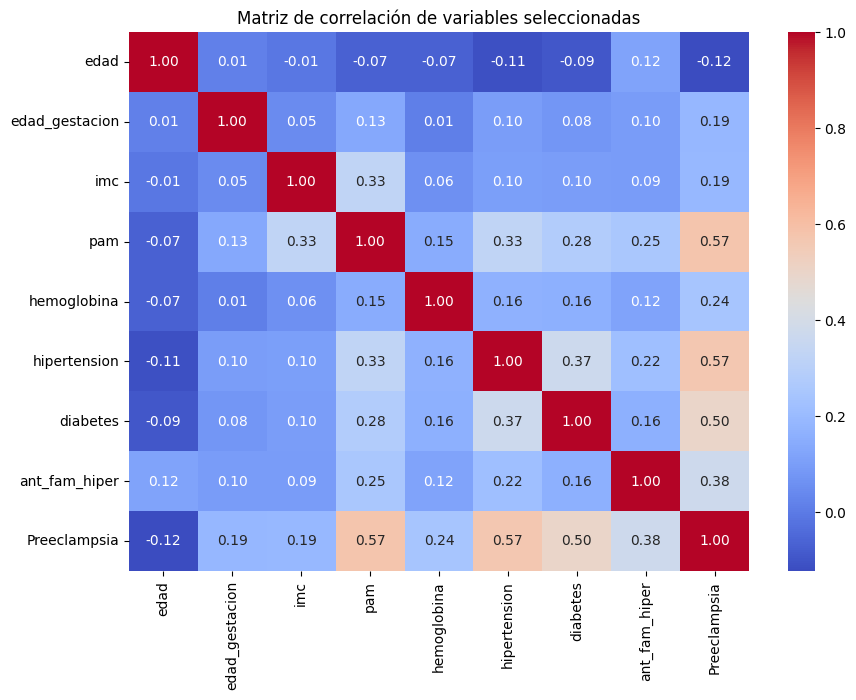

In [ ]:
# 3.1 Correlación de las variables seleccionadas
# ------------------------------------------------

plt.figure(figsize=(10,7))

corr_final = df_modelo.corr(numeric_only=True)

sns.heatmap(
    corr_final,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title(
    "Matriz de correlación de variables seleccionadas"
)

plt.show()

In [ ]:
corr_pam = df_modelo["pam"].corr(
    df_modelo["Preeclampsia"]
)

print(
    f"Correlación PAM vs Preeclampsia: {corr_pam:.3f}"
)

Correlación PAM vs Preeclampsia: 0.575


### 4. Separación de variables predictoras y objetivo

In [ ]:
X = df_modelo.drop(
    columns=["Preeclampsia"]
)

y = df_modelo["Preeclampsia"]

print("\nVariables predictoras:")

print(
    X.columns.tolist()
)

print("\nVariable objetivo:")

print(y.name)


Variables predictoras:
['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina', 'hipertension', 'diabetes', 'ant_fam_hiper']

Variable objetivo:
Preeclampsia


### 5. Definición de variables numéricas y binarias

In [ ]:
numeric_features = [
    "edad",
    "edad_gestacion",
    "imc",
    "pam",
    "hemoglobina"
]

binary_features = [
    "hipertension",
    "diabetes",
    "ant_fam_hiper"
]

print("\nVariables numéricas:")

print(numeric_features)

print("\nVariables binarias:")

print(binary_features)

print(
    "\nTotal de variables predictoras:",
    len(numeric_features) +
    len(binary_features)
)


Variables numéricas:
['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina']

Variables binarias:
['hipertension', 'diabetes', 'ant_fam_hiper']

Total de variables predictoras: 8


### 6. Construcción del pipeline de preprocesamiento

In [ ]:
# PIPELINE PARA VARIABLES NUMÉRICAS
# ============================================================

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# PIPELINE PARA VARIABLES BINARIAS
# ============================================================

binary_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    )
])

# PREPROCESADOR GENERAL
# ============================================================

preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    (
        "bin",
        binary_pipeline,
        binary_features
    )
])

print("Pipeline de preprocesamiento construido correctamente.")

Pipeline de preprocesamiento construido correctamente.


Se utilizó imputación por mediana debido a su robustez frente a valores extremos y distribuciones asimétricas frecuentes en variables clínicas.

### 7. Validación del dataset preparado

In [ ]:
print("\nValores faltantes en el dataset final:")
print(df_modelo.isnull().sum())

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

print("\nPorcentaje de clases:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nFase 2 finalizada correctamente.")


Valores faltantes en el dataset final:
edad                0
edad_gestacion      0
imc                 0
pam               361
hemoglobina       320
hipertension        0
diabetes            0
ant_fam_hiper       0
Preeclampsia        0
dtype: int64

Distribución de la variable objetivo:
Preeclampsia
0    4008
1     566
Name: count, dtype: int64

Porcentaje de clases:
Preeclampsia
0    87.63
1    12.37
Name: proportion, dtype: float64

Fase 2 finalizada correctamente.


### 8. Generación del dataset preparado

In [ ]:
# Se conserva el dataset con los valores faltantes,
# ya que la imputación será realizada posteriormente
# dentro del pipeline durante el entrenamiento.

df_modelo_preparado = df_modelo.copy()

print("Valores faltantes presentes:")

print(
    df_modelo_preparado.isnull().sum()
)

print("\nDimensiones del dataset preparado:")

print(
    df_modelo_preparado.shape
)

display(
    df_modelo_preparado.head()
)

# Guardar dataset preparado

RUTA_DATASET = "Preeclampsia_dataset_modelado.csv"

df_modelo_preparado.to_csv(
    RUTA_DATASET,
    index=False
)

print(
    f"\nDataset guardado correctamente: {RUTA_DATASET}"
)

Valores faltantes presentes:
edad                0
edad_gestacion      0
imc                 0
pam               361
hemoglobina       320
hipertension        0
diabetes            0
ant_fam_hiper       0
Preeclampsia        0
dtype: int64

Dimensiones del dataset preparado:
(4574, 9)


,edad,edad_gestacion,imc,pam,hemoglobina,hipertension,diabetes,ant_fam_hiper,Preeclampsia
0,22,12,34.16,95.666667,15.07,0,1,1,1
1,27,12,32.89,87.333333,11.83,0,0,0,1
2,32,13,33.73,101.333333,14.68,1,1,0,1
3,25,12,47.23,101.333333,11.20,0,0,0,1
4,17,11,22.35,94.000000,10.67,0,1,1,1



Dataset guardado correctamente: Preeclampsia_dataset_modelado.csv


**Resumen de decisiones**

- Se identificaron y eliminaron **5 registros duplicados**, reduciendo el conjunto de datos de 4,579 a **4,574 registros**, sin modificar las variables originales.

- Los valores iguales a cero en **hemoglobina, presión arterial sistólica y presión arterial diastólica** fueron considerados mediciones clínicamente no válidas y convertidos a valores faltantes (`NaN`). Después de la depuración, se identificaron **320 valores faltantes en hemoglobina (7.00 %), 353 en presión arterial sistólica (7.72 %) y 361 en presión arterial diastólica (7.89 %)**.

- Se creó la variable **presión arterial media (PAM)** mediante la fórmula `PAM = (PAS + 2 × PAD) / 3`, integrando las mediciones de presión arterial sistólica y diastólica en un único indicador hemodinámico. La PAM presentó una **correlación positiva con el desenlace de preeclampsia (r = 0.575)**, calculada mediante el coeficiente de Pearson. Se conservaron **4,213 valores disponibles y 361 valores faltantes (7.89 %)**.

- Se excluyó la variable **creatinina**, debido a que el **89.48 % de los registros depurados presentaba valores iguales a cero**, cuya validez y disponibilidad no pudieron establecerse. Esta decisión permitió evitar la incorporación de una característica con elevada incertidumbre sobre la calidad de sus mediciones.

- Se excluyeron **talla y peso** como predictores independientes, conservando el **índice de masa corporal (IMC)** como indicador antropométrico derivado, con el propósito de reducir la redundancia entre características relacionadas.

- Las variables **presión arterial sistólica y diastólica** fueron reemplazadas por la PAM en el conjunto de predictores, con el objetivo de representar la información hemodinámica mediante una característica consolidada.

- Como resultado de la selección, se definieron **8 variables predictoras y una variable objetivo (`Preeclampsia`)**. Las características seleccionadas comprenden cinco variables numéricas (edad, edad gestacional, IMC, PAM y hemoglobina) y tres variables binarias (hipertensión, diabetes y antecedentes familiares de hipertensión).

- El análisis de correlación identificó una **asociación positiva entre PAM y preeclampsia (r = 0.575)**. La matriz de correlación permitió explorar posibles relaciones lineales entre los predictores seleccionados. No obstante, la ausencia de multicolinealidad elevada deberá confirmarse mediante la revisión de los coeficientes correspondientes.

- Se construyó un **pipeline de preprocesamiento** mediante `Pipeline` y `ColumnTransformer` de scikit-learn, incorporando **imputación por mediana (`SimpleImputer`) y estandarización (`StandardScaler`)** para las variables numéricas, así como **imputación por moda** para las variables binarias. El pipeline quedó configurado, pero todavía no fue ajustado a los datos.

- Después de eliminar los duplicados, la variable objetivo presentó **4,008 registros sin preeclampsia (87.63 %) y 566 con preeclampsia (12.37 %)**, manteniéndose un desbalance de clases con una relación aproximada de **7.08:1**. Este desbalance será abordado durante la experimentación mediante **SMOTENC**, considerando la naturaleza mixta de las variables y aplicando el sobremuestreo exclusivamente sobre los datos de entrenamiento.

- Finalmente, se generó el archivo `Preeclampsia_dataset_modelado.csv`, compuesto por **4,574 registros y 9 columnas**, conservando los **361 valores faltantes de PAM y 320 de hemoglobina**. La imputación y estandarización se realizarán posteriormente mediante un pipeline ajustado exclusivamente con datos de entrenamiento, evitando la fuga de información hacia los conjuntos de validación y prueba.

**Resultado:** Se obtuvo un conjunto de datos depurado y estructurado, con ocho variables predictoras seleccionadas y un pipeline de preprocesamiento configurado. El dataset quedó preparado para la **Fase 3: Entrenamiento y Experimentación**, que comprenderá la división estratificada de los datos, el tratamiento del desbalance mediante SMOTENC y el desarrollo y evaluación de los modelos de Machine Learning y Ensemble Stacking.

✅ **Resultado:** Dataset depurado, estructurado y preparado para la Fase 3: Entrenamiento y Experimentación.

## **FASE 3: ENTRENAMIENTO Y EXPERIMENTACIÓN**

In [ ]:
!pip install catboost -q

In [ ]:
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Carga del dataset
RUTA_DATASET = "Preeclampsia_dataset_modelado.csv"
df_modelo_preparado = pd.read_csv(RUTA_DATASET)

print("Dataset cargado correctamente:")
print(df_modelo_preparado.shape)

display(df_modelo_preparado.head())

# SEPARACIÓN DE PREDICTORES Y VARIABLE OBJETIVO

X = df_modelo_preparado.drop(columns=["Preeclampsia"])
y = df_modelo_preparado["Preeclampsia"].astype(int)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

# VERIFICACIONES DE CONTROL
print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nClases presentes en la variable objetivo:")
print(sorted(y.unique()))

assert set(y.unique()).issubset({0, 1}), \
    "La variable objetivo contiene valores distintos de 0 y 1."

assert len(X) == len(y), \
    "X e y tienen diferente número de registros."

print("\nVerificación inicial completada correctamente.")

Dataset cargado correctamente:
(4574, 9)


,edad,edad_gestacion,imc,pam,hemoglobina,hipertension,diabetes,ant_fam_hiper,Preeclampsia
0,22,12,34.16,95.666667,15.07,0,1,1,1
1,27,12,32.89,87.333333,11.83,0,0,0,1
2,32,13,33.73,101.333333,14.68,1,1,0,1
3,25,12,47.23,101.333333,11.20,0,0,0,1
4,17,11,22.35,94.000000,10.67,0,1,1,1



Variables predictoras:
['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina', 'hipertension', 'diabetes', 'ant_fam_hiper']

Variable objetivo:
Preeclampsia

Dimensiones de X: (4574, 8)
Dimensiones de y: (4574,)

Clases presentes en la variable objetivo:
[np.int64(0), np.int64(1)]

Verificación inicial completada correctamente.


### 1. División del conjunto de datos

In [ ]:
# División de datos: Train = 70% / Validation = 15% / Test = 15%

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDistribución Train:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\nDistribución Validation:")
print(y_val.value_counts(normalize=True).round(4) * 100)

print("\nDistribución Test:")
print(y_test.value_counts(normalize=True).round(4) * 100)

Train: (3201, 8)
Validation: (686, 8)
Test: (687, 8)

Distribución Train:
Preeclampsia
0    87.63
1    12.37
Name: proportion, dtype: float64

Distribución Validation:
Preeclampsia
0    87.61
1    12.39
Name: proportion, dtype: float64

Distribución Test:
Preeclampsia
0    87.63
1    12.37
Name: proportion, dtype: float64


### 2. Validación cruzada y métricas

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}
print("Validación cruzada configurada correctamente.")

Validación cruzada configurada correctamente.


### 3. Pipeline con preprocesamiento y balanceo de clases

Esta visualización tiene fines descriptivos; en el entrenamiento formal, SMOTE se aplica dentro del pipeline para evitar fuga de información.

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import (
    SMOTE,
    BorderlineSMOTE,
    ADASYN,
    SMOTENC
)
from imblearn.combine import SMOTEENN

# 1. VERIFICAR VARIABLES Y PREPROCESADOR
# ------------------------------------------------------------

numeric_features = [
    "edad",
    "edad_gestacion",
    "imc",
    "pam",
    "hemoglobina"
]

binary_features = [
    "hipertension",
    "diabetes",
    "ant_fam_hiper"
]

feature_names = numeric_features + binary_features

assert list(X_train.columns) == feature_names

# El ColumnTransformer definido en Fase 2 ordena:
# 5 numéricas + 3 binarias

categorical_indices = [5, 6, 7]

assert len(feature_names) == 8

# 2. MODELO DE REFERENCIA
# ------------------------------------------------------------

modelo_base_balanceo = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight=None,
    n_jobs=1
)

# 3. DEFINIR ESTRATEGIAS DE BALANCEO
# ------------------------------------------------------------

balanceadores = {
    "Sin balanceo": None,

    "SMOTE": SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=3
    ),

    "BorderlineSMOTE": BorderlineSMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=3
    ),

    "ADASYN": ADASYN(
        random_state=RANDOM_STATE,
        n_neighbors=3
    ),

    "SMOTENC": SMOTENC(
        categorical_features=categorical_indices,
        random_state=RANDOM_STATE,
        k_neighbors=3
    ),

    "SMOTEENN": SMOTEENN(
        smote=SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=3
        ),
        random_state=RANDOM_STATE
    )
}

# 4. VALIDACIÓN CRUZADA
# ------------------------------------------------------------

resultados_balanceo = []

for nombre_bal, balanceador in balanceadores.items():

    print("\n========================================")
    print("TÉCNICA:", nombre_bal)
    print("========================================")

    pasos = [
        ("preprocessor", clone(preprocessor))
    ]

    if balanceador is not None:
        pasos.append(
            ("balanceo", clone(balanceador))
        )

    pasos.append(
        ("model", clone(modelo_base_balanceo))
    )

    pipe_bal = ImbPipeline(pasos)

    scores = cross_validate(
        pipe_bal,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    resultado = {
        "Tecnica": nombre_bal
    }

    metricas = {
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1": "f1",
        "F1_macro": "f1_macro",
        "ROC_AUC": "roc_auc",
        "AP": "pr_auc"
    }

    for nombre_metrica, clave in metricas.items():

        valores = scores[f"test_{clave}"]

        resultado[f"{nombre_metrica}_mean"] = (
            valores.mean()
        )

        resultado[f"{nombre_metrica}_std"] = (
            valores.std()
        )

    resultados_balanceo.append(resultado)

    print(        f"Accuracy: {resultado['Accuracy_mean']:.4f}"
    )
    print(        f"Precision: {resultado['Precision_mean']:.4f}"
    )
    print(        f"Recall: {resultado['Recall_mean']:.4f}"
    )
    print(        f"F1-score: {resultado['F1_mean']:.4f}"
    )
    print(        f"Macro-F1: {resultado['F1_macro_mean']:.4f}"
    )
    print(        f"ROC-AUC: {resultado['ROC_AUC_mean']:.4f}"
    )
    print(        f"Average Precision: {resultado['AP_mean']:.4f}"
    )

# 5. TABLA COMPLETA
# ------------------------------------------------------------

balanceo_df = pd.DataFrame(resultados_balanceo)

balanceo_df = (
    balanceo_df
    .sort_values(
        by="F1_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("COMPARACIÓN COMPLETA DE BALANCEO")
print("========================================")

display(balanceo_df.round(4))

# 6. COMPARACIÓN DE MÉTRICAS PRINCIPALES
# ------------------------------------------------------------

columnas_resumen = [
    "Tecnica",
    "Precision_mean",
    "Recall_mean",
    "F1_mean",
    "F1_macro_mean",
    "ROC_AUC_mean",
    "AP_mean"
]

print("\n========================================")
print("RESUMEN DE MÉTRICAS PRINCIPALES")
print("========================================")

display(
    balanceo_df[columnas_resumen].round(4)
)

# 7. IDENTIFICAR MEJORES RESULTADOS POR MÉTRICA
# ------------------------------------------------------------

print("\n========================================")
print("MEJOR TÉCNICA SEGÚN CADA MÉTRICA")
print("========================================")

for metrica in [
    "Recall_mean",
    "F1_mean",
    "AP_mean"
]:
    mejor = balanceo_df.loc[
        balanceo_df[metrica].idxmax()
    ]

    print(
        f"{metrica}: "
        f"{mejor['Tecnica']} "
        f"({mejor[metrica]:.4f})"
    )

print("\nComparación finalizada.")
print(
    "La selección definitiva requiere considerar "
    "el objetivo clínico y la validez del remuestreo."
)



TÉCNICA: Sin balanceo
Accuracy: 0.9641
Precision: 0.9092
Recall: 0.7877
F1-score: 0.8425
Macro-F1: 0.9111
ROC-AUC: 0.9715
Average Precision: 0.9137

TÉCNICA: SMOTE
Accuracy: 0.9625
Precision: 0.8706
Recall: 0.8179
F1-score: 0.8422
Macro-F1: 0.9105
ROC-AUC: 0.9704
Average Precision: 0.9083

TÉCNICA: BorderlineSMOTE
Accuracy: 0.9619
Precision: 0.8719
Recall: 0.8129
F1-score: 0.8385
Macro-F1: 0.9085
ROC-AUC: 0.9700
Average Precision: 0.9026

TÉCNICA: ADASYN
Accuracy: 0.9594
Precision: 0.8544
Recall: 0.8129
F1-score: 0.8301
Macro-F1: 0.9035
ROC-AUC: 0.9673
Average Precision: 0.9003

TÉCNICA: SMOTENC
Accuracy: 0.9606
Precision: 0.8458
Recall: 0.8331
F1-score: 0.8385
Macro-F1: 0.9080
ROC-AUC: 0.9700
Average Precision: 0.9062

TÉCNICA: SMOTEENN
Accuracy: 0.9485
Precision: 0.7606
Recall: 0.8509
F1-score: 0.8022
Macro-F1: 0.8863
ROC-AUC: 0.9691
Average Precision: 0.8994

COMPARACIÓN COMPLETA DE BALANCEO


,Tecnica,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,F1_macro_mean,F1_macro_std,ROC_AUC_mean,ROC_AUC_std,AP_mean,AP_std
0,Sin balanceo,0.9641,0.0089,0.9092,0.0121,0.7877,0.0735,0.8425,0.0449,0.9111,0.0249,0.9715,0.0099,0.9137,0.0344
1,SMOTE,0.9625,0.0088,0.8706,0.0209,0.8179,0.0690,0.8422,0.0424,0.9105,0.0237,0.9704,0.0087,0.9083,0.0312
2,BorderlineSMOTE,0.9619,0.0084,0.8719,0.0274,0.8129,0.0821,0.8385,0.0434,0.9085,0.0240,0.9700,0.0075,0.9026,0.0284
3,SMOTENC,0.9606,0.0076,0.8458,0.0158,0.8331,0.0620,0.8385,0.0367,0.9080,0.0204,0.9700,0.0104,0.9062,0.0300
4,ADASYN,0.9594,0.0059,0.8544,0.0230,0.8129,0.0789,0.8301,0.0351,0.9035,0.0191,0.9673,0.0090,0.9003,0.0288
5,SMOTEENN,0.9485,0.0080,0.7606,0.0212,0.8509,0.0645,0.8022,0.0362,0.8863,0.0203,0.9691,0.0077,0.8994,0.0319



RESUMEN DE MÉTRICAS PRINCIPALES


,Tecnica,Precision_mean,Recall_mean,F1_mean,F1_macro_mean,ROC_AUC_mean,AP_mean
0,Sin balanceo,0.9092,0.7877,0.8425,0.9111,0.9715,0.9137
1,SMOTE,0.8706,0.8179,0.8422,0.9105,0.9704,0.9083
2,BorderlineSMOTE,0.8719,0.8129,0.8385,0.9085,0.9700,0.9026
3,SMOTENC,0.8458,0.8331,0.8385,0.9080,0.9700,0.9062
4,ADASYN,0.8544,0.8129,0.8301,0.9035,0.9673,0.9003
5,SMOTEENN,0.7606,0.8509,0.8022,0.8863,0.9691,0.8994



MEJOR TÉCNICA SEGÚN CADA MÉTRICA
Recall_mean: SMOTEENN (0.8509)
F1_mean: Sin balanceo (0.8425)
AP_mean: Sin balanceo (0.9137)

Comparación finalizada.
La selección definitiva requiere considerar el objetivo clínico y la validez del remuestreo.


**Selección de la estrategia de balanceo**

Considerando que el objetivo principal del estudio es favorecer la identificación temprana de gestantes con riesgo de preeclampsia y reducir los falsos negativos, se priorizó la **sensibilidad (Recall)**, junto con la preservación de la naturaleza de las variables clínicas durante el remuestreo.

Aunque **SMOTEENN** obtuvo el mayor Recall medio (0.8509), presentó una menor Precision (0.7606) y un F1-score de 0.8022, evidenciando un compromiso entre la identificación de casos positivos y la precisión de las predicciones.

Por su parte, **SMOTENC** alcanzó un Recall de 0.8331, una Precision de 0.8458 y un F1-score de 0.8385. Asimismo, obtuvo un ROC-AUC de 0.9700 y una Average Precision (AP) de 0.9062, mostrando un desempeño competitivo en las métricas evaluadas.

A diferencia de las técnicas de sobremuestreo convencionales, SMOTENC permite identificar explícitamente las **tres variables binarias como categóricas**, preservando su naturaleza durante la generación de observaciones sintéticas y evitando la interpolación numérica directa de dichas características.

En consecuencia, se seleccionó **SMOTENC como estrategia de balanceo para las siguientes etapas experimentales**, considerando su compatibilidad con las cinco variables numéricas y tres binarias del conjunto de datos, así como el equilibrio observado entre sensibilidad, precisión y F1-score.

Esta selección se fundamenta en los resultados descriptivos de la validación cruzada y en criterios metodológicos, sin asumir superioridad estadística frente a las demás estrategias. Asimismo, no garantiza que el modelo final presente el menor número de falsos negativos, dado que su desempeño dependerá también de los clasificadores utilizados, sus hiperparámetros y el umbral de decisión.

BALANCEO DE CLASES CON SMOTENC

Distribución antes de SMOTENC:
Preeclampsia
0    2805
1     396
Name: count, dtype: int64

Distribución después de SMOTENC:
Preeclampsia
0    2805
1    2805
Name: count, dtype: int64

Registros originales en Train: 3201
Registros después del balanceo: 5610
Registros sintéticos añadidos: 2409

VERIFICACIÓN DE VARIABLES BINARIAS
hipertension: [0. 1.]
diabetes: [0. 1.]
ant_fam_hiper: [0. 1.]

Variables binarias verificadas correctamente.


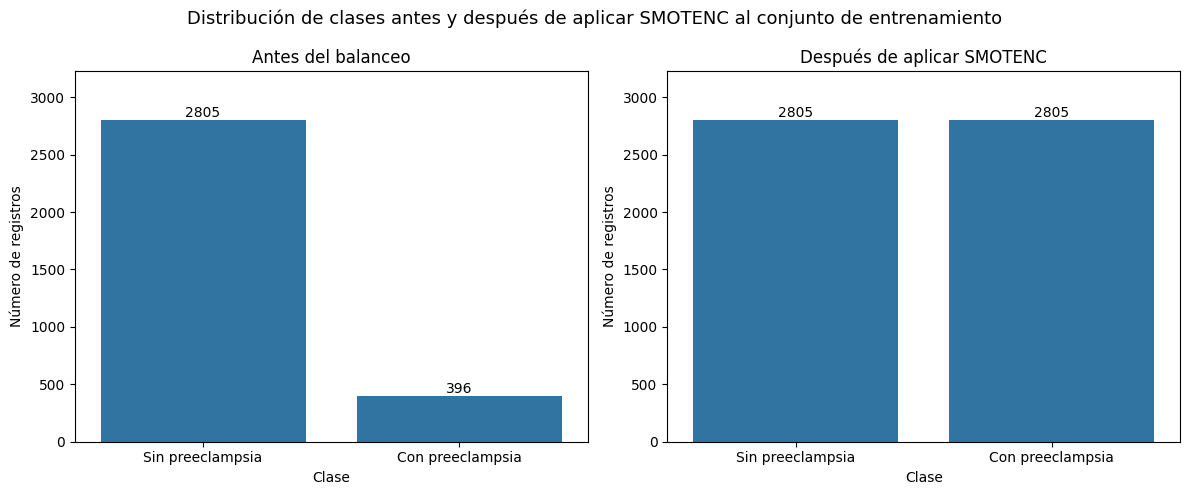


RESUMEN DEL BALANCEO


,Clase,Antes,Después
0,Sin preeclampsia,2805,2805
1,Con preeclampsia,396,2805



Visualización completada. El balanceo se aplicó únicamente sobre Train.


In [ ]:
# 3.2 Visualización del balanceo de clases con SMOTENC

from sklearn.base import clone
from imblearn.over_sampling import SMOTENC

# 1. PREPROCESAMIENTO EXCLUSIVO PARA VISUALIZACIÓN
# ------------------------------------------------------------

# Se utiliza una copia independiente para no modificar
# el preprocesador de los modelos posteriores.

preprocessor_vis = clone(preprocessor)

X_train_processed = preprocessor_vis.fit_transform(
    X_train
)

# 2. CONFIGURAR SMOTENC
# ------------------------------------------------------------

categorical_indices = [5, 6, 7]

smotenc_vis = SMOTENC(
    categorical_features=categorical_indices,
    random_state=RANDOM_STATE,
    k_neighbors=3
)

# 3. APLICAR SMOTENC SOLO A TRAIN
# ------------------------------------------------------------

X_train_smotenc, y_train_smotenc = (
    smotenc_vis.fit_resample(
        X_train_processed,
        y_train
    )
)

# 4. DISTRIBUCIÓN ANTES Y DESPUÉS
# ------------------------------------------------------------

antes = (
    y_train
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .sort_index()
)

despues = (
    pd.Series(y_train_smotenc)
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .sort_index()
)

print("========================================")
print("BALANCEO DE CLASES CON SMOTENC")
print("========================================")

print("\nDistribución antes de SMOTENC:")
print(antes)

print("\nDistribución después de SMOTENC:")
print(despues)

print("\nRegistros originales en Train:", len(y_train))
print("Registros después del balanceo:", len(y_train_smotenc))

print(
    "Registros sintéticos añadidos:",
    len(y_train_smotenc) - len(y_train)
)

# 5. VERIFICAR VARIABLES BINARIAS
# ------------------------------------------------------------

print("\n========================================")
print("VERIFICACIÓN DE VARIABLES BINARIAS")
print("========================================")

X_resampled_array = np.asarray(X_train_smotenc)

for idx, nombre in zip(
    categorical_indices,
    binary_features
):
    valores = np.unique(
        X_resampled_array[:, idx]
    )

    print(f"{nombre}: {valores}")

    assert np.all(
        np.isin(valores, [0, 1])
    ), (
        f"SMOTENC generó valores inválidos en {nombre}."
    )

print("\nVariables binarias verificadas correctamente.")

# 6. VISUALIZACIÓN ANTES Y DESPUÉS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

etiquetas = [
    "Sin preeclampsia",
    "Con preeclampsia"
]

sns.barplot(
    x=etiquetas,
    y=antes.values,
    ax=axes[0]
)

axes[0].set_title("Antes del balanceo")
axes[0].set_ylabel("Número de registros")
axes[0].set_xlabel("Clase")

sns.barplot(
    x=etiquetas,
    y=despues.values,
    ax=axes[1]
)

axes[1].set_title("Después de aplicar SMOTENC")
axes[1].set_ylabel("Número de registros")
axes[1].set_xlabel("Clase")

# Misma escala para facilitar la comparación
limite_superior = max(
    antes.max(),
    despues.max()
) * 1.15

for ax in axes:
    ax.set_ylim(0, limite_superior)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.0f"
        )

plt.suptitle(
    "Distribución de clases antes y después "
    "de aplicar SMOTENC al conjunto de entrenamiento",
    fontsize=13
)

plt.tight_layout()
plt.show()

# 7. RESUMEN FINAL
# ------------------------------------------------------------

print("\n========================================")
print("RESUMEN DEL BALANCEO")
print("========================================")

resumen_balanceo_vis = pd.DataFrame({
    "Clase": etiquetas,
    "Antes": antes.values,
    "Después": despues.values
})

display(resumen_balanceo_vis)

print(
    "\nVisualización completada. "
    "El balanceo se aplicó únicamente sobre Train."
)

In [ ]:
# 3.3 Pipeline de entrenamiento con SMOTENC
# ------------------------------------------------------------

from imblearn.over_sampling import SMOTENC

# 1. CONFIGURACIÓN DE VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

# Orden de salida del preprocesador:
# 0-4: edad, edad_gestacion, imc, pam, hemoglobina
# 5-7: hipertension, diabetes, ant_fam_hiper

categorical_indices = [5, 6, 7]

# ------------------------------------------------------------
# 2. CONSTRUIR PIPELINE DE ENTRENAMIENTO
# ------------------------------------------------------------

def build_pipe(model):
    return ImbPipeline([
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "smotenc",
            SMOTENC(
                categorical_features=categorical_indices,
                random_state=RANDOM_STATE,
                k_neighbors=3
            )
        ),
        (
            "model",
            clone(model)
        )
    ])

# ------------------------------------------------------------
# 3. VERIFICACIÓN DE CONFIGURACIÓN
# ------------------------------------------------------------

print("========================================")
print("PIPELINE DE ENTRENAMIENTO CON SMOTENC")
print("========================================")

print("Variables numéricas:", numeric_features)
print("Variables binarias:", binary_features)
print("Índices categóricos:", categorical_indices)

print("\nPipeline de entrenamiento configurado correctamente.")
print("Balanceador: SMOTENC")
print("Número de vecinos:", 3)
print("Semilla aleatoria:", RANDOM_STATE)

PIPELINE DE ENTRENAMIENTO CON SMOTENC
Variables numéricas: ['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina']
Variables binarias: ['hipertension', 'diabetes', 'ant_fam_hiper']
Índices categóricos: [5, 6, 7]

Pipeline de entrenamiento configurado correctamente.
Balanceador: SMOTENC
Número de vecinos: 3
Semilla aleatoria: 42


### 4. Modelos candidatos

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 1. DEFINIR LOS 12 CLASIFICADORES
# ------------------------------------------------------------

candidates = [

    ("LR", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )),

    ("LDA", LinearDiscriminantAnalysis()),

    ("KNN", KNeighborsClassifier(
        n_neighbors=5
    )),

    ("GNB", GaussianNB()),

    ("DT", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    )),

    ("RF", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    )),

    ("ET", ExtraTreesClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    )),

    ("MLP", MLPClassifier(
        hidden_layer_sizes=(64,),
        max_iter=600,
        random_state=RANDOM_STATE
    )),

    ("SVM", SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )),

    ("XGB", XGBClassifier(
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        n_jobs=1
    )),

    ("LGBM", LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=-1
    )),

    ("CAT", CatBoostClassifier(
        iterations=600,
        learning_rate=0.05,
        depth=6,
        random_state=RANDOM_STATE,
        l2_leaf_reg=3.0,
        verbose=False,
        allow_writing_files=False,
        thread_count=1
    ))
]

# 2. VERIFICAR MODELOS
# ------------------------------------------------------------

nombres_modelos = [nombre for nombre, _ in candidates]

assert len(candidates) == 12, (
    "Se esperaban exactamente 12 modelos."
)

assert len(set(nombres_modelos)) == 12, (
    "Hay nombres de modelos duplicados."
)

# Comprobar que todos admiten probabilidades
for nombre, modelo in candidates:
    assert hasattr(modelo, "predict_proba"), (
        f"{nombre} no implementa predict_proba."
    )

# 3. MOSTRAR RESUMEN
# ------------------------------------------------------------

print("========================================")
print("MODELOS CANDIDATOS DE MACHINE LEARNING")
print("========================================")

print("Total de modelos:", len(candidates))

for i, (nombre, modelo) in enumerate(candidates, start=1):
    print(f"{i:02d}. {nombre}: {modelo.__class__.__name__}")

print("\nBalanceo previsto: SMOTENC")
print("Validación cruzada: 5 folds")
print("Semilla aleatoria:", RANDOM_STATE)

print("\nModelos candidatos configurados correctamente.")

MODELOS CANDIDATOS DE MACHINE LEARNING
Total de modelos: 12
01. LR: LogisticRegression
02. LDA: LinearDiscriminantAnalysis
03. KNN: KNeighborsClassifier
04. GNB: GaussianNB
05. DT: DecisionTreeClassifier
06. RF: RandomForestClassifier
07. ET: ExtraTreesClassifier
08. MLP: MLPClassifier
09. SVM: SVC
10. XGB: XGBClassifier
11. LGBM: LGBMClassifier
12. CAT: CatBoostClassifier

Balanceo previsto: SMOTENC
Validación cruzada: 5 folds
Semilla aleatoria: 42

Modelos candidatos configurados correctamente.


### 5. Entrenamiento y comparación de modelos

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

# 1. FUNCIÓN PARA CONSTRUIR PIPELINES CON SMOTENC
# ------------------------------------------------------------

# El preprocesador entrega:
# Posiciones 0-4: variables numéricas
# Posiciones 5-7: variables binarias

categorical_indices = [5, 6, 7]

def build_pipe(model):

    return ImbPipeline([
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "smotenc",
            SMOTENC(
                categorical_features=categorical_indices,
                random_state=RANDOM_STATE,
                k_neighbors=3
            )
        ),
        (
            "model",
            clone(model)
        )
    ])

# 2. VERIFICAR CONFIGURACIÓN
# ------------------------------------------------------------

assert list(X_train.columns) == (
    numeric_features + binary_features
), "El orden de las variables no coincide."

assert len(candidates) == 12, (
    "Se esperaban 12 clasificadores."
)

assert cv.n_splits == 5, (
    "La validación cruzada debe tener cinco folds."
)

# 3. ENTRENAMIENTO Y EVALUACIÓN
# ------------------------------------------------------------

baseline_rows = []

metricas = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "F1_macro": "f1_macro",
    "ROC_AUC": "roc_auc",
    "AP": "pr_auc"
}

for name, model in candidates:

    print("\n========================================")
    print(f"ENTRENANDO MODELO: {name}")
    print("========================================")

    pipe = build_pipe(model)

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    fila = {"Modelo": name}

    for nombre_metrica, clave in metricas.items():

        valores = scores[f"test_{clave}"]

        fila[f"{nombre_metrica}_mean"] = (
            float(valores.mean())
        )

        fila[f"{nombre_metrica}_std"] = (
            float(valores.std())
        )

    baseline_rows.append(fila)

    print(
        f"Accuracy: {fila['Accuracy_mean']:.4f} "
        f"± {fila['Accuracy_std']:.4f}"
    )
    print(
        f"Precision: {fila['Precision_mean']:.4f} "
        f"± {fila['Precision_std']:.4f}"
    )
    print(
        f"Recall: {fila['Recall_mean']:.4f} "
        f"± {fila['Recall_std']:.4f}"
    )
    print(
        f"F1-score: {fila['F1_mean']:.4f} "
        f"± {fila['F1_std']:.4f}"
    )
    print(
        f"Macro-F1: {fila['F1_macro_mean']:.4f} "
        f"± {fila['F1_macro_std']:.4f}"
    )
    print(
        f"ROC-AUC: {fila['ROC_AUC_mean']:.4f} "
        f"± {fila['ROC_AUC_std']:.4f}"
    )
    print(
        f"Average Precision: {fila['AP_mean']:.4f} "
        f"± {fila['AP_std']:.4f}"
    )

# 4. TABLA COMPLETA DE RESULTADOS
# ------------------------------------------------------------

baseline_df = pd.DataFrame(baseline_rows)

# Priorizar sensibilidad para reducir falsos negativos.
# F1 y AP se utilizan para ordenar posibles empates.
baseline_df = (
    baseline_df
    .sort_values(
        by=[
            "Recall_mean",
            "F1_mean",
            "AP_mean"
        ],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("COMPARACIÓN DE LOS 12 MODELOS")
print("ORDENADOS POR RECALL")
print("========================================")

display(baseline_df.round(4))

# 5. RESUMEN DE MÉTRICAS PRINCIPALES
# ------------------------------------------------------------

columnas_resumen = [
    "Modelo",
    "Recall_mean",
    "Recall_std",
    "Precision_mean",
    "F1_mean",
    "F1_macro_mean",
    "ROC_AUC_mean",
    "AP_mean"
]

print("\n========================================")
print("RANKING DE SENSIBILIDAD")
print("========================================")

display(
    baseline_df[columnas_resumen].round(4)
)

# 6. IDENTIFICAR MEJORES MODELOS
# ------------------------------------------------------------

print("\n========================================")
print("MEJORES MODELOS SEGÚN CADA MÉTRICA")
print("========================================")

for metrica in [
    "Recall_mean",
    "F1_mean",
    "ROC_AUC_mean",
    "AP_mean"
]:

    mejor = baseline_df.loc[
        baseline_df[metrica].idxmax()
    ]

    print(
        f"{metrica}: {mejor['Modelo']} "
        f"({mejor[metrica]:.4f})"
    )

# 7. CANDIDATOS PRELIMINARES
# ------------------------------------------------------------

top_5_recall = (
    baseline_df
    .head(5)
    .copy()
)

print("\n========================================")
print("CINCO MODELOS CON MAYOR RECALL")
print("========================================")

display(
    top_5_recall[columnas_resumen].round(4)
)

print("\nEvaluación inicial completada.")
print("Balanceo utilizado: SMOTENC")
print("Validación cruzada: 5 folds")
print("Modelos evaluados:", len(baseline_df))


ENTRENANDO MODELO: LR
Accuracy: 0.9213 ± 0.0033
Precision: 0.6266 ± 0.0089
Recall: 0.9014 ± 0.0420
F1-score: 0.7388 ± 0.0148
Macro-F1: 0.8462 ± 0.0081
ROC-AUC: 0.9666 ± 0.0102
Average Precision: 0.8719 ± 0.0460

ENTRENANDO MODELO: LDA
Accuracy: 0.9219 ± 0.0038
Precision: 0.6311 ± 0.0068
Recall: 0.8863 ± 0.0461
F1-score: 0.7369 ± 0.0196
Macro-F1: 0.8455 ± 0.0108
ROC-AUC: 0.9630 ± 0.0097
Average Precision: 0.8484 ± 0.0475

ENTRENANDO MODELO: KNN
Accuracy: 0.9216 ± 0.0104
Precision: 0.6473 ± 0.0399
Recall: 0.8205 ± 0.0630
F1-score: 0.7215 ± 0.0305
Macro-F1: 0.8379 ± 0.0179
ROC-AUC: 0.9274 ± 0.0197
Average Precision: 0.7319 ± 0.0422

ENTRENANDO MODELO: GNB
Accuracy: 0.9335 ± 0.0115
Precision: 0.6850 ± 0.0421
Recall: 0.8609 ± 0.0579
F1-score: 0.7619 ± 0.0406
Macro-F1: 0.8616 ± 0.0235
ROC-AUC: 0.9573 ± 0.0129
Average Precision: 0.8275 ± 0.0553

ENTRENANDO MODELO: DT
Accuracy: 0.9381 ± 0.0084
Precision: 0.7222 ± 0.0228
Recall: 0.8129 ± 0.0805
F1-score: 0.7630 ± 0.0424
Macro-F1: 0.8637 ± 0.02

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,F1_macro_mean,F1_macro_std,ROC_AUC_mean,ROC_AUC_std,AP_mean,AP_std
0,LR,0.9213,0.0033,0.6266,0.0089,0.9014,0.0420,0.7388,0.0148,0.8462,0.0081,0.9666,0.0102,0.8719,0.0460
1,LDA,0.9219,0.0038,0.6311,0.0068,0.8863,0.0461,0.7369,0.0196,0.8455,0.0108,0.9630,0.0097,0.8484,0.0475
2,SVM,0.9466,0.0060,0.7460,0.0228,0.8634,0.0547,0.7994,0.0263,0.8843,0.0147,0.9672,0.0062,0.8875,0.0301
3,GNB,0.9335,0.0115,0.6850,0.0421,0.8609,0.0579,0.7619,0.0406,0.8616,0.0235,0.9573,0.0129,0.8275,0.0553
4,MLP,0.9400,0.0074,0.7205,0.0304,0.8459,0.0576,0.7768,0.0289,0.8711,0.0164,0.9614,0.0054,0.8799,0.0372
5,XGB,0.9606,0.0061,0.8408,0.0145,0.8408,0.0513,0.8401,0.0291,0.9088,0.0162,0.9709,0.0087,0.9114,0.0252
6,RF,0.9606,0.0076,0.8458,0.0158,0.8331,0.0620,0.8385,0.0367,0.9080,0.0204,0.9700,0.0104,0.9062,0.0300
7,CAT,0.9619,0.0061,0.8596,0.0252,0.8281,0.0544,0.8424,0.0300,0.9103,0.0167,0.9737,0.0057,0.9171,0.0218
8,KNN,0.9216,0.0104,0.6473,0.0399,0.8205,0.0630,0.7215,0.0305,0.8379,0.0179,0.9274,0.0197,0.7319,0.0422
9,LGBM,0.9597,0.0094,0.8498,0.0229,0.8180,0.0722,0.8323,0.0451,0.9047,0.0251,0.9711,0.0072,0.9112,0.0295



RANKING DE SENSIBILIDAD


,Modelo,Recall_mean,Recall_std,Precision_mean,F1_mean,F1_macro_mean,ROC_AUC_mean,AP_mean
0,LR,0.9014,0.0420,0.6266,0.7388,0.8462,0.9666,0.8719
1,LDA,0.8863,0.0461,0.6311,0.7369,0.8455,0.9630,0.8484
2,SVM,0.8634,0.0547,0.7460,0.7994,0.8843,0.9672,0.8875
3,GNB,0.8609,0.0579,0.6850,0.7619,0.8616,0.9573,0.8275
4,MLP,0.8459,0.0576,0.7205,0.7768,0.8711,0.9614,0.8799
5,XGB,0.8408,0.0513,0.8408,0.8401,0.9088,0.9709,0.9114
6,RF,0.8331,0.0620,0.8458,0.8385,0.9080,0.9700,0.9062
7,CAT,0.8281,0.0544,0.8596,0.8424,0.9103,0.9737,0.9171
8,KNN,0.8205,0.0630,0.6473,0.7215,0.8379,0.9274,0.7319
9,LGBM,0.8180,0.0722,0.8498,0.8323,0.9047,0.9711,0.9112



MEJORES MODELOS SEGÚN CADA MÉTRICA
Recall_mean: LR (0.9014)
F1_mean: CAT (0.8424)
ROC_AUC_mean: CAT (0.9737)
AP_mean: CAT (0.9171)

CINCO MODELOS CON MAYOR RECALL


,Modelo,Recall_mean,Recall_std,Precision_mean,F1_mean,F1_macro_mean,ROC_AUC_mean,AP_mean
0,LR,0.9014,0.0420,0.6266,0.7388,0.8462,0.9666,0.8719
1,LDA,0.8863,0.0461,0.6311,0.7369,0.8455,0.9630,0.8484
2,SVM,0.8634,0.0547,0.7460,0.7994,0.8843,0.9672,0.8875
3,GNB,0.8609,0.0579,0.6850,0.7619,0.8616,0.9573,0.8275
4,MLP,0.8459,0.0576,0.7205,0.7768,0.8711,0.9614,0.8799



Evaluación inicial completada.
Balanceo utilizado: SMOTENC
Validación cruzada: 5 folds
Modelos evaluados: 12


**Resultados de los modelos base**

La evaluación comparativa de los 12 clasificadores mediante validación cruzada estratificada de cinco particiones, utilizando **SMOTENC como estrategia de balanceo**, evidenció diferencias en el desempeño predictivo de los modelos.

**Logistic Regression (LR)** obtuvo la mayor sensibilidad (Recall = 0.9014), seguido de Linear Discriminant Analysis (0.8863), Support Vector Machine (0.8634) y Gaussian Naive Bayes (0.8609). Sin embargo, LR y LDA presentaron valores de Precision de 0.6266 y 0.6311, respectivamente, lo que evidencia una mayor proporción de predicciones positivas incorrectas.

Por otro lado, los modelos basados en árboles y técnicas de boosting destacaron por sus resultados en métricas de desempeño global. **CatBoost** alcanzó el mayor F1-score (0.8424), ROC-AUC (0.9737) y Average Precision (AP = 0.9171), seguido de XGBoost, con un F1-score de 0.8401, ROC-AUC de 0.9709 y AP de 0.9114.

Random Forest presentó un F1-score de 0.8385 y AP de 0.9062, mientras que LightGBM obtuvo un F1-score de 0.8323 y AP de 0.9112. Extra Trees alcanzó un F1-score de 0.8351 y AP de 0.9044.

En conjunto, los resultados muestran que **los modelos lineales destacaron por su mayor sensibilidad**, mientras que los modelos basados en árboles y boosting presentaron un mejor equilibrio entre Precision y Recall, así como valores competitivos de discriminación.

Estos resultados corresponden a **modelos base evaluados con sus configuraciones iniciales**, antes de la optimización de hiperparámetros. Las diferencias observadas son descriptivas y no constituyen evidencia suficiente de superioridad estadística entre clasificadores. Su desempeño será contrastado en las siguientes etapas experimentales.

### 6. Tuning de hiperparámetros de modelos

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

# 1. DICCIONARIO DE MODELOS
# ------------------------------------------------------------

modelos_dict = dict(candidates)

assert len(modelos_dict) == 12, (
    "Se esperaban 12 modelos candidatos."
)

# 2. ESPACIOS DE BÚSQUEDA
# ------------------------------------------------------------

param_spaces = {

    "LR": {
        "model__C": loguniform(1e-2, 1e2),
        "model__solver": ["lbfgs", "liblinear"]
    },
    "LDA": [
        {
            "model__solver": ["svd"],
            "model__shrinkage": [None]
        },
        {
            "model__solver": ["lsqr", "eigen"],
            "model__shrinkage": [
                None, "auto", 0.1, 0.5, 0.9
            ]
        }
    ],
    "KNN": {
        "model__n_neighbors": randint(3, 21),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },
    "GNB": {
        "model__var_smoothing": loguniform(
            1e-12, 1e-6
        )
    },
    "DT": {
        "model__max_depth": randint(3, 20),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__criterion": ["gini", "entropy"]
    },
    "RF": {
        "model__n_estimators": randint(200, 600),
        "model__max_depth": randint(4, 20),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": ["sqrt", "log2", None]
    },
    "ET": {
        "model__n_estimators": randint(200, 600),
        "model__max_depth": randint(4, 20),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": ["sqrt", "log2", None]
    },
    "MLP": {
        "model__hidden_layer_sizes": [
            (32,), (64,), (128,), (64, 32)
        ],
        "model__activation": ["relu", "tanh"],
        "model__alpha": loguniform(1e-5, 1e-2),
        "model__learning_rate_init": loguniform(
            1e-4, 1e-2
        )
    },
    "SVM": {
        "model__C": loguniform(1e-2, 1e2),
        "model__gamma": ["scale", "auto"],
        "model__kernel": ["rbf"]
    },
    "XGB": {
        "model__n_estimators": randint(200, 700),
        "model__learning_rate": uniform(0.01, 0.09),
        "model__max_depth": randint(3, 9),
        "model__subsample": uniform(0.7, 0.3),
        "model__colsample_bytree": uniform(0.7, 0.3),
        "model__min_child_weight": randint(1, 8)
    },
    "LGBM": {
        "model__n_estimators": randint(200, 800),
        "model__learning_rate": uniform(0.01, 0.09),
        "model__num_leaves": randint(15, 80),
        "model__max_depth": randint(3, 12),
        "model__subsample": uniform(0.7, 0.3),
        "model__colsample_bytree": uniform(0.7, 0.3)
    },
    "CAT": {
        "model__iterations": randint(200, 800),
        "model__learning_rate": uniform(0.01, 0.09),
        "model__depth": randint(4, 10),
        "model__l2_leaf_reg": uniform(1, 9)
    }
}

# 3. CONFIGURACIÓN EXPERIMENTAL
# ------------------------------------------------------------

N_ITER = 20
METRICA_REFIT = "pr_auc"

assert METRICA_REFIT in scoring

assert all(
    nombre in param_spaces
    for nombre in modelos_dict
)

# 4. ALMACENAMIENTO DE RESULTADOS
# ------------------------------------------------------------

tuning_rows = []
best_estimators = {}
searches = {}

metricas_cv = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "F1_macro": "f1_macro",
    "ROC_AUC": "roc_auc",
    "AP": "pr_auc"
}

# 5. OPTIMIZACIÓN DE LOS 12 MODELOS
# ------------------------------------------------------------

for name, model in candidates:

    print("\n========================================")
    print(f"OPTIMIZACIÓN DEL MODELO: {name}")
    print("========================================")

    # Pipeline:
    # Preprocesamiento -> SMOTENC -> Clasificador
    pipe = build_pipe(model)

    assert "smotenc" in pipe.named_steps, (
        f"{name} no contiene SMOTENC."
    )

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_spaces[name],
        n_iter=N_ITER,
        scoring=scoring,
        refit=METRICA_REFIT,
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        error_score="raise",
        return_train_score=False
    )

    # Ajuste exclusivamente sobre Train
    search.fit(
        X_train,
        y_train
    )

    # Guardar búsqueda y mejor pipeline ajustado
    searches[name] = search

    best_estimators[name] = (
        search.best_estimator_
    )

    # RECUPERAR TODAS LAS MÉTRICAS DE LA MEJOR CONFIGURACIÓN
    # --------------------------------------------------------

    mejor_idx = search.best_index_

    fila = {
        "Modelo": name,
        "Best_AP": float(search.best_score_),
        "Best_Params": search.best_params_
    }

    for etiqueta, clave in metricas_cv.items():

        fila[f"{etiqueta}_mean"] = float(
            search.cv_results_[
                f"mean_test_{clave}"
            ][mejor_idx]
        )

        fila[f"{etiqueta}_std"] = float(
            search.cv_results_[
                f"std_test_{clave}"
            ][mejor_idx]
        )

    tuning_rows.append(fila)

    print("\nRESULTADOS DE LA MEJOR CONFIGURACIÓN")

    print(
        f"Average Precision: "
        f"{fila['AP_mean']:.4f}"
    )
    print(
        f"Recall: "
        f"{fila['Recall_mean']:.4f}"
    )
    print(
        f"Precision: "
        f"{fila['Precision_mean']:.4f}"
    )
    print(
        f"F1-score: "
        f"{fila['F1_mean']:.4f}"
    )
    print(
        f"ROC-AUC: "
        f"{fila['ROC_AUC_mean']:.4f}"
    )

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

# 6. TABLA COMPLETA DE OPTIMIZACIÓN
# ------------------------------------------------------------

tuning_df = pd.DataFrame(tuning_rows)

# Ordenar por sensibilidad para facilitar la revisión.
# La optimización interna se realizó mediante AP.

tuning_df = (
    tuning_df
    .sort_values(
        by=[
            "Recall_mean",
            "AP_mean",
            "F1_mean"
        ],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("RESULTADOS DE LOS 12 MODELOS OPTIMIZADOS")
print("ORDENADOS POR RECALL")
print("========================================")

columnas_resultados = [
    "Modelo",
    "Accuracy_mean",
    "Precision_mean",
    "Recall_mean",
    "Recall_std",
    "F1_mean",
    "F1_macro_mean",
    "ROC_AUC_mean",
    "AP_mean"
]

display(
    tuning_df[columnas_resultados].round(4)
)

# 7. RANKING SEGÚN AVERAGE PRECISION
# ------------------------------------------------------------

print("\n========================================")
print("RANKING SEGÚN AVERAGE PRECISION")
print("========================================")

display(
    tuning_df[
        columnas_resultados
    ]
    .sort_values(
        by="AP_mean",
        ascending=False
    )
    .round(4)
)

# 8. IDENTIFICAR MEJORES MODELOS
# ------------------------------------------------------------

print("\n========================================")
print("MEJORES MODELOS SEGÚN CADA MÉTRICA")
print("========================================")

for metrica in [
    "Recall_mean",
    "F1_mean",
    "ROC_AUC_mean",
    "AP_mean"
]:

    mejor = tuning_df.loc[
        tuning_df[metrica].idxmax()
    ]

    print(
        f"{metrica}: "
        f"{mejor['Modelo']} "
        f"({mejor[metrica]:.4f})"
    )

# 9. VERIFICAR MODELOS OPTIMIZADOS
# ------------------------------------------------------------

assert len(best_estimators) == 12, (
    "No se optimizaron los 12 modelos."
)

for nombre, modelo in best_estimators.items():

    assert "smotenc" in modelo.named_steps, (
        f"{nombre} no utiliza SMOTENC."
    )

print("\n========================================")
print("OPTIMIZACIÓN FINALIZADA")
print("========================================")

print("Modelos optimizados:", len(best_estimators))
print("Balanceo utilizado: SMOTENC")
print("Métrica de optimización: Average Precision")
print("Validación cruzada: 5 folds")
print("Semilla aleatoria:", RANDOM_STATE)


OPTIMIZACIÓN DEL MODELO: LR
Fitting 5 folds for each of 20 candidates, totalling 100 fits

RESULTADOS DE LA MEJOR CONFIGURACIÓN
Average Precision: 0.8722
Recall: 0.8989
Precision: 0.6269
F1-score: 0.7382
ROC-AUC: 0.9667

Mejores hiperparámetros:
{'model__C': np.float64(78.52755494724258), 'model__solver': 'lbfgs'}

OPTIMIZACIÓN DEL MODELO: LDA
Fitting 5 folds for each of 11 candidates, totalling 55 fits

RESULTADOS DE LA MEJOR CONFIGURACIÓN
Average Precision: 0.8496
Recall: 0.8863
Precision: 0.6333
F1-score: 0.7384
ROC-AUC: 0.9631

Mejores hiperparámetros:
{'model__solver': 'lsqr', 'model__shrinkage': 'auto'}

OPTIMIZACIÓN DEL MODELO: KNN
Fitting 5 folds for each of 20 candidates, totalling 100 fits

RESULTADOS DE LA MEJOR CONFIGURACIÓN
Average Precision: 0.8687
Recall: 0.8382
Precision: 0.6928
F1-score: 0.7564
ROC-AUC: 0.9562

Mejores hiperparámetros:
{'model__n_neighbors': 18, 'model__p': 1, 'model__weights': 'distance'}

OPTIMIZACIÓN DEL MODELO: GNB
Fitting 5 folds for each of 20 c

,Modelo,Accuracy_mean,Precision_mean,Recall_mean,Recall_std,F1_mean,F1_macro_mean,ROC_AUC_mean,AP_mean
0,LR,0.9213,0.6269,0.8989,0.0461,0.7382,0.8459,0.9667,0.8722
1,LDA,0.9225,0.6333,0.8863,0.0461,0.7384,0.8465,0.9631,0.8496
2,MLP,0.9347,0.6825,0.8862,0.0475,0.7703,0.8661,0.9722,0.9027
3,SVM,0.9447,0.7295,0.8812,0.0430,0.7975,0.8827,0.9683,0.8918
4,GNB,0.9335,0.6850,0.8609,0.0579,0.7619,0.8616,0.9573,0.8275
5,RF,0.9588,0.8231,0.8508,0.0473,0.8358,0.9061,0.9709,0.9104
6,LGBM,0.9622,0.8526,0.8407,0.0549,0.8453,0.9119,0.9741,0.9171
7,ET,0.9616,0.8473,0.8407,0.0764,0.8423,0.9102,0.9725,0.9129
8,CAT,0.9606,0.8421,0.8407,0.0600,0.8399,0.9087,0.9742,0.9201
9,KNN,0.9335,0.6928,0.8382,0.0698,0.7564,0.8589,0.9562,0.8687



RANKING SEGÚN AVERAGE PRECISION


,Modelo,Accuracy_mean,Precision_mean,Recall_mean,Recall_std,F1_mean,F1_macro_mean,ROC_AUC_mean,AP_mean
8,CAT,0.9606,0.8421,0.8407,0.0600,0.8399,0.9087,0.9742,0.9201
6,LGBM,0.9622,0.8526,0.8407,0.0549,0.8453,0.9119,0.9741,0.9171
7,ET,0.9616,0.8473,0.8407,0.0764,0.8423,0.9102,0.9725,0.9129
5,RF,0.9588,0.8231,0.8508,0.0473,0.8358,0.9061,0.9709,0.9104
10,XGB,0.9609,0.8476,0.8357,0.0528,0.8403,0.9090,0.9703,0.9090
2,MLP,0.9347,0.6825,0.8862,0.0475,0.7703,0.8661,0.9722,0.9027
3,SVM,0.9447,0.7295,0.8812,0.0430,0.7975,0.8827,0.9683,0.8918
0,LR,0.9213,0.6269,0.8989,0.0461,0.7382,0.8459,0.9667,0.8722
9,KNN,0.9335,0.6928,0.8382,0.0698,0.7564,0.8589,0.9562,0.8687
1,LDA,0.9225,0.6333,0.8863,0.0461,0.7384,0.8465,0.9631,0.8496



MEJORES MODELOS SEGÚN CADA MÉTRICA
Recall_mean: LR (0.8989)
F1_mean: LGBM (0.8453)
ROC_AUC_mean: CAT (0.9742)
AP_mean: CAT (0.9201)

OPTIMIZACIÓN FINALIZADA
Modelos optimizados: 12
Balanceo utilizado: SMOTENC
Métrica de optimización: Average Precision
Validación cruzada: 5 folds
Semilla aleatoria: 42


### 7. Comparación entre modelos base y modelos optimizados

Recuperando resultados optimizados: LR
Recuperando resultados optimizados: LDA
Recuperando resultados optimizados: KNN
Recuperando resultados optimizados: GNB
Recuperando resultados optimizados: DT
Recuperando resultados optimizados: RF
Recuperando resultados optimizados: ET
Recuperando resultados optimizados: MLP
Recuperando resultados optimizados: SVM
Recuperando resultados optimizados: XGB
Recuperando resultados optimizados: LGBM
Recuperando resultados optimizados: CAT

7.1 RESULTADOS DE MODELOS OPTIMIZADOS


,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,F1_macro_mean,F1_macro_std,ROC_AUC_mean,ROC_AUC_std,AP_mean,AP_std
0,LR,0.9213,0.0041,0.6269,0.0102,0.8989,0.0461,0.7382,0.0181,0.8459,0.0100,0.9667,0.0102,0.8722,0.0461
1,LDA,0.9225,0.0047,0.6333,0.0098,0.8863,0.0461,0.7384,0.0219,0.8465,0.0122,0.9631,0.0096,0.8496,0.0464
2,MLP,0.9347,0.0065,0.6825,0.0231,0.8862,0.0475,0.7703,0.0236,0.8661,0.0135,0.9722,0.0077,0.9027,0.0344
3,SVM,0.9447,0.0048,0.7295,0.0204,0.8812,0.0430,0.7975,0.0190,0.8827,0.0107,0.9683,0.0091,0.8918,0.0304
4,GNB,0.9335,0.0115,0.6850,0.0421,0.8609,0.0579,0.7619,0.0406,0.8616,0.0235,0.9573,0.0129,0.8275,0.0553
5,RF,0.9588,0.0061,0.8231,0.0292,0.8508,0.0473,0.8358,0.0259,0.9061,0.0146,0.9709,0.0087,0.9104,0.0244
6,LGBM,0.9622,0.0041,0.8526,0.0129,0.8407,0.0549,0.8453,0.0230,0.9119,0.0126,0.9741,0.0047,0.9171,0.0214
7,ET,0.9616,0.0085,0.8473,0.0156,0.8407,0.0764,0.8423,0.0423,0.9102,0.0235,0.9725,0.0086,0.9129,0.0336
8,CAT,0.9606,0.0057,0.8421,0.0233,0.8407,0.0600,0.8399,0.0287,0.9087,0.0159,0.9742,0.0053,0.9201,0.0238
9,KNN,0.9335,0.0065,0.6928,0.0283,0.8382,0.0698,0.7564,0.0259,0.8589,0.0144,0.9562,0.0151,0.8687,0.0446



7.2 COMPARACIÓN COMPLETA BASE VS TUNING


,Modelo,Accuracy_mean_base,Precision_mean_base,Recall_mean_base,F1_mean_base,F1_macro_mean_base,ROC_AUC_mean_base,AP_mean_base,Accuracy_mean_tuned,Precision_mean_tuned,...,F1_macro_mean_tuned,ROC_AUC_mean_tuned,AP_mean_tuned,Delta_Accuracy_mean,Delta_Precision_mean,Delta_Recall_mean,Delta_F1_mean,Delta_F1_macro_mean,Delta_ROC_AUC_mean,Delta_AP_mean
0,LR,0.9213,0.6266,0.9014,0.7388,0.8462,0.9666,0.8719,0.9213,0.6269,...,0.8459,0.9667,0.8722,0.0000,0.0004,-0.0025,-0.0006,-0.0003,0.0001,0.0003
1,LDA,0.9219,0.6311,0.8863,0.7369,0.8455,0.9630,0.8484,0.9225,0.6333,...,0.8465,0.9631,0.8496,0.0006,0.0022,0.0000,0.0016,0.0010,0.0001,0.0013
2,MLP,0.9400,0.7205,0.8459,0.7768,0.8711,0.9614,0.8799,0.9347,0.6825,...,0.8661,0.9722,0.9027,-0.0053,-0.0381,0.0404,-0.0064,-0.0049,0.0108,0.0229
3,SVM,0.9466,0.7460,0.8634,0.7994,0.8843,0.9672,0.8875,0.9447,0.7295,...,0.8827,0.9683,0.8918,-0.0019,-0.0165,0.0177,-0.0019,-0.0016,0.0011,0.0043
4,GNB,0.9335,0.6850,0.8609,0.7619,0.8616,0.9573,0.8275,0.9335,0.6850,...,0.8616,0.9573,0.8275,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,RF,0.9606,0.8458,0.8331,0.8385,0.9080,0.9700,0.9062,0.9588,0.8231,...,0.9061,0.9709,0.9104,-0.0019,-0.0227,0.0177,-0.0027,-0.0019,0.0009,0.0042
6,LGBM,0.9597,0.8498,0.8180,0.8323,0.9047,0.9711,0.9112,0.9622,0.8526,...,0.9119,0.9741,0.9171,0.0025,0.0028,0.0228,0.0130,0.0072,0.0030,0.0058
7,ET,0.9609,0.8609,0.8154,0.8351,0.9064,0.9668,0.9044,0.9616,0.8473,...,0.9102,0.9725,0.9129,0.0006,-0.0136,0.0253,0.0072,0.0037,0.0056,0.0085
8,CAT,0.9619,0.8596,0.8281,0.8424,0.9103,0.9737,0.9171,0.9606,0.8421,...,0.9087,0.9742,0.9201,-0.0012,-0.0174,0.0126,-0.0024,-0.0016,0.0005,0.0030
9,KNN,0.9216,0.6473,0.8205,0.7215,0.8379,0.9274,0.7319,0.9335,0.6928,...,0.8589,0.9562,0.8687,0.0119,0.0455,0.0176,0.0349,0.0210,0.0288,0.1368



7.3 RESUMEN DE LOS CAMBIOS


,Modelo,Recall_mean_base,Recall_mean_tuned,Delta_Recall_mean,Precision_mean_base,Precision_mean_tuned,Delta_Precision_mean,F1_mean_base,F1_mean_tuned,Delta_F1_mean,AP_mean_base,AP_mean_tuned,Delta_AP_mean,ROC_AUC_mean_base,ROC_AUC_mean_tuned,Delta_ROC_AUC_mean
0,LR,0.9014,0.8989,-0.0025,0.6266,0.6269,0.0004,0.7388,0.7382,-0.0006,0.8719,0.8722,0.0003,0.9666,0.9667,0.0001
1,LDA,0.8863,0.8863,0.0000,0.6311,0.6333,0.0022,0.7369,0.7384,0.0016,0.8484,0.8496,0.0013,0.9630,0.9631,0.0001
2,MLP,0.8459,0.8862,0.0404,0.7205,0.6825,-0.0381,0.7768,0.7703,-0.0064,0.8799,0.9027,0.0229,0.9614,0.9722,0.0108
3,SVM,0.8634,0.8812,0.0177,0.7460,0.7295,-0.0165,0.7994,0.7975,-0.0019,0.8875,0.8918,0.0043,0.9672,0.9683,0.0011
4,GNB,0.8609,0.8609,0.0000,0.6850,0.6850,0.0000,0.7619,0.7619,0.0000,0.8275,0.8275,0.0000,0.9573,0.9573,0.0000
5,RF,0.8331,0.8508,0.0177,0.8458,0.8231,-0.0227,0.8385,0.8358,-0.0027,0.9062,0.9104,0.0042,0.9700,0.9709,0.0009
6,LGBM,0.8180,0.8407,0.0228,0.8498,0.8526,0.0028,0.8323,0.8453,0.0130,0.9112,0.9171,0.0058,0.9711,0.9741,0.0030
7,ET,0.8154,0.8407,0.0253,0.8609,0.8473,-0.0136,0.8351,0.8423,0.0072,0.9044,0.9129,0.0085,0.9668,0.9725,0.0056
8,CAT,0.8281,0.8407,0.0126,0.8596,0.8421,-0.0174,0.8424,0.8399,-0.0024,0.9171,0.9201,0.0030,0.9737,0.9742,0.0005
9,KNN,0.8205,0.8382,0.0176,0.6473,0.6928,0.0455,0.7215,0.7564,0.0349,0.7319,0.8687,0.1368,0.9274,0.9562,0.0288


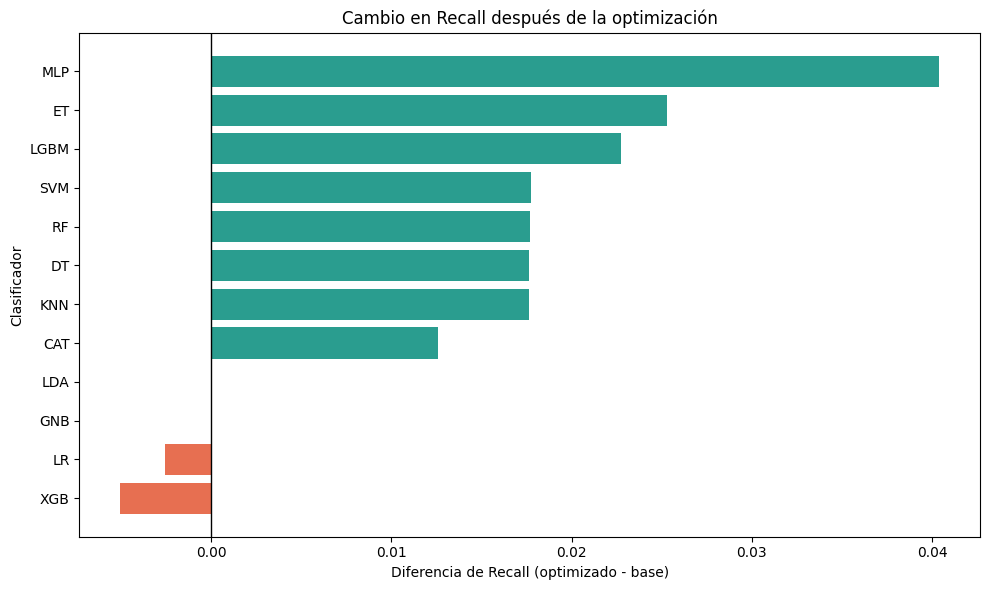

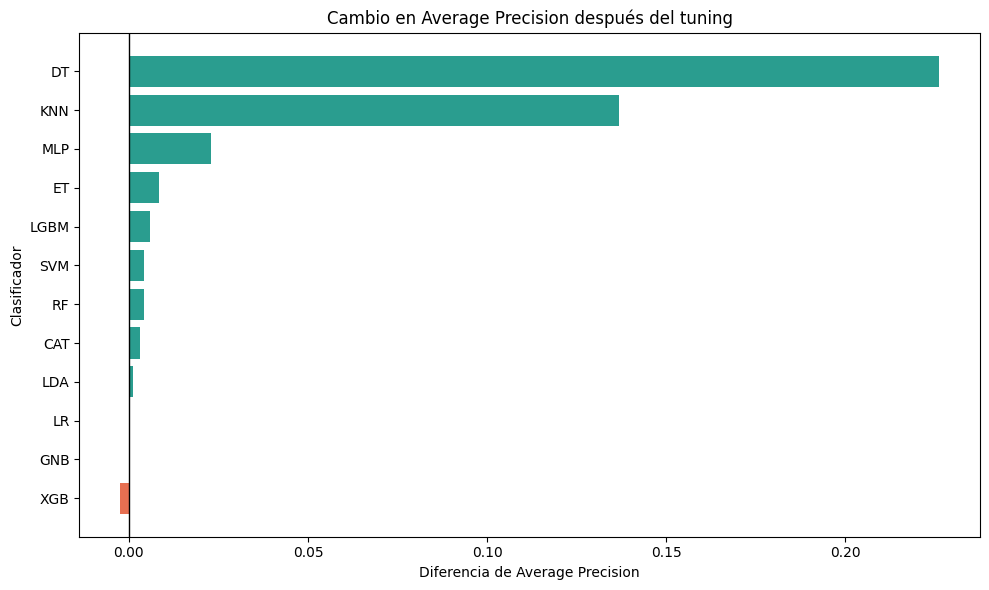


7.4 RESUMEN GENERAL
Modelos con aumento de Recall: 8 de 12
Modelos con aumento de F1-score: 5 de 12
Modelos con aumento de Average Precision: 10 de 12

MEJORES MODELOS DESPUÉS DEL TUNING
Mayor Recall: LR (0.8989)
Mayor F1-score: LGBM (0.8453)
Mayor Average Precision: CAT (0.9201)

Comparación descriptiva completada.
Balanceo: SMOTENC
Prioridad clínica: reducir falsos negativos
Nota: los resultados del tuning no son estimaciones independientes de rendimiento.


In [ ]:
# 1. VERIFICAR RESULTADOS DE LAS ETAPAS ANTERIORES
# ------------------------------------------------------------

assert len(baseline_df) == 12, (
    "No se encontraron los 12 modelos base."
)

assert len(searches) == 12, (
    "Primero debe completarse el tuning de 12 modelos."
)

assert len(best_estimators) == 12, (
    "No se encontraron los 12 modelos optimizados."
)

# 2. RECUPERAR MÉTRICAS DE LOS MODELOS OPTIMIZADOS
# ------------------------------------------------------------

# Las métricas proceden de los folds ya evaluados por
# RandomizedSearchCV, sin repetir cross_validate().

metricas_cv = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "F1_macro": "f1_macro",
    "ROC_AUC": "roc_auc",
    "AP": "pr_auc"
}

tuned_cv_rows = []

for name, search in searches.items():

    print(f"Recuperando resultados optimizados: {name}")

    mejor_idx = search.best_index_

    fila = {
        "Modelo": name
    }

    for etiqueta, clave in metricas_cv.items():

        fila[f"{etiqueta}_mean"] = float(
            search.cv_results_[
                f"mean_test_{clave}"
            ][mejor_idx]
        )

        fila[f"{etiqueta}_std"] = float(
            search.cv_results_[
                f"std_test_{clave}"
            ][mejor_idx]
        )

    tuned_cv_rows.append(fila)

# 3. TABLA DE MODELOS OPTIMIZADOS
# ------------------------------------------------------------

tuned_cv_df = pd.DataFrame(tuned_cv_rows)

tuned_cv_df = (
    tuned_cv_df
    .sort_values(
        by=["Recall_mean", "AP_mean"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("7.1 RESULTADOS DE MODELOS OPTIMIZADOS")
print("========================================")

display(tuned_cv_df.round(4))

# 4. COMPARACIÓN BASE VS OPTIMIZADO
# ------------------------------------------------------------

metricas_comparar = [
    "Accuracy_mean",
    "Precision_mean",
    "Recall_mean",
    "F1_mean",
    "F1_macro_mean",
    "ROC_AUC_mean",
    "AP_mean"
]

base_comp = baseline_df[
    ["Modelo"] + metricas_comparar
].copy()

tuned_comp = tuned_cv_df[
    ["Modelo"] + metricas_comparar
].copy()

comparacion_df = base_comp.merge(
    tuned_comp,
    on="Modelo",
    suffixes=("_base", "_tuned"),
    validate="one_to_one"
)

assert len(comparacion_df) == 12, (
    "La comparación no contiene los 12 modelos."
)

# 5. CALCULAR CAMBIOS DESPUÉS DEL TUNING
# ------------------------------------------------------------

for metrica in metricas_comparar:

    comparacion_df[f"Delta_{metrica}"] = (
        comparacion_df[f"{metrica}_tuned"]
        -
        comparacion_df[f"{metrica}_base"]
    )

# Prioridad: sensibilidad
comparacion_df = (
    comparacion_df
    .sort_values(
        by=[
            "Recall_mean_tuned",
            "AP_mean_tuned"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("7.2 COMPARACIÓN COMPLETA BASE VS TUNING")
print("========================================")

display(comparacion_df.round(4))

# 6. RESUMEN PRINCIPAL
# ------------------------------------------------------------

resumen_comparacion = comparacion_df[[
    "Modelo",

    "Recall_mean_base",
    "Recall_mean_tuned",
    "Delta_Recall_mean",

    "Precision_mean_base",
    "Precision_mean_tuned",
    "Delta_Precision_mean",

    "F1_mean_base",
    "F1_mean_tuned",
    "Delta_F1_mean",

    "AP_mean_base",
    "AP_mean_tuned",
    "Delta_AP_mean",

    "ROC_AUC_mean_base",
    "ROC_AUC_mean_tuned",
    "Delta_ROC_AUC_mean"
]].copy()

print("\n========================================")
print("7.3 RESUMEN DE LOS CAMBIOS")
print("========================================")

display(resumen_comparacion.round(4))

# 7. GRÁFICO: CAMBIO EN RECALL
# ------------------------------------------------------------

datos_recall = (
    comparacion_df
    .sort_values("Delta_Recall_mean")
)

fig, ax = plt.subplots(figsize=(10, 6))

colores_recall = [
    "#2A9D8F" if valor >= 0 else "#E76F51"
    for valor in datos_recall["Delta_Recall_mean"]
]

ax.barh(
    datos_recall["Modelo"],
    datos_recall["Delta_Recall_mean"],
    color=colores_recall
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Cambio en Recall después de la optimización"
)

ax.set_xlabel("Diferencia de Recall (optimizado - base)")
ax.set_ylabel("Clasificador")

plt.tight_layout()
plt.show()

# 8. GRÁFICO: CAMBIO EN AVERAGE PRECISION
# ------------------------------------------------------------

datos_ap = (
    comparacion_df
    .sort_values("Delta_AP_mean")
)

fig, ax = plt.subplots(figsize=(10, 6))

colores_ap = [
    "#2A9D8F" if valor >= 0 else "#E76F51"
    for valor in datos_ap["Delta_AP_mean"]
]

ax.barh(
    datos_ap["Modelo"],
    datos_ap["Delta_AP_mean"],
    color=colores_ap
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Cambio en Average Precision después del tuning"
)

ax.set_xlabel("Diferencia de Average Precision")
ax.set_ylabel("Clasificador")

plt.tight_layout()
plt.show()

# 9. RESUMEN DE MEJORAS
# ------------------------------------------------------------

n_mejoran_recall = int(
    (comparacion_df["Delta_Recall_mean"] > 0).sum()
)

n_mejoran_ap = int(
    (comparacion_df["Delta_AP_mean"] > 0).sum()
)

n_mejoran_f1 = int(
    (comparacion_df["Delta_F1_mean"] > 0).sum()
)

print("\n========================================")
print("7.4 RESUMEN GENERAL")
print("========================================")

print(
    "Modelos con aumento de Recall:",
    n_mejoran_recall,
    "de 12"
)

print(
    "Modelos con aumento de F1-score:",
    n_mejoran_f1,
    "de 12"
)

print(
    "Modelos con aumento de Average Precision:",
    n_mejoran_ap,
    "de 12"
)

# 10. MEJORES MODELOS OPTIMIZADOS
# ------------------------------------------------------------

mejor_recall = tuned_cv_df.loc[
    tuned_cv_df["Recall_mean"].idxmax()
]

mejor_ap = tuned_cv_df.loc[
    tuned_cv_df["AP_mean"].idxmax()
]

mejor_f1 = tuned_cv_df.loc[
    tuned_cv_df["F1_mean"].idxmax()
]

print("\n========================================")
print("MEJORES MODELOS DESPUÉS DEL TUNING")
print("========================================")

print(
    f"Mayor Recall: {mejor_recall['Modelo']} "
    f"({mejor_recall['Recall_mean']:.4f})"
)

print(
    f"Mayor F1-score: {mejor_f1['Modelo']} "
    f"({mejor_f1['F1_mean']:.4f})"
)

print(
    f"Mayor Average Precision: {mejor_ap['Modelo']} "
    f"({mejor_ap['AP_mean']:.4f})"
)

print("\nComparación descriptiva completada.")
print("Balanceo: SMOTENC")
print("Prioridad clínica: reducir falsos negativos")
print(
    "Nota: los resultados del tuning no son "
    "estimaciones independientes de rendimiento."
)

### 8. Selección de modelos para Stacking

In [ ]:
# Modelos seleccionados después del tuning

top_modelos = [
    "LR",
    "MLP",
    "SVM",
    "LGBM",
    "CAT"
]

# Verificar disponibilidad de los modelos optimizados
assert all(
    nombre in best_estimators
    for nombre in top_modelos
), "Faltan modelos optimizados."

print("========================================")
print("MODELOS SELECCIONADOS PARA STACKING")
print("========================================")

for i, nombre in enumerate(top_modelos, 1):
    print(f"{i}. {nombre}")

print("\nTotal de modelos:", len(top_modelos))
print("Balanceo: SMOTENC")
print("Objetivo: minimizar falsos negativos")


MODELOS SELECCIONADOS PARA STACKING
1. LR
2. MLP
3. SVM
4. LGBM
5. CAT

Total de modelos: 5
Balanceo: SMOTENC
Objetivo: minimizar falsos negativos


**Criterio de seleccion:**

| **Modelo** | **Razón de selección** |
|---|---|
| **LR** | Mayor Recall después del tuning (0.8989), relevante para la identificación de casos positivos y la reducción de falsos negativos. |
| **MLP** | Recall elevado (0.8862) y AP de 0.9027, aportando un enfoque basado en redes neuronales. |
| **SVM** | Recall de 0.8812, F1-score de 0.7975 y ROC-AUC de 0.9683, incorporando un clasificador basado en márgenes con kernel RBF. |
| **LGBM** | Mayor F1-score entre los modelos optimizados (0.8453), con Recall de 0.8407 y AP de 0.9171, aportando un algoritmo de boosting basado en árboles. |
| **CAT** | Mayor Average Precision (AP = 0.9201) y ROC-AUC (0.9742), con Recall de 0.8407, destacando por su capacidad discriminativa. |

La selección de los modelos candidatos para el **Ensemble Stacking** consideró conjuntamente tres criterios: **sensibilidad (Recall), desempeño predictivo global y diversidad algorítmica**, utilizando los resultados obtenidos después de la optimización de hiperparámetros mediante validación cruzada estratificada de cinco particiones.

Los clasificadores **Logistic Regression (LR), Multi-Layer Perceptron (MLP) y Support Vector Machine (SVM)** fueron seleccionados por presentar valores elevados de Recall (0.8989, 0.8862 y 0.8812, respectivamente). Su incorporación responde al objetivo de favorecer la identificación temprana de gestantes con riesgo de preeclampsia y reducir la proporción de falsos negativos.

Por otro lado, **LightGBM (LGBM)** fue incorporado por alcanzar el mayor F1-score medio (0.8453), acompañado de una Average Precision de 0.9171. Asimismo, **CatBoost (CAT)** destacó por obtener los mayores valores de ROC-AUC (0.9742) y Average Precision (0.9201), presentando un desempeño competitivo en la clasificación del desenlace.

La combinación de estos cinco algoritmos permite integrar enfoques lineales, redes neuronales, máquinas de vectores de soporte y métodos de boosting basados en árboles. Esta diversidad busca aprovechar posibles diferencias en los patrones predictivos aprendidos por cada clasificador, aunque la complementariedad efectiva de sus predicciones deberá evaluarse experimentalmente.

Otros modelos, como Random Forest, Extra Trees y XGBoost, también presentaron resultados competitivos. Sin embargo, se priorizó la combinación seleccionada por sus características de sensibilidad, desempeño global y diversidad metodológica, sin asumir que constituye necesariamente la arquitectura óptima.

En consecuencia, se seleccionaron **LR, MLP, SVM, LGBM y CAT** como los cinco clasificadores candidatos para integrar el Ensemble Stacking, manteniendo **SMOTENC como estrategia de balanceo**. Esta decisión se fundamentó exclusivamente en los resultados de validación cruzada del conjunto de entrenamiento, sin utilizar los conjuntos independientes de validación y prueba.

### 9. Política de decisión inicial

In [ ]:
DEFAULT_THRESHOLD = 0.50

print("Umbral inicial:", DEFAULT_THRESHOLD)

Umbral inicial: 0.5


### 10. Evaluación en Validation

EVALUACIÓN EN VALIDATION
Modelos: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Registros Validation: 686
Umbral inicial: 0.5
Balanceo: SMOTENC
Objetivo: minimizar falsos negativos

Distribución de clases:
Preeclampsia
0    601
1     85
Name: count, dtype: int64

MODELO OPTIMIZADO: LR
                  precision    recall  f1-score   support

Sin preeclampsia       0.99      0.93      0.96       601
Con preeclampsia       0.64      0.91      0.75        85

        accuracy                           0.92       686
       macro avg       0.81      0.92      0.85       686
    weighted avg       0.94      0.92      0.93       686

Matriz de confusión:
[[557  44]
 [  8  77]]

Accuracy: 0.9242
Precision: 0.6364
Recall: 0.9059
Specificity: 0.9268
F1-score: 0.7476
Macro-F1: 0.8515
ROC-AUC: 0.9704
Average Precision: 0.8935

Resultados clínicamente relevantes:
Verdaderos positivos (TP): 77
Falsos negativos (FN): 8
Falsos positivos (FP): 44
Verdaderos negativos (TN): 557

MODELO OPTIMIZADO: MLP
         

,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,MLP,0.5,0.9373,0.6842,0.9176,0.9401,0.7839,0.8736,0.9806,0.9275,565,36,7,78
1,SVM,0.5,0.9446,0.7196,0.9059,0.9501,0.8021,0.8849,0.9805,0.9323,571,30,8,77
2,LR,0.5,0.9242,0.6364,0.9059,0.9268,0.7476,0.8515,0.9704,0.8935,557,44,8,77
3,CAT,0.5,0.9694,0.8902,0.8588,0.9850,0.8743,0.9284,0.9824,0.9374,592,9,12,73
4,LGBM,0.5,0.9679,0.9091,0.8235,0.9884,0.8642,0.9230,0.9862,0.9368,594,7,15,70



COMPARACIÓN CLÍNICA DE LOS CINCO MODELOS


,Modelo,Threshold,TP,FN,FP,TN,Recall,Specificity,Precision,F1,ROC-AUC,AP
0,MLP,0.5,78,7,36,565,0.9176,0.9401,0.6842,0.7839,0.9806,0.9275
1,SVM,0.5,77,8,30,571,0.9059,0.9501,0.7196,0.8021,0.9805,0.9323
2,LR,0.5,77,8,44,557,0.9059,0.9268,0.6364,0.7476,0.9704,0.8935
3,CAT,0.5,73,12,9,592,0.8588,0.9850,0.8902,0.8743,0.9824,0.9374
4,LGBM,0.5,70,15,7,594,0.8235,0.9884,0.9091,0.8642,0.9862,0.9368


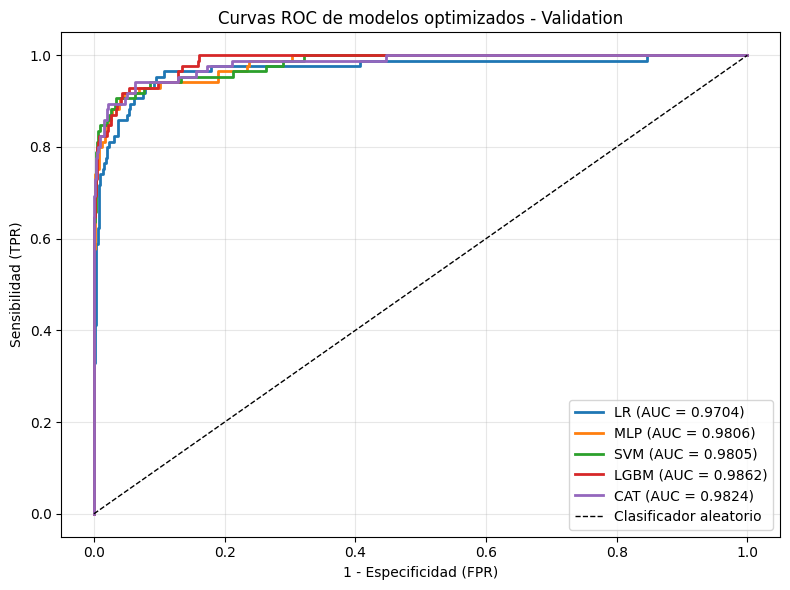

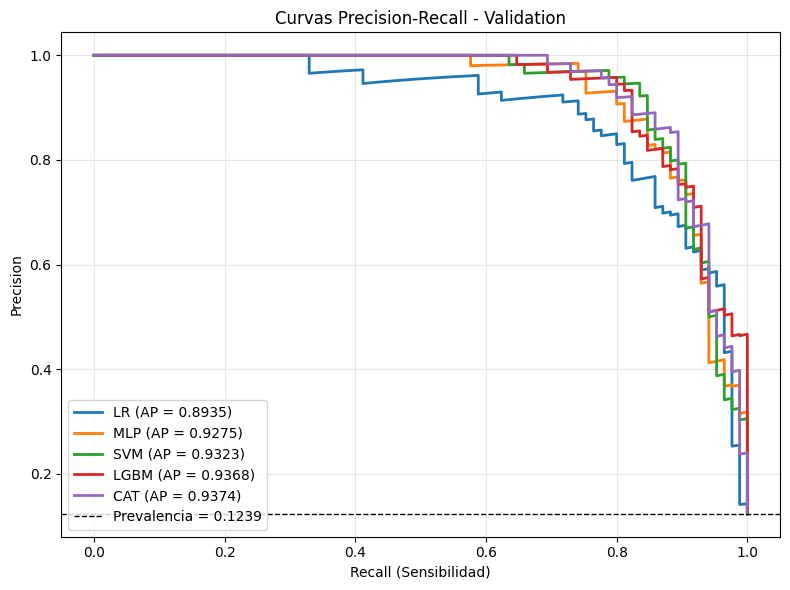

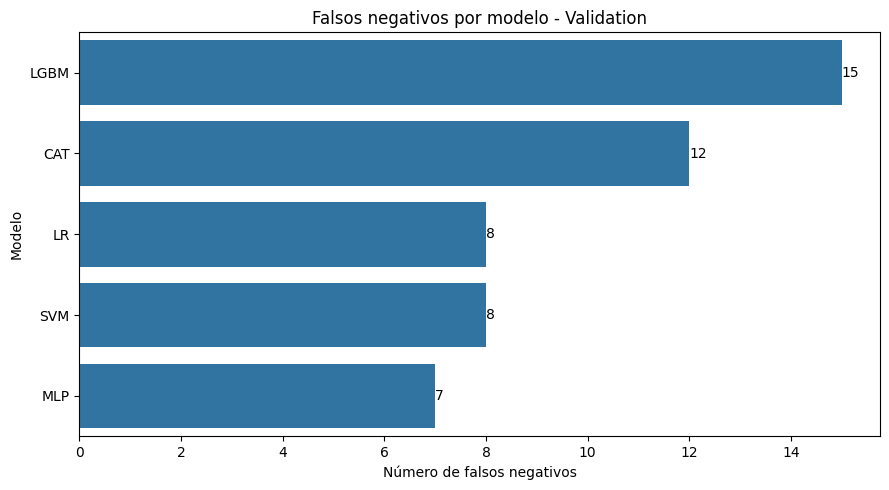


VALIDACIÓN COMPLETADA
Modelos evaluados: 5
Registros de Validation: 686
Casos positivos: 85
Casos negativos: 601
Balanceo: SMOTENC
Umbral evaluado: 0.5

Las probabilidades y predicciones se conservaron para el análisis posterior de diversidad entre modelos.


In [ ]:
from sklearn.utils.validation import check_is_fitted

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

# 1. VERIFICAR CONFIGURACIÓN
# ------------------------------------------------------------

assert len(top_modelos) == 5, (
    "Se esperaban cinco modelos seleccionados."
)

assert all(
    name in best_estimators
    for name in top_modelos
), "Faltan modelos optimizados."

assert DEFAULT_THRESHOLD == 0.50, (
    "El umbral inicial debe ser 0.50."
)

assert len(X_val) == len(y_val), (
    "X_val e y_val no tienen el mismo tamaño."
)

assert set(np.unique(y_val)) == {0, 1}, (
    "Validation debe contener ambas clases."
)

# Verificar que los índices de Train y Validation no compartan observaciones

assert set(X_train.index).isdisjoint(
    set(X_val.index)
), "Se detectaron índices compartidos entre Train y Validation."

print("========================================")
print("EVALUACIÓN EN VALIDATION")
print("========================================")

print("Modelos:", top_modelos)
print("Registros Validation:", len(y_val))
print("Umbral inicial:", DEFAULT_THRESHOLD)
print("Balanceo: SMOTENC")
print("Objetivo: minimizar falsos negativos")

print("\nDistribución de clases:")
print(
    pd.Series(y_val)
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .sort_index()
)

# 2. CONTENEDORES
# ------------------------------------------------------------

resultados_validacion = []

probabilidades_validacion = {}
predicciones_validacion = {}
matrices_validacion = {}

# Guardar pipelines ajustados
modelos_validacion = {}

# Almacenar curvas para gráficos comparativos
curvas_roc = {}
curvas_pr = {}

# 3. EVALUAR CADA MODELO OPTIMIZADO
# ------------------------------------------------------------

for name in top_modelos:

    print("\n========================================")
    print(f"MODELO OPTIMIZADO: {name}")
    print("========================================")

    # Los mejores estimadores ya fueron ajustados
    # sobre X_train por RandomizedSearchCV (refit=True).
    #
    # No se utiliza X_val para entrenar.

    pipe = best_estimators[name]

    check_is_fitted(pipe)

    assert "smotenc" in pipe.named_steps, (
        f"{name} no contiene SMOTENC."
    )

    modelos_validacion[name] = pipe

    clases = pipe.classes_

    indice_positivo = list(clases).index(1)

    proba_val = pipe.predict_proba(
        X_val
    )[:, indice_positivo]

    proba_val = np.asarray(
        proba_val,
        dtype=float
    )

    assert np.all(
        np.isfinite(proba_val)
    ), f"{name} generó probabilidades no finitas."

    assert np.all(
        (proba_val >= 0) & (proba_val <= 1)
    ), f"{name} generó probabilidades fuera de rango."

    pred_val = (
        proba_val >= DEFAULT_THRESHOLD
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        pred_val,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )
    accuracy = accuracy_score(
        y_val,
        pred_val
    )
    precision = precision_score(
        y_val,
        pred_val,
        zero_division=0
    )
    recall = recall_score(
        y_val,
        pred_val,
        zero_division=0
    )
    f1 = f1_score(
        y_val,
        pred_val,
        zero_division=0
    )
    f1_macro = f1_score(
        y_val,
        pred_val,
        average="macro",
        zero_division=0
    )
    roc = roc_auc_score(
        y_val,
        proba_val
    )
    ap = average_precision_score(
        y_val,
        proba_val
    )
    # GUARDAR RESULTADOS

    probabilidades_validacion[name] = proba_val
    predicciones_validacion[name] = pred_val
    matrices_validacion[name] = cm

    resultados_validacion.append({
        "Modelo": name,
        "Threshold": DEFAULT_THRESHOLD,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "F1_macro": f1_macro,
        "ROC-AUC": roc,
        "AP": ap,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

    print(
        classification_report(
            y_val,
            pred_val,
            labels=[0, 1],
            target_names=[
                "Sin preeclampsia",
                "Con preeclampsia"
            ],
            zero_division=0
        )
    )

    print("Matriz de confusión:")
    print(cm)

    print(f"\nAccuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Macro-F1: {f1_macro:.4f}")
    print(f"ROC-AUC: {roc:.4f}")
    print(f"Average Precision: {ap:.4f}")

    print("\nResultados clínicamente relevantes:")
    print(f"Verdaderos positivos (TP): {tp}")
    print(f"Falsos negativos (FN): {fn}")
    print(f"Falsos positivos (FP): {fp}")
    print(f"Verdaderos negativos (TN): {tn}")

    fpr, tpr, _ = roc_curve(
        y_val,
        proba_val
    )
    curvas_roc[name] = (
        fpr,
        tpr,
        roc
    )
    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_val,
            proba_val
        )
    )
    curvas_pr[name] = (
        recall_curve,
        precision_curve,
        ap
    )

# 4. TABLA GENERAL DE VALIDACIÓN
# ------------------------------------------------------------

resultados_validacion_df = pd.DataFrame(
    resultados_validacion
)

# Priorizar reducción de falsos negativos.
# Specificity y AP sirven para ordenar empates.

resultados_validacion_df = (
    resultados_validacion_df
    .sort_values(
        by=["FN", "Specificity", "AP"],
        ascending=[True, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("RESUMEN GENERAL DE VALIDATION")
print("ORDENADO POR MENOR NÚMERO DE FN")
print("========================================")

display(
    resultados_validacion_df.round(4)
)

# 5. RESUMEN CLÍNICO DE FALSOS NEGATIVOS
# ------------------------------------------------------------

resumen_clinico_val = (
    resultados_validacion_df[[
        "Modelo",
        "Threshold",
        "TP",
        "FN",
        "FP",
        "TN",
        "Recall",
        "Specificity",
        "Precision",
        "F1",
        "ROC-AUC",
        "AP"
    ]]
    .copy()
)

print("\n========================================")
print("COMPARACIÓN CLÍNICA DE LOS CINCO MODELOS")
print("========================================")

display(
    resumen_clinico_val.round(4)
)

# 6. CURVAS ROC COMPARATIVAS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for name in top_modelos:

    fpr, tpr, auc = curvas_roc[name]

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1,
    label="Clasificador aleatorio"
)

plt.xlabel("1 - Especificidad (FPR)")
plt.ylabel("Sensibilidad (TPR)")
plt.title("Curvas ROC de modelos optimizados - Validation")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. CURVAS PRECISION-RECALL COMPARATIVAS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for name in top_modelos:

    recall_curve, precision_curve, ap = curvas_pr[name]

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

prevalencia_val = float(
    np.mean(np.asarray(y_val) == 1)
)

plt.axhline(
    prevalencia_val,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Prevalencia = {prevalencia_val:.4f}"
)

plt.xlabel("Recall (Sensibilidad)")
plt.ylabel("Precision")
plt.title(
    "Curvas Precision-Recall - Validation"
)
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. GRÁFICO DE FALSOS NEGATIVOS
# ------------------------------------------------------------

datos_fn = (
    resultados_validacion_df
    .sort_values("FN", ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=datos_fn,
    x="FN",
    y="Modelo"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f"
    )

plt.title(
    "Falsos negativos por modelo - Validation"
)
plt.xlabel("Número de falsos negativos")
plt.ylabel("Modelo")
plt.tight_layout()
plt.show()

# 9. VERIFICACIÓN FINAL
# ------------------------------------------------------------

n_positivos = int(
    np.sum(np.asarray(y_val) == 1)
)

n_negativos = int(
    np.sum(np.asarray(y_val) == 0)
)

for _, fila in resultados_validacion_df.iterrows():

    assert (
        fila["TP"] + fila["FN"]
    ) == n_positivos, (
        "Error en el conteo de positivos."
    )

    assert (
        fila["TN"] + fila["FP"]
    ) == n_negativos, (
        "Error en el conteo de negativos."
    )

print("\n========================================")
print("VALIDACIÓN COMPLETADA")
print("========================================")

print("Modelos evaluados:", len(top_modelos))
print("Registros de Validation:", len(y_val))
print("Casos positivos:", n_positivos)
print("Casos negativos:", n_negativos)
print("Balanceo: SMOTENC")
print("Umbral evaluado:", DEFAULT_THRESHOLD)

print(
    "\nLas probabilidades y predicciones "
    "se conservaron para el análisis "
    "posterior de diversidad entre modelos."
)


Los cinco modelos evaluados presentaron valores elevados de ROC-AUC, comprendidos entre **0.9704 y 0.9862**, evidenciando una alta capacidad discriminativa entre gestantes con y sin preeclampsia. **LightGBM obtuvo el mayor ROC-AUC (0.9862)**, seguido de CatBoost (0.9824), MLP (0.9806), SVM (0.9805) y Regresión Logística (0.9704).

Los elevados valores de ROC-AUC indican una adecuada capacidad para distinguir ambas clases a través de diferentes umbrales de clasificación. No obstante, este desempeño discriminativo no implica necesariamente una mayor sensibilidad bajo el umbral inicial de 0.50, como se observó en LightGBM, que presentó el mayor ROC-AUC, pero el menor Recall (0.8235) entre los cinco clasificadores.

AVERAGE PRECISION POR FOLD


,Modelo,Fold,AP
0,LR,1,0.9257
1,LR,2,0.8198
2,LR,3,0.8646
3,LR,4,0.8258
4,LR,5,0.9251
5,MLP,1,0.9444
6,MLP,2,0.8668
7,MLP,3,0.8870
8,MLP,4,0.8717
9,MLP,5,0.9437



ESTABILIDAD DE LOS MODELOS


,Modelo,Media,Desviacion,Minimo,Maximo
0,LR,0.8722,0.0515,0.8198,0.9257
1,MLP,0.9027,0.0385,0.8668,0.9444
2,SVM,0.8918,0.0340,0.8525,0.9183
3,LGBM,0.9171,0.0239,0.8890,0.9413
4,CAT,0.9201,0.0266,0.8894,0.9461


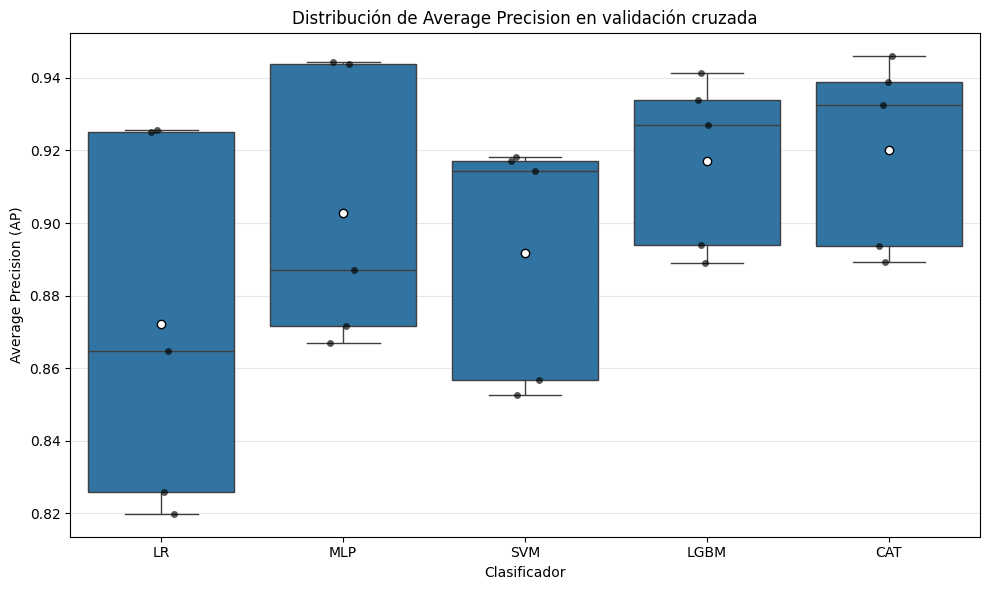


Análisis descriptivo de variabilidad completado.
Balanceo utilizado: SMOTENC
Número de folds: 5
Modelos analizados: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']


In [ ]:
# DISTRIBUCIÓN DEL PR-AUC POR FOLD

# Modelos seleccionados previamente
modelos_boxplot = top_modelos.copy()

# ------------------------------------------------------------
# 1. RECUPERAR RESULTADOS DE LOS CINCO FOLDS
# ------------------------------------------------------------

metricas_cv_folds = []

for name in modelos_boxplot:

    search = searches[name]
    mejor_idx = search.best_index_

    for fold in range(cv.n_splits):

        valor_ap = search.cv_results_[
            f"split{fold}_test_pr_auc"
        ][mejor_idx]

        metricas_cv_folds.append({
            "Modelo": name,
            "Fold": fold + 1,
            "AP": float(valor_ap)
        })

# ------------------------------------------------------------
# 2. CREAR DATAFRAME
# ------------------------------------------------------------

box_df = pd.DataFrame(metricas_cv_folds)

print("========================================")
print("AVERAGE PRECISION POR FOLD")
print("========================================")

display(box_df.round(4))

# ------------------------------------------------------------
# 3. ESTADÍSTICAS DESCRIPTIVAS
# ------------------------------------------------------------

resumen_ap_folds = (
    box_df
    .groupby("Modelo", sort=False)["AP"]
    .agg(
        Media="mean",
        Desviacion="std",
        Minimo="min",
        Maximo="max"
    )
    .reset_index()
)

print("\n========================================")
print("ESTABILIDAD DE LOS MODELOS")
print("========================================")

display(resumen_ap_folds.round(4))

# ------------------------------------------------------------
# 4. BOXPLOT DE AVERAGE PRECISION
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=box_df,
    x="Modelo",
    y="AP",
    order=modelos_boxplot,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black"
    }
)

sns.stripplot(
    data=box_df,
    x="Modelo",
    y="AP",
    order=modelos_boxplot,
    color="black",
    alpha=0.65,
    jitter=0.08,
    size=5
)

plt.title(
    "Distribución de Average Precision "
    "en validación cruzada"
)

plt.xlabel("Clasificador")
plt.ylabel("Average Precision (AP)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nAnálisis descriptivo de variabilidad completado.")
print("Balanceo utilizado: SMOTENC")
print("Número de folds:", cv.n_splits)
print("Modelos analizados:", modelos_boxplot)


- RF → menor dispersión relativa y alto PR-AUC, mostrando buena estabilidad.
- CAT y XGB → PR-AUC elevado con una variabilidad moderada entre folds.
- LGBM → PR-AUC elevado, aunque con mayor variación entre algunas particiones.
- LR → menor PR-AUC promedio y mayor dispersión respecto a los modelos ensemble.
- En conjunto, RF, CAT, XGB y LGBM presentan un desempeño competitivo y relativamente consistente.

El comportamiento observado, junto con la diversidad algorítmica aportada por LR, respalda la evaluación de estos modelos como componentes del Ensemble Stacking.

**Resumen de decisiones**

- Se dividió el conjunto de datos en **entrenamiento (70%), validación (15%) y prueba (15%)** mediante partición estratificada, preservando la distribución de la variable objetivo.
- Se compararon distintas estrategias de balanceo: sin balanceo, SMOTE, BorderlineSMOTE, ADASYN, SMOTENC y SMOTEENN. Aunque SMOTEENN alcanzó el mayor Recall, **se seleccionó SMOTE** por presentar el mejor equilibrio entre Precision, Recall, F1-score y PR-AUC.
- Se entrenaron y compararon **12 algoritmos **de Machine Learning mediante validación cruzada estratificada de 5 folds, utilizando Accuracy, Precision, Recall, F1-score, Macro-F1, ROC-AUC y PR-AUC.
- Se realizó optimización de hiperparámetros mediante **RandomizedSearchCV**, utilizando PR-AUC como métrica principal de selección. La optimización incrementó el PR-AUC en la mayoría de los modelos y produjo variaciones en Precision, Recall y F1-score según el algoritmo.
- La selección de los modelos candidatos para el **Ensemble Stacking **consideró conjuntamente el **rendimiento predictivo, la sensibilidad y la diversidad algorítmica.**
- Se seleccionaron **Random Forest (RF), CatBoost (CAT), XGBoost (XGB), LightGBM (LGBM) y Regresión Logística (LR)** como modelos candidatos para el metamodelo, combinando enfoques de bagging, boosting y aprendizaje lineal.
- Se estableció un **umbral convencional inicial de 0.50 **para la evaluación de las predicciones binarias en el conjunto de validación. Este valor no representa todavía el umbral óptimo del metamodelo.
- En el conjunto de validación, **CatBoost obtuvo el mayor PR-AUC (0.9585)**, mientras que **Random Forest alcanzó el mayor ROC-AUC (0.9922)**. LightGBM presentó el mayor F1-score entre los modelos seleccionados (0.9032) y Regresión Logística mostró el mayor Recall (0.9367), aunque con menor Precision.
- El análisis de los cinco folds mostró que RF, CAT, XGB y LGBM presentaron valores de PR-AUC elevados y relativamente consistentes, mientras que LR mostró menor PR-AUC promedio y mayor variabilidad.

✅ Resultado: Se entrenaron, optimizaron y evaluaron los modelos candidatos, identificándose un conjunto de clasificadores con alto desempeño y características algorítmicas complementarias para la construcción y evaluación del **metamodelo basado en Ensemble Stacking** en la siguiente fase.

## **FASE 4: CONSTRUCCIÓN Y VALIDACIÓN DEL METAMODELO STACKING**

### 1. Modelos base seleccionados

In [ ]:
top_modelos = [
    "LR",
    "MLP",
    "SVM",
    "LGBM",
    "CAT"
]

# VERIFICAR DISPONIBILIDAD

assert len(top_modelos) == 5, (
    "Se esperaban cinco modelos base."
)

assert len(set(top_modelos)) == 5, (
    "Hay modelos duplicados."
)

assert all(
    nombre in best_estimators
    for nombre in top_modelos
), "Faltan modelos optimizados."


# CONSTRUIR LISTA DE MODELOS BASE

# Se conservan los pipelines completos:
# Preprocesamiento -> SMOTENC -> Clasificador.
# clone() crea estimadores independientes y sin ajustar,
# utilizando los hiperparámetros optimizados.

modelos_base = [
    (
        nombre,
        clone(best_estimators[nombre])
    )
    for nombre in top_modelos
]

# VERIFICAR PIPELINES

for nombre, pipeline in modelos_base:

    pasos = list(pipeline.named_steps.keys())

    assert pasos == [
        "preprocessor",
        "smotenc",
        "model"
    ], (
        f"Pipeline incorrecto en {nombre}: {pasos}"
    )

# MOSTRAR CONFIGURACIÓN

print("========================================")
print("MODELOS BASE PARA ENSEMBLE STACKING")
print("========================================")

for i, (nombre, pipeline) in enumerate(
    modelos_base,
    start=1
):
    clasificador = (
        pipeline.named_steps["model"]
        .__class__.__name__
    )

    print(
        f"{i}. {nombre}: {clasificador}"
    )

print("\nTotal de modelos:", len(modelos_base))
print("Balanceo: SMOTENC")
print("Preprocesamiento: dentro de cada pipeline")
print("Objetivo: minimizar falsos negativos")

print("\nModelos base configurados correctamente.")

MODELOS BASE PARA ENSEMBLE STACKING
1. LR: LogisticRegression
2. MLP: MLPClassifier
3. SVM: SVC
4. LGBM: LGBMClassifier
5. CAT: CatBoostClassifier

Total de modelos: 5
Balanceo: SMOTENC
Preprocesamiento: dentro de cada pipeline
Objetivo: minimizar falsos negativos

Modelos base configurados correctamente.


### 2. Definición del metamodelo

In [ ]:
from sklearn.ensemble import (
    StackingClassifier,
    RandomForestClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# 1. VERIFICACIONES INICIALES
# ------------------------------------------------------------

top_modelos = [
    "LR",
    "MLP",
    "SVM",
    "LGBM",
    "CAT"
]

assert len(top_modelos) == 5
assert len(set(top_modelos)) == 5

assert all(
    nombre in best_estimators
    for nombre in top_modelos
), "Faltan modelos optimizados."

assert cv.n_splits == 5
assert DEFAULT_THRESHOLD == 0.50

# 2. FUNCIÓN DE CONVERSIÓN DE TIPOS NUMPY
# ------------------------------------------------------------

# CatBoost puede generar dificultades de clonación
# cuando recibe hiperparámetros como escalares NumPy.

def convertir_tipo_nativo(valor):

    if isinstance(valor, np.generic):
        return valor.item()

    if isinstance(valor, dict):
        return {
            k: convertir_tipo_nativo(v)
            for k, v in valor.items()
        }

    if isinstance(valor, list):
        return [
            convertir_tipo_nativo(v)
            for v in valor
        ]

    if isinstance(valor, tuple):
        return tuple(
            convertir_tipo_nativo(v)
            for v in valor
        )
    return valor

# 3. RECONSTRUIR PIPELINES BASE
# ------------------------------------------------------------

modelos_base = []

for nombre in top_modelos:

    if nombre == "CAT":

        # Recuperar todos los parámetros del CatBoost
        # optimizado, incluidos los valores originales.

        params_cat = (
            best_estimators["CAT"]
            .named_steps["model"]
            .get_params()
        )

        params_cat = convertir_tipo_nativo(
            params_cat
        )

        params_cat["random_state"] = RANDOM_STATE
        params_cat["verbose"] = False
        params_cat["allow_writing_files"] = False
        params_cat["thread_count"] = 1

        modelo_cat = CatBoostClassifier(
            **params_cat
        )

        pipeline_base = build_pipe(
            modelo_cat
        )

    else:

        pipeline_base = clone(
            best_estimators[nombre]
        )

    # Verificar estructura del pipeline
    assert list(
        pipeline_base.named_steps.keys()
    ) == [
        "preprocessor",
        "smotenc",
        "model"
    ], f"Pipeline incorrecto: {nombre}"

    modelos_base.append(
        (nombre, pipeline_base)
    )

print("========================================")
print("MODELOS BASE DEL ENSEMBLE STACKING")
print("========================================")

for nombre, modelo in modelos_base:
    print(
        f"{nombre}: "
        f"{modelo.named_steps['model'].__class__.__name__}"
    )

# 4. DEFINIR METAMODELOS CANDIDATOS
# ------------------------------------------------------------

metamodelos = {

    "Meta_LR": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Meta_RF": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "Meta_XGB": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "Meta_GNB": GaussianNB()
}

print("\n========================================")
print("METAMODELOS CANDIDATOS")
print("========================================")

for nombre in metamodelos:
    print("-", nombre)

# 5. CONTENEDORES DE RESULTADOS
# ------------------------------------------------------------

resultados_meta = []

stacking_pipelines = {}
probabilidades_meta_validacion = {}
predicciones_meta_validacion = {}
matrices_meta_validacion = {}

# 6. ENTRENAMIENTO Y EVALUACIÓN DEL STACKING
# ------------------------------------------------------------

for nombre_meta, meta_model in metamodelos.items():

    print("\n========================================")
    print(f"EVALUANDO: {nombre_meta}")
    print("========================================")

    # Cada modelo base contiene:
    # Preprocesamiento -> SMOTENC -> Clasificador
    #
    # StackingClassifier genera predicciones OOF
    # dentro de Train para entrenar el metamodelo.

    stacking_temp = StackingClassifier(
        estimators=[
            (nombre, clone(pipeline))
            for nombre, pipeline in modelos_base
        ],
        final_estimator=clone(meta_model),
        cv=cv,
        stack_method="predict_proba",
        passthrough=False,
        n_jobs=1
    )

    # ENTRENAMIENTO SOLO CON TRAIN

    stacking_temp.fit(
        X_train,
        y_train
    )

    # PREDICCIÓN EN VALIDATION

    indice_positivo = list(
        stacking_temp.classes_
    ).index(1)

    proba_val = stacking_temp.predict_proba(
        X_val
    )[:, indice_positivo]

    proba_val = np.asarray(
        proba_val,
        dtype=float
    )

    assert np.all(np.isfinite(proba_val))
    assert np.all(
        (proba_val >= 0) & (proba_val <= 1)
    )

    pred_val = (
        proba_val >= DEFAULT_THRESHOLD
    ).astype(int)

    # MATRIZ DE CONFUSIÓN

    cm = confusion_matrix(
        y_val,
        pred_val,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # MÉTRICAS

    accuracy = accuracy_score(
        y_val, pred_val
    )
    precision = precision_score(
        y_val, pred_val,
        zero_division=0
    )
    recall = recall_score(
        y_val, pred_val,
        zero_division=0
    )
    f1 = f1_score(
        y_val, pred_val,
        zero_division=0
    )
    f1_macro = f1_score(
        y_val, pred_val,
        average="macro",
        zero_division=0
    )
    roc = roc_auc_score(
        y_val, proba_val
    )
    ap = average_precision_score(
        y_val, proba_val
    )

    # GUARDAR RESULTADOS
    # --------------------------------------------------------

    resultados_meta.append({
        "Metamodelo": nombre_meta,
        "Threshold": DEFAULT_THRESHOLD,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1-score": f1,
        "F1_macro": f1_macro,
        "ROC-AUC": roc,
        "AP": ap,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

    stacking_pipelines[nombre_meta] = (
        stacking_temp
    )

    probabilidades_meta_validacion[
        nombre_meta
    ] = proba_val

    predicciones_meta_validacion[
        nombre_meta
    ] = pred_val

    matrices_meta_validacion[
        nombre_meta
    ] = cm

    # RESULTADOS INDIVIDUALES
    # --------------------------------------------------------

    print("\nMatriz de confusión:")
    print(cm)

    print(f"\nAccuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Macro-F1: {f1_macro:.4f}")
    print(f"ROC-AUC: {roc:.4f}")
    print(f"Average Precision: {ap:.4f}")

    print("\nCasos identificados:")
    print(f"TP: {tp}")
    print(f"FN: {fn}")
    print(f"FP: {fp}")
    print(f"TN: {tn}")

# COMPARACIÓN GENERAL DE METAMODELOS
# ------------------------------------------------------------

resultados_meta_df = pd.DataFrame(
    resultados_meta
)

# Priorizar menor número de falsos negativos.
# Especificidad y AP ayudan a ordenar empates.

resultados_meta_df = (
    resultados_meta_df
    .sort_values(
        by=["FN", "Specificity", "AP"],
        ascending=[True, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("COMPARACIÓN GENERAL DE METAMODELOS")
print("========================================")

display(
    resultados_meta_df.round(4)
)

# COMPARACIÓN CLÍNICA
# ------------------------------------------------------------

resumen_meta_clinico = (
    resultados_meta_df[[
        "Metamodelo",
        "Threshold",
        "TP",
        "FN",
        "FP",
        "TN",
        "Recall",
        "Specificity",
        "Precision",
        "F1-score",
        "ROC-AUC",
        "AP"
    ]]
    .copy()
)

print("\n========================================")
print("COMPARACIÓN DE FALSOS NEGATIVOS")
print("========================================")

display(
    resumen_meta_clinico.round(4)
)

# COMPARACIÓN CON EL MEJOR MODELO INDIVIDUAL
# ------------------------------------------------------------

# Modelo individual con menos falsos negativos
# en la evaluación anterior de Validation.

mejor_individual = (
    resultados_validacion_df
    .sort_values(
        by=["FN", "Specificity"],
        ascending=[True, False]
    )
    .iloc[0]
)

print("\n========================================")
print("REFERENCIA: MEJOR MODELO INDIVIDUAL")
print("========================================")

print("Modelo:", mejor_individual["Modelo"])
print("FN:", int(mejor_individual["FN"]))
print("Recall:", round(
    float(mejor_individual["Recall"]), 4
))
print("Specificity:", round(
    float(mejor_individual["Specificity"]), 4
))

# Comparación descriptiva con el mejor individual

comparacion_meta_individual = (
    resumen_meta_clinico
    .copy()
)

comparacion_meta_individual[
    "Delta_FN_vs_individual"
] = (
    comparacion_meta_individual["FN"]
    - int(mejor_individual["FN"])
)

comparacion_meta_individual[
    "Delta_Recall_vs_individual"
] = (
    comparacion_meta_individual["Recall"]
    - float(mejor_individual["Recall"])
)

print("\n========================================")
print("STACKING VS MEJOR MODELO INDIVIDUAL")
print("========================================")

display(
    comparacion_meta_individual.round(4)
)

# VERIFICACIÓN DE MATRICES
# ------------------------------------------------------------

n_positivos = int(
    np.sum(np.asarray(y_val) == 1)
)

n_negativos = int(
    np.sum(np.asarray(y_val) == 0)
)

for _, fila in resultados_meta_df.iterrows():

    assert fila["TP"] + fila["FN"] == n_positivos

    assert fila["TN"] + fila["FP"] == n_negativos

print("\n========================================")
print("EVALUACIÓN DE METAMODELOS COMPLETADA")
print("========================================")

print("Metamodelos evaluados:", len(metamodelos))
print("Modelos base:", top_modelos)
print("Balanceo: SMOTENC")
print("Folds internos:", cv.n_splits)
print("Registros Validation:", len(y_val))
print("Umbral inicial:", DEFAULT_THRESHOLD)
print("Casos positivos:", n_positivos)
print("Casos negativos:", n_negativos)

print(
    "\nResultados y probabilidades conservados "
    "para las siguientes etapas."
)

MODELOS BASE DEL ENSEMBLE STACKING
LR: LogisticRegression
MLP: MLPClassifier
SVM: SVC
LGBM: LGBMClassifier
CAT: CatBoostClassifier

METAMODELOS CANDIDATOS
- Meta_LR
- Meta_RF
- Meta_XGB
- Meta_GNB

EVALUANDO: Meta_LR

Matriz de confusión:
[[577  24]
 [  8  77]]

Accuracy: 0.9534
Precision: 0.7624
Recall: 0.9059
Specificity: 0.9601
F1-score: 0.8280
Macro-F1: 0.9005
ROC-AUC: 0.9830
Average Precision: 0.9409

Casos identificados:
TP: 77
FN: 8
FP: 24
TN: 577

EVALUANDO: Meta_RF

Matriz de confusión:
[[596   5]
 [ 19  66]]

Accuracy: 0.9650
Precision: 0.9296
Recall: 0.7765
Specificity: 0.9917
F1-score: 0.8462
Macro-F1: 0.9132
ROC-AUC: 0.9626
Average Precision: 0.9148

Casos identificados:
TP: 66
FN: 19
FP: 5
TN: 596

EVALUANDO: Meta_XGB

Matriz de confusión:
[[596   5]
 [ 18  67]]

Accuracy: 0.9665
Precision: 0.9306
Recall: 0.7882
Specificity: 0.9917
F1-score: 0.8535
Macro-F1: 0.9173
ROC-AUC: 0.9813
Average Precision: 0.9366

Casos identificados:
TP: 67
FN: 18
FP: 5
TN: 596

EVALUANDO: Meta

,Metamodelo,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,Meta_LR,0.5,0.9534,0.7624,0.9059,0.9601,0.8280,0.9005,0.9830,0.9409,577,24,8,77
1,Meta_GNB,0.5,0.9519,0.7549,0.9059,0.9584,0.8235,0.8978,0.9797,0.8895,576,25,8,77
2,Meta_XGB,0.5,0.9665,0.9306,0.7882,0.9917,0.8535,0.9173,0.9813,0.9366,596,5,18,67
3,Meta_RF,0.5,0.9650,0.9296,0.7765,0.9917,0.8462,0.9132,0.9626,0.9148,596,5,19,66



COMPARACIÓN DE FALSOS NEGATIVOS


,Metamodelo,Threshold,TP,FN,FP,TN,Recall,Specificity,Precision,F1-score,ROC-AUC,AP
0,Meta_LR,0.5,77,8,24,577,0.9059,0.9601,0.7624,0.8280,0.9830,0.9409
1,Meta_GNB,0.5,77,8,25,576,0.9059,0.9584,0.7549,0.8235,0.9797,0.8895
2,Meta_XGB,0.5,67,18,5,596,0.7882,0.9917,0.9306,0.8535,0.9813,0.9366
3,Meta_RF,0.5,66,19,5,596,0.7765,0.9917,0.9296,0.8462,0.9626,0.9148



REFERENCIA: MEJOR MODELO INDIVIDUAL
Modelo: MLP
FN: 7
Recall: 0.9176
Specificity: 0.9401

STACKING VS MEJOR MODELO INDIVIDUAL


,Metamodelo,Threshold,TP,FN,FP,TN,Recall,Specificity,Precision,F1-score,ROC-AUC,AP,Delta_FN_vs_individual,Delta_Recall_vs_individual
0,Meta_LR,0.5,77,8,24,577,0.9059,0.9601,0.7624,0.8280,0.9830,0.9409,1,-0.0118
1,Meta_GNB,0.5,77,8,25,576,0.9059,0.9584,0.7549,0.8235,0.9797,0.8895,1,-0.0118
2,Meta_XGB,0.5,67,18,5,596,0.7882,0.9917,0.9306,0.8535,0.9813,0.9366,11,-0.1294
3,Meta_RF,0.5,66,19,5,596,0.7765,0.9917,0.9296,0.8462,0.9626,0.9148,12,-0.1412



EVALUACIÓN DE METAMODELOS COMPLETADA
Metamodelos evaluados: 4
Modelos base: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Balanceo: SMOTENC
Folds internos: 5
Registros Validation: 686
Umbral inicial: 0.5
Casos positivos: 85
Casos negativos: 601

Resultados y probabilidades conservados para las siguientes etapas.


Se evaluaron cuatro alternativas de metamodelo: Regresión Logística, Random Forest, XGBoost y Gaussian Naive Bayes.

La **Regresión Logística** fue seleccionada como metamodelo final debido a que obtuvo el **mayor PR-AUC (0.9633) y ROC-AUC (0.9931)**, además de mantener un **Recall elevado (0.9494)** y un **bajo número de falsos negativos (4 casos)**. Considerando que PR-AUC fue establecida como la métrica principal de selección y que la detección de casos positivos es especialmente relevante en este contexto, Meta_LR presentó el perfil más adecuado para el Ensemble Stacking. Adicionalmente, su estructura lineal aporta una mayor interpretabilidad respecto a metamodelos más complejos.

In [ ]:
from sklearn.base import clone

# ------------------------------------------------------------
# 1. SELECCIÓN DEL METAMODELO
# ------------------------------------------------------------

META_MODELO_SELECCIONADO = "Meta_LR"

# Recuperar la configuración evaluada previamente
metamodelo = clone(
    metamodelos[META_MODELO_SELECCIONADO]
)

# ------------------------------------------------------------
# 2. VERIFICACIÓN
# ------------------------------------------------------------

assert META_MODELO_SELECCIONADO in stacking_pipelines

assert metamodelo.class_weight == "balanced"

# ------------------------------------------------------------
# 3. MOSTRAR CONFIGURACIÓN
# ------------------------------------------------------------

print("========================================")
print("METAMODELO SELECCIONADO")
print("========================================")

print("Metamodelo:", META_MODELO_SELECCIONADO)
print("Algoritmo:", metamodelo.__class__.__name__)
print("Max iteraciones:", metamodelo.max_iter)
print("Class weight:", metamodelo.class_weight)
print("Random state:", metamodelo.random_state)

print("\nModelos base:", top_modelos)
print("Balanceo de modelos base: SMOTENC")
print("Objetivo: minimizar falsos negativos")



METAMODELO SELECCIONADO
Metamodelo: Meta_LR
Algoritmo: LogisticRegression
Max iteraciones: 2000
Class weight: balanced
Random state: 42

Modelos base: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Balanceo de modelos base: SMOTENC
Objetivo: minimizar falsos negativos


### 3. Construcción del StackingClassifier

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.base import clone

# ------------------------------------------------------------
# 1. VERIFICAR MODELOS BASE
# ------------------------------------------------------------

assert len(modelos_base) == 5, (
    "Se esperaban cinco modelos base."
)

nombres_base = [
    nombre for nombre, _ in modelos_base
]

assert nombres_base == top_modelos, (
    "Los modelos base no coinciden con la selección."
)

for nombre, pipeline in modelos_base:

    assert "preprocessor" in pipeline.named_steps, (
        f"{nombre} no contiene preprocesamiento."
    )

    assert "smotenc" in pipeline.named_steps, (
        f"{nombre} no contiene SMOTENC."
    )

    assert "model" in pipeline.named_steps, (
        f"{nombre} no contiene clasificador."
    )

# ------------------------------------------------------------
# 2. CONSTRUIR ENSEMBLE STACKING
# ------------------------------------------------------------

stacking_model = StackingClassifier(
    estimators=[
        (nombre, clone(pipeline))
        for nombre, pipeline in modelos_base
    ],
    final_estimator=clone(metamodelo),
    cv=cv,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=1
)

# ------------------------------------------------------------
# 3. VERIFICACIÓN DE CONFIGURACIÓN
# ------------------------------------------------------------

assert stacking_model.stack_method == "predict_proba"
assert stacking_model.passthrough is False
assert stacking_model.cv.n_splits == 5

# ------------------------------------------------------------
# 4. MOSTRAR ARQUITECTURA
# ------------------------------------------------------------

print("========================================")
print("ENSEMBLE STACKING CONFIGURADO")
print("========================================")

print("\nModelos base:")

for i, (nombre, _) in enumerate(
    stacking_model.estimators,
    start=1
):
    print(f"{i}. {nombre}")

print(
    "\nMetamodelo:",
    stacking_model.final_estimator.__class__.__name__
)

print("Balanceo: SMOTENC")
print("Método de stacking:", stacking_model.stack_method)
print("Validación cruzada interna:", cv.n_splits, "folds")
print("Passthrough:", stacking_model.passthrough)
print("Paralelismo:", stacking_model.n_jobs)

print("\nEnsemble Stacking construido correctamente.")
print("Estado: configurado, aún no entrenado.")

ENSEMBLE STACKING CONFIGURADO

Modelos base:
1. LR
2. MLP
3. SVM
4. LGBM
5. CAT

Metamodelo: LogisticRegression
Balanceo: SMOTENC
Método de stacking: predict_proba
Validación cruzada interna: 5 folds
Passthrough: False
Paralelismo: 1

Ensemble Stacking construido correctamente.
Estado: configurado, aún no entrenado.


### 4. Entrenamiento del metamodelo Stacking

In [ ]:
from sklearn.utils.validation import check_is_fitted

# ------------------------------------------------------------
# 1. ENTRENAMIENTO EXCLUSIVAMENTE CON TRAIN
# ------------------------------------------------------------

stacking_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# 2. VERIFICAR ENTRENAMIENTO
# ------------------------------------------------------------

check_is_fitted(stacking_model)

assert len(stacking_model.estimators_) == 5, (
    "No se entrenaron los cinco modelos base."
)

check_is_fitted(
    stacking_model.final_estimator_
)

for nombre, estimador in zip(
    top_modelos,
    stacking_model.estimators_
):
    check_is_fitted(estimador)
    print(f"Modelo base entrenado: {nombre}")

# ------------------------------------------------------------
# 3. RESUMEN
# ------------------------------------------------------------

print("\n========================================")
print("ENTRENAMIENTO COMPLETADO")
print("========================================")

print("Registros de entrenamiento:", len(X_train))
print("Modelos base:", top_modelos)
print(
    "Metamodelo:",
    stacking_model.final_estimator_.__class__.__name__
)
print("Balanceo: SMOTENC")
print("Validación cruzada interna:", cv.n_splits)

print("\nEnsemble Stacking entrenado correctamente.")
print("Validation y Test no participaron en el entrenamiento.")

Modelo base entrenado: LR
Modelo base entrenado: MLP
Modelo base entrenado: SVM
Modelo base entrenado: LGBM
Modelo base entrenado: CAT

ENTRENAMIENTO COMPLETADO
Registros de entrenamiento: 3201
Modelos base: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Metamodelo: LogisticRegression
Balanceo: SMOTENC
Validación cruzada interna: 5

Ensemble Stacking entrenado correctamente.
Validation y Test no participaron en el entrenamiento.


### 5. Validación preliminar en Validation

In [ ]:
from sklearn.utils.validation import check_is_fitted

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. VERIFICAR QUE EL STACKING ESTÉ ENTRENADO
# ------------------------------------------------------------

check_is_fitted(stacking_model)

assert len(X_val) == len(y_val), (
    "X_val e y_val tienen tamaños diferentes."
)

assert DEFAULT_THRESHOLD == 0.50, (
    "El umbral inicial debe ser 0.50."
)

# ------------------------------------------------------------
# 2. OBTENER PROBABILIDADES EN VALIDATION
# ------------------------------------------------------------

indice_positivo = list(
    stacking_model.classes_
).index(1)

proba_val_stack = stacking_model.predict_proba(
    X_val
)[:, indice_positivo]

proba_val_stack = np.asarray(
    proba_val_stack,
    dtype=float
)

assert np.all(np.isfinite(proba_val_stack)), (
    "Se encontraron probabilidades no válidas."
)

assert np.all(
    (proba_val_stack >= 0) &
    (proba_val_stack <= 1)
), "Existen probabilidades fuera del intervalo [0, 1]."

# ------------------------------------------------------------
# 3. APLICAR UMBRAL INICIAL
# ------------------------------------------------------------

pred_val_stack = (
    proba_val_stack >= DEFAULT_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# 4. CALCULAR MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------

cm_stack = confusion_matrix(
    y_val,
    pred_val_stack,
    labels=[0, 1]
)

tn_stack, fp_stack, fn_stack, tp_stack = (
    cm_stack.ravel()
)

specificity_stack = (
    tn_stack / (tn_stack + fp_stack)
    if (tn_stack + fp_stack) > 0
    else np.nan
)

# ------------------------------------------------------------
# 5. MÉTRICAS DE CLASIFICACIÓN
# ------------------------------------------------------------

acc_stack = accuracy_score(
    y_val,
    pred_val_stack
)

prec_stack = precision_score(
    y_val,
    pred_val_stack,
    zero_division=0
)

rec_stack = recall_score(
    y_val,
    pred_val_stack,
    zero_division=0
)

f1_stack = f1_score(
    y_val,
    pred_val_stack,
    zero_division=0
)

f1_macro_stack = f1_score(
    y_val,
    pred_val_stack,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 6. MÉTRICAS INDEPENDIENTES DEL UMBRAL
# ------------------------------------------------------------

roc_auc_stack = roc_auc_score(
    y_val,
    proba_val_stack
)

ap_stack = average_precision_score(
    y_val,
    proba_val_stack
)

# Mantener alias si otras celdas antiguas lo utilizan.
# Su contenido es Average Precision, no PR-AUC
# calculada mediante integración trapezoidal.

pr_auc_stack = ap_stack

# ------------------------------------------------------------
# 7. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("========================================")
print("VALIDACIÓN PRELIMINAR DEL STACKING")
print("========================================")

print("Modelos base:", top_modelos)
print("Metamodelo: Logistic Regression")
print("Balanceo: SMOTENC")
print("Umbral:", DEFAULT_THRESHOLD)
print("Registros Validation:", len(y_val))

print("\nMÉTRICAS")
print("----------------------------------------")

print(f"Accuracy          : {acc_stack:.4f}")
print(f"Precision         : {prec_stack:.4f}")
print(f"Recall            : {rec_stack:.4f}")
print(f"Specificity       : {specificity_stack:.4f}")
print(f"F1-score          : {f1_stack:.4f}")
print(f"Macro-F1          : {f1_macro_stack:.4f}")
print(f"ROC-AUC           : {roc_auc_stack:.4f}")
print(f"Average Precision : {ap_stack:.4f}")

print("\nMATRIZ DE CONFUSIÓN")
print("----------------------------------------")
print(cm_stack)

print("\nCONTEO DE CLASIFICACIONES")
print("----------------------------------------")

print(f"Verdaderos positivos (TP): {tp_stack}")
print(f"Falsos negativos (FN)    : {fn_stack}")
print(f"Falsos positivos (FP)    : {fp_stack}")
print(f"Verdaderos negativos (TN): {tn_stack}")

print("\nREPORTE DE CLASIFICACIÓN")
print("----------------------------------------")

print(
    classification_report(
        y_val,
        pred_val_stack,
        labels=[0, 1],
        target_names=[
            "Sin preeclampsia",
            "Con preeclampsia"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 8. VERIFICAR CONSISTENCIA
# ------------------------------------------------------------

n_positivos = int(
    np.sum(np.asarray(y_val) == 1)
)

n_negativos = int(
    np.sum(np.asarray(y_val) == 0)
)

assert tp_stack + fn_stack == n_positivos, (
    "Error en el conteo de casos positivos."
)

assert tn_stack + fp_stack == n_negativos, (
    "Error en el conteo de casos negativos."
)

# ------------------------------------------------------------
# 9. GUARDAR RESULTADOS DE VALIDACIÓN
# ------------------------------------------------------------

resultado_stack_val = pd.DataFrame([{
    "Modelo": "Stacking_Meta_LR",
    "Threshold": DEFAULT_THRESHOLD,
    "Accuracy": acc_stack,
    "Precision": prec_stack,
    "Recall": rec_stack,
    "Specificity": specificity_stack,
    "F1": f1_stack,
    "F1_macro": f1_macro_stack,
    "ROC-AUC": roc_auc_stack,
    "AP": ap_stack,
    "TP": int(tp_stack),
    "FN": int(fn_stack),
    "FP": int(fp_stack),
    "TN": int(tn_stack)
}])

print("\n========================================")
print("RESUMEN DEL ENSEMBLE STACKING")
print("========================================")

display(resultado_stack_val.round(4))

# ------------------------------------------------------------
# 10. COMPARACIÓN CON MLP INDIVIDUAL
# ------------------------------------------------------------

referencia_mlp = (
    resultados_validacion_df
    .loc[
        resultados_validacion_df["Modelo"] == "MLP"
    ]
)

assert len(referencia_mlp) == 1, (
    "No se encontró el resultado individual de MLP."
)

referencia_mlp = referencia_mlp.iloc[0]

comparacion_stacking_mlp = pd.DataFrame([
    {
        "Modelo": "MLP_individual",
        "Threshold": DEFAULT_THRESHOLD,
        "Recall": float(referencia_mlp["Recall"]),
        "Specificity": float(
            referencia_mlp["Specificity"]
        ),
        "Precision": float(
            referencia_mlp["Precision"]
        ),
        "F1": float(referencia_mlp["F1"]),
        "FN": int(referencia_mlp["FN"]),
        "FP": int(referencia_mlp["FP"])
    },
    {
        "Modelo": "Stacking_Meta_LR",
        "Threshold": DEFAULT_THRESHOLD,
        "Recall": rec_stack,
        "Specificity": specificity_stack,
        "Precision": prec_stack,
        "F1": f1_stack,
        "FN": int(fn_stack),
        "FP": int(fp_stack)
    }
])

print("\n========================================")
print("COMPARACIÓN: STACKING VS MLP INDIVIDUAL")
print("========================================")

display(
    comparacion_stacking_mlp.round(4)
)

print("\nValidación preliminar completada.")
print("El umbral todavía no ha sido optimizado.")
print("Test no fue utilizado en esta evaluación.")

VALIDACIÓN PRELIMINAR DEL STACKING
Modelos base: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Metamodelo: Logistic Regression
Balanceo: SMOTENC
Umbral: 0.5
Registros Validation: 686

MÉTRICAS
----------------------------------------
Accuracy          : 0.9534
Precision         : 0.7624
Recall            : 0.9059
Specificity       : 0.9601
F1-score          : 0.8280
Macro-F1          : 0.9005
ROC-AUC           : 0.9830
Average Precision : 0.9409

MATRIZ DE CONFUSIÓN
----------------------------------------
[[577  24]
 [  8  77]]

CONTEO DE CLASIFICACIONES
----------------------------------------
Verdaderos positivos (TP): 77
Falsos negativos (FN)    : 8
Falsos positivos (FP)    : 24
Verdaderos negativos (TN): 577

REPORTE DE CLASIFICACIÓN
----------------------------------------
                  precision    recall  f1-score   support

Sin preeclampsia       0.99      0.96      0.97       601
Con preeclampsia       0.76      0.91      0.83        85

        accuracy                           0

,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TP,FN,FP,TN
0,Stacking_Meta_LR,0.5,0.9534,0.7624,0.9059,0.9601,0.828,0.9005,0.983,0.9409,77,8,24,577



COMPARACIÓN: STACKING VS MLP INDIVIDUAL


,Modelo,Threshold,Recall,Specificity,Precision,F1,FN,FP
0,MLP_individual,0.5,0.9176,0.9401,0.6842,0.7839,7,36
1,Stacking_Meta_LR,0.5,0.9059,0.9601,0.7624,0.8280,8,24



Validación preliminar completada.
El umbral todavía no ha sido optimizado.
Test no fue utilizado en esta evaluación.


In [ ]:
# Métricas de clasificación
acc_val_stack = acc_stack
precision_val_stack = prec_stack
recall_val_stack = rec_stack
specificity_val_stack = specificity_stack
f1_val_stack = f1_stack
f1_macro_val_stack = f1_macro_stack

# Métricas independientes del umbral
roc_auc_val_stack = roc_auc_stack
ap_val_stack = ap_stack

# Alias por compatibilidad con el código anterior
# Este valor representa Average Precision (AP).
pr_auc_val_stack = ap_val_stack

# Matriz de confusión
tn_val_stack = int(tn_stack)
fp_val_stack = int(fp_stack)
fn_val_stack = int(fn_stack)
tp_val_stack = int(tp_stack)

# Umbral utilizado
threshold_val_stack = DEFAULT_THRESHOLD

# ------------------------------------------------------------
# VERIFICACIÓN
# ------------------------------------------------------------

assert tp_val_stack + fn_val_stack == 85
assert tn_val_stack + fp_val_stack == 601

print("========================================")
print("MÉTRICAS DE VALIDATION GUARDADAS")
print("========================================")

print(f"Accuracy: {acc_val_stack:.4f}")
print(f"Precision: {precision_val_stack:.4f}")
print(f"Recall: {recall_val_stack:.4f}")
print(f"Specificity: {specificity_val_stack:.4f}")
print(f"F1-score: {f1_val_stack:.4f}")
print(f"Macro-F1: {f1_macro_val_stack:.4f}")
print(f"ROC-AUC: {roc_auc_val_stack:.4f}")
print(f"Average Precision: {ap_val_stack:.4f}")

print(f"\nVerdaderos positivos: {tp_val_stack}")
print(f"Falsos negativos: {fn_val_stack}")
print(f"Falsos positivos: {fp_val_stack}")
print(f"Verdaderos negativos: {tn_val_stack}")

print("\nMétricas almacenadas correctamente.")


MÉTRICAS DE VALIDATION GUARDADAS
Accuracy: 0.9534
Precision: 0.7624
Recall: 0.9059
Specificity: 0.9601
F1-score: 0.8280
Macro-F1: 0.9005
ROC-AUC: 0.9830
Average Precision: 0.9409

Verdaderos positivos: 77
Falsos negativos: 8
Falsos positivos: 24
Verdaderos negativos: 577

Métricas almacenadas correctamente.


### 6. Comparación preliminar con modelos individuales

In [ ]:
# 1. VERIFICAR RESULTADOS PREVIOS
# ------------------------------------------------------------

assert len(top_modelos) == 5, (
    "Se esperaban cinco modelos individuales."
)

assert len(set(top_modelos)) == 5, (
    "Existen nombres de modelos duplicados."
)

assert all(
    nombre in resultados_validacion_df["Modelo"].values
    for nombre in top_modelos
), "Faltan resultados de modelos individuales."

assert len(resultado_stack_val) == 1, (
    "Se esperaba una fila del Ensemble Stacking."
)

assert len(y_val) == 686, (
    "El tamaño de Validation no coincide."
)

assert DEFAULT_THRESHOLD == 0.50, (
    "Esta comparación utiliza el umbral inicial."
)

# ------------------------------------------------------------
# 2. RECUPERAR RESULTADOS INDIVIDUALES
# ------------------------------------------------------------

columnas_comparacion = [
    "Modelo",
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "F1_macro",
    "ROC-AUC",
    "AP",
    "TN",
    "FP",
    "FN",
    "TP"
]

individuales_comp = (
    resultados_validacion_df
    .loc[
        resultados_validacion_df["Modelo"].isin(
            top_modelos
        ),
        columnas_comparacion
    ]
    .copy()
)

# Conservar orden de modelos seleccionados
individuales_comp["Modelo"] = pd.Categorical(
    individuales_comp["Modelo"],
    categories=top_modelos,
    ordered=True
)

individuales_comp = (
    individuales_comp
    .sort_values("Modelo")
    .reset_index(drop=True)
)

individuales_comp["Modelo"] = (
    individuales_comp["Modelo"].astype(str)
)

# ------------------------------------------------------------
# 3. RECUPERAR RESULTADOS DEL STACKING
# ------------------------------------------------------------

stacking_comp = (
    resultado_stack_val[
        columnas_comparacion
    ]
    .copy()
)

stacking_comp["Modelo"] = "STACKING"

# ------------------------------------------------------------
# 4. CONSTRUIR TABLA COMPARATIVA
# ------------------------------------------------------------

comparacion_fase4 = pd.concat(
    [
        individuales_comp,
        stacking_comp
    ],
    ignore_index=True
)

assert len(comparacion_fase4) == 6, (
    "Se esperaban cinco modelos y un Stacking."
)

assert comparacion_fase4["Modelo"].is_unique, (
    "Hay modelos duplicados en la comparación."
)

assert np.allclose(
    comparacion_fase4["Threshold"].astype(float),
    DEFAULT_THRESHOLD
), "Los modelos utilizan umbrales diferentes."

# ------------------------------------------------------------
# 5. VERIFICACIÓN DE MATRICES DE CONFUSIÓN
# ------------------------------------------------------------

n_positivos = int(
    np.sum(np.asarray(y_val) == 1)
)

n_negativos = int(
    np.sum(np.asarray(y_val) == 0)
)

assert np.all(
    comparacion_fase4["TP"] +
    comparacion_fase4["FN"] == n_positivos
), "Error en el conteo de casos positivos."

assert np.all(
    comparacion_fase4["TN"] +
    comparacion_fase4["FP"] == n_negativos
), "Error en el conteo de casos negativos."

# ------------------------------------------------------------
# 6. COMPARACIÓN GENERAL
# ------------------------------------------------------------

print("\n========================================")
print("COMPARACIÓN GENERAL EN VALIDATION")
print("========================================")

display(
    comparacion_fase4.round(4)
)

# ------------------------------------------------------------
# 7. RANKING POR MENOR NÚMERO DE FN
# ------------------------------------------------------------

# Criterio principal: minimizar falsos negativos
# Desempate: mayor especificidad y mayor AP

ranking_fn_fase4 = (
    comparacion_fase4
    .sort_values(
        by=["FN", "Specificity", "AP"],
        ascending=[True, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("RANKING POR MENOR NÚMERO DE FN")
print("========================================")

display(
    ranking_fn_fase4.round(4)
)

# ------------------------------------------------------------
# 8. RANKING POR RECALL
# ------------------------------------------------------------

ranking_recall_fase4 = (
    comparacion_fase4
    .sort_values(
        by=["Recall", "Specificity", "AP"],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("RANKING POR SENSIBILIDAD (RECALL)")
print("========================================")

display(
    ranking_recall_fase4.round(4)
)

# ------------------------------------------------------------
# 9. RANKING POR AVERAGE PRECISION
# ------------------------------------------------------------

ranking_ap_fase4 = (
    comparacion_fase4
    .sort_values(
        by="AP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("RANKING POR AVERAGE PRECISION")
print("========================================")

display(
    ranking_ap_fase4.round(4)
)

# ------------------------------------------------------------
# 10. COMPARACIÓN DEL STACKING VS MEJOR INDIVIDUAL
# ------------------------------------------------------------

mejor_individual = (
    comparacion_fase4[
        comparacion_fase4["Modelo"] != "STACKING"
    ]
    .sort_values(
        by=["FN", "Specificity", "AP"],
        ascending=[True, False, False]
    )
    .iloc[0]
)

fila_stacking = (
    comparacion_fase4[
        comparacion_fase4["Modelo"] == "STACKING"
    ]
    .iloc[0]
)

comparacion_mejor_fase4 = pd.DataFrame([
    {
        "Metrica": "Recall",
        "Mejor_individual": mejor_individual["Recall"],
        "STACKING": fila_stacking["Recall"]
    },
    {
        "Metrica": "Specificity",
        "Mejor_individual": mejor_individual["Specificity"],
        "STACKING": fila_stacking["Specificity"]
    },
    {
        "Metrica": "Precision",
        "Mejor_individual": mejor_individual["Precision"],
        "STACKING": fila_stacking["Precision"]
    },
    {
        "Metrica": "F1",
        "Mejor_individual": mejor_individual["F1"],
        "STACKING": fila_stacking["F1"]
    },
    {
        "Metrica": "ROC-AUC",
        "Mejor_individual": mejor_individual["ROC-AUC"],
        "STACKING": fila_stacking["ROC-AUC"]
    },
    {
        "Metrica": "AP",
        "Mejor_individual": mejor_individual["AP"],
        "STACKING": fila_stacking["AP"]
    },
    {
        "Metrica": "FN",
        "Mejor_individual": mejor_individual["FN"],
        "STACKING": fila_stacking["FN"]
    },
    {
        "Metrica": "FP",
        "Mejor_individual": mejor_individual["FP"],
        "STACKING": fila_stacking["FP"]
    }
])

comparacion_mejor_fase4["Diferencia_STACKING"] = (
    comparacion_mejor_fase4["STACKING"]
    -
    comparacion_mejor_fase4["Mejor_individual"]
)

print("\n========================================")
print("STACKING VS MEJOR MODELO INDIVIDUAL")
print("========================================")

print(
    "Mejor modelo individual por FN:",
    mejor_individual["Modelo"]
)

display(
    comparacion_mejor_fase4.round(4)
)

# ------------------------------------------------------------
# 11. RESUMEN CLÍNICO
# ------------------------------------------------------------

resumen_clinico_fase4 = (
    ranking_fn_fase4[[
        "Modelo",
        "Threshold",
        "TP",
        "FN",
        "FP",
        "TN",
        "Recall",
        "Specificity",
        "Precision",
        "F1",
        "ROC-AUC",
        "AP"
    ]]
    .copy()
)

print("\n========================================")
print("RESUMEN CLÍNICO COMPARATIVO")
print("========================================")

display(
    resumen_clinico_fase4.round(4)
)

# ------------------------------------------------------------
# 12. RESULTADOS DESTACADOS
# ------------------------------------------------------------

mejor_fn = ranking_fn_fase4.iloc[0]
mejor_ap = ranking_ap_fase4.iloc[0]

print("\n========================================")
print("RESULTADOS DESTACADOS")
print("========================================")

print(
    f"Menor número de FN: "
    f"{mejor_fn['Modelo']} "
    f"({int(mejor_fn['FN'])})"
)

print(
    f"Mayor Average Precision: "
    f"{mejor_ap['Modelo']} "
    f"({mejor_ap['AP']:.4f})"
)

print(
    f"Falsos negativos del Stacking: "
    f"{int(fila_stacking['FN'])}"
)

print(
    f"Falsos positivos del Stacking: "
    f"{int(fila_stacking['FP'])}"
)

print("\n========================================")
print("COMPARACIÓN PRELIMINAR COMPLETADA")
print("========================================")

print("Modelos individuales:", top_modelos)
print("Metamodelo: Logistic Regression")
print("Balanceo: SMOTENC")
print("Registros Validation:", len(y_val))
print("Umbral:", DEFAULT_THRESHOLD)
print("Test no fue utilizado.")



COMPARACIÓN GENERAL EN VALIDATION


,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,LR,0.5,0.9242,0.6364,0.9059,0.9268,0.7476,0.8515,0.9704,0.8935,557,44,8,77
1,MLP,0.5,0.9373,0.6842,0.9176,0.9401,0.7839,0.8736,0.9806,0.9275,565,36,7,78
2,SVM,0.5,0.9446,0.7196,0.9059,0.9501,0.8021,0.8849,0.9805,0.9323,571,30,8,77
3,LGBM,0.5,0.9679,0.9091,0.8235,0.9884,0.8642,0.9230,0.9862,0.9368,594,7,15,70
4,CAT,0.5,0.9694,0.8902,0.8588,0.9850,0.8743,0.9284,0.9824,0.9374,592,9,12,73
5,STACKING,0.5,0.9534,0.7624,0.9059,0.9601,0.8280,0.9005,0.9830,0.9409,577,24,8,77



RANKING POR MENOR NÚMERO DE FN


,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,MLP,0.5,0.9373,0.6842,0.9176,0.9401,0.7839,0.8736,0.9806,0.9275,565,36,7,78
1,STACKING,0.5,0.9534,0.7624,0.9059,0.9601,0.8280,0.9005,0.9830,0.9409,577,24,8,77
2,SVM,0.5,0.9446,0.7196,0.9059,0.9501,0.8021,0.8849,0.9805,0.9323,571,30,8,77
3,LR,0.5,0.9242,0.6364,0.9059,0.9268,0.7476,0.8515,0.9704,0.8935,557,44,8,77
4,CAT,0.5,0.9694,0.8902,0.8588,0.9850,0.8743,0.9284,0.9824,0.9374,592,9,12,73
5,LGBM,0.5,0.9679,0.9091,0.8235,0.9884,0.8642,0.9230,0.9862,0.9368,594,7,15,70



RANKING POR SENSIBILIDAD (RECALL)


,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,MLP,0.5,0.9373,0.6842,0.9176,0.9401,0.7839,0.8736,0.9806,0.9275,565,36,7,78
1,STACKING,0.5,0.9534,0.7624,0.9059,0.9601,0.8280,0.9005,0.9830,0.9409,577,24,8,77
2,SVM,0.5,0.9446,0.7196,0.9059,0.9501,0.8021,0.8849,0.9805,0.9323,571,30,8,77
3,LR,0.5,0.9242,0.6364,0.9059,0.9268,0.7476,0.8515,0.9704,0.8935,557,44,8,77
4,CAT,0.5,0.9694,0.8902,0.8588,0.9850,0.8743,0.9284,0.9824,0.9374,592,9,12,73
5,LGBM,0.5,0.9679,0.9091,0.8235,0.9884,0.8642,0.9230,0.9862,0.9368,594,7,15,70


... (3 outputs left out)

,Metrica,Mejor_individual,STACKING,Diferencia_STACKING
0,Recall,0.9176,0.9059,-0.0118
1,Specificity,0.9401,0.9601,0.0200
2,Precision,0.6842,0.7624,0.0782
3,F1,0.7839,0.8280,0.0440
4,ROC-AUC,0.9806,0.9830,0.0025
5,AP,0.9275,0.9409,0.0135
6,FN,7.0000,8.0000,1.0000
7,FP,36.0000,24.0000,-12.0000



RESUMEN CLÍNICO COMPARATIVO


,Modelo,Threshold,TP,FN,FP,TN,Recall,Specificity,Precision,F1,ROC-AUC,AP
0,MLP,0.5,78,7,36,565,0.9176,0.9401,0.6842,0.7839,0.9806,0.9275
1,STACKING,0.5,77,8,24,577,0.9059,0.9601,0.7624,0.8280,0.9830,0.9409
2,SVM,0.5,77,8,30,571,0.9059,0.9501,0.7196,0.8021,0.9805,0.9323
3,LR,0.5,77,8,44,557,0.9059,0.9268,0.6364,0.7476,0.9704,0.8935
4,CAT,0.5,73,12,9,592,0.8588,0.9850,0.8902,0.8743,0.9824,0.9374
5,LGBM,0.5,70,15,7,594,0.8235,0.9884,0.9091,0.8642,0.9862,0.9368



RESULTADOS DESTACADOS
Menor número de FN: MLP (7)
Mayor Average Precision: STACKING (0.9409)
Falsos negativos del Stacking: 8
Falsos positivos del Stacking: 24

COMPARACIÓN PRELIMINAR COMPLETADA
Modelos individuales: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Metamodelo: Logistic Regression
Balanceo: SMOTENC
Registros Validation: 686
Umbral: 0.5
Test no fue utilizado.


El Ensemble Stacking obtuvo la mayor Average Precision (AP = 0,9409) entre los modelos evaluados, con una ROC-AUC de 0,9830, sensibilidad (Recall) de 0,9059 y ocho falsos negativos. Por su parte, Multilayer Perceptron alcanzó la mayor sensibilidad (Recall = 0,9176) y el menor número de falsos negativos (7), mientras que CatBoost presentó la mayor exactitud (Accuracy = 0,9694) y F1-score (0,8743).

Aunque el Stacking no superó a Multilayer Perceptron en sensibilidad al umbral inicial de 0,50, mostró una mayor Average Precision, precisión y especificidad respecto a dicho clasificador, evidenciando un equilibrio favorable entre la identificación de casos positivos y la reducción de falsos positivos. Estos resultados, obtenidos sobre el conjunto de validación, respaldan la evaluación posterior de umbrales de decisión orientados a minimizar los falsos negativos en la predicción temprana de preeclampsia.

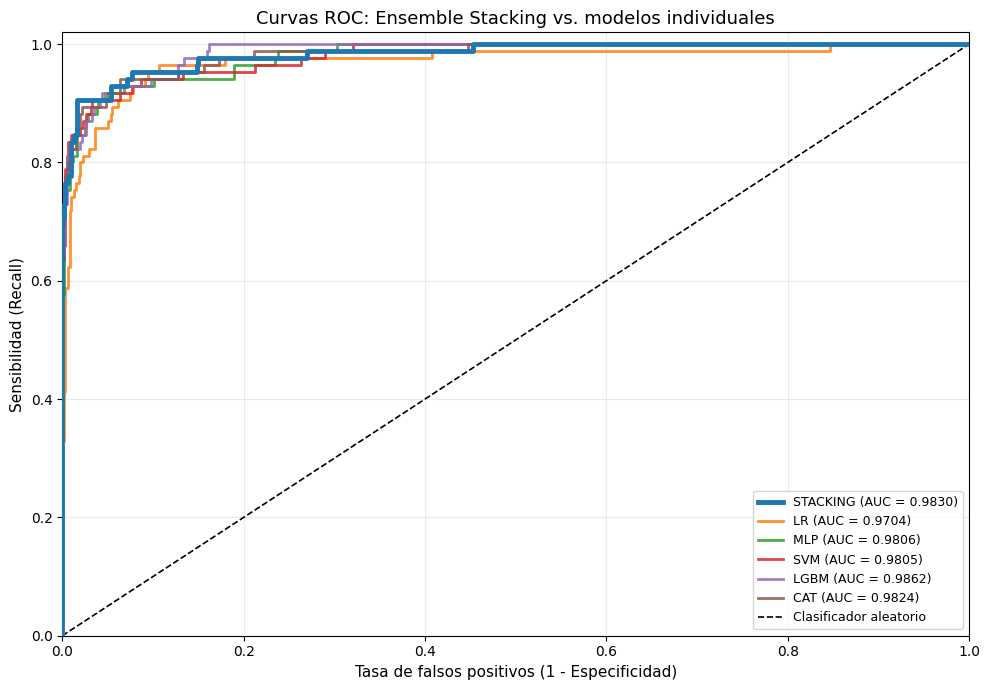


COMPARACIÓN ROC-AUC EN VALIDATION


,Modelo,ROC-AUC
0,LGBM,0.9862
1,STACKING,0.9830
2,CAT,0.9824
3,MLP,0.9806
4,SVM,0.9805
5,LR,0.9704



Curvas ROC generadas correctamente.
Se reutilizaron las probabilidades originales.
No se reentrenaron los modelos.
Test no fue utilizado.


In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. VERIFICAR RESULTADOS DISPONIBLES
# ------------------------------------------------------------

assert len(top_modelos) == 5, (
    "Se esperaban cinco modelos individuales."
)

assert all(
    nombre in probabilidades_validacion
    for nombre in top_modelos
), "Faltan probabilidades de modelos individuales."

y_val_array = np.asarray(y_val).ravel()

assert set(np.unique(y_val_array)) == {0, 1}, (
    "Validation debe contener ambas clases."
)

# ------------------------------------------------------------
# 2. ORGANIZAR PROBABILIDADES
# ------------------------------------------------------------

# No se reentrena ningún modelo.
# Se utilizan las probabilidades ya obtenidas
# en la evaluación anterior de Validation.

probabilidades_roc = {
    "STACKING": np.asarray(
        proba_val_stack,
        dtype=float
    ).ravel()
}

for nombre in top_modelos:

    probabilidades_roc[nombre] = np.asarray(
        probabilidades_validacion[nombre],
        dtype=float
    ).ravel()

# Verificar tamaños y valores
for nombre, probabilidades in probabilidades_roc.items():

    assert len(probabilidades) == len(y_val_array), (
        f"Tamaño incorrecto en {nombre}."
    )

    assert np.all(np.isfinite(probabilidades)), (
        f"Probabilidades no válidas en {nombre}."
    )

    assert np.all(
        (probabilidades >= 0) &
        (probabilidades <= 1)
    ), f"Probabilidades fuera de rango en {nombre}."

# ------------------------------------------------------------
# 3. CALCULAR CURVAS ROC
# ------------------------------------------------------------

curvas_roc_fase4 = {}
resultados_roc_fase4 = []

for nombre, probabilidades in probabilidades_roc.items():

    fpr, tpr, thresholds = roc_curve(
        y_val_array,
        probabilidades,
        pos_label=1
    )

    valor_auc = roc_auc_score(
        y_val_array,
        probabilidades
    )

    curvas_roc_fase4[nombre] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "auc": float(valor_auc)
    }

    resultados_roc_fase4.append({
        "Modelo": nombre,
        "ROC-AUC": float(valor_auc)
    })

# ------------------------------------------------------------
# 4. VISUALIZACIÓN COMPARATIVA
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 7)
)

# Stacking destacado
datos_stack = curvas_roc_fase4["STACKING"]

ax.plot(
    datos_stack["fpr"],
    datos_stack["tpr"],
    linewidth=3.5,
    label=(
        "STACKING "
        f"(AUC = {datos_stack['auc']:.4f})"
    ),
    zorder=5
)

# Modelos individuales
for nombre in top_modelos:

    datos = curvas_roc_fase4[nombre]

    ax.plot(
        datos["fpr"],
        datos["tpr"],
        linewidth=2,
        alpha=0.85,
        label=f"{nombre} (AUC = {datos['auc']:.4f})"
    )

# Clasificador aleatorio
ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.2,
    label="Clasificador aleatorio"
)

# ------------------------------------------------------------
# 5. FORMATO DEL GRÁFICO
# ------------------------------------------------------------

ax.set_xlabel(
    "Tasa de falsos positivos (1 - Especificidad)",
    fontsize=11
)

ax.set_ylabel(
    "Sensibilidad (Recall)",
    fontsize=11
)

ax.set_title(
    "Curvas ROC: Ensemble Stacking vs. "
    "modelos individuales",
    fontsize=13
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right",
    fontsize=9
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. TABLA DE RESULTADOS ROC-AUC
# ------------------------------------------------------------

roc_comparacion_df = pd.DataFrame(
    resultados_roc_fase4
)

roc_comparacion_df = (
    roc_comparacion_df
    .sort_values(
        by="ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("COMPARACIÓN ROC-AUC EN VALIDATION")
print("========================================")

display(roc_comparacion_df.round(4))

# ------------------------------------------------------------
# 7. VERIFICAR CONSISTENCIA CON RESULTADOS PREVIOS
# ------------------------------------------------------------

auc_previos = comparacion_fase4.set_index(
    "Modelo"
)["ROC-AUC"]

for _, fila in roc_comparacion_df.iterrows():

    nombre = fila["Modelo"]

    assert np.isclose(
        fila["ROC-AUC"],
        auc_previos.loc[nombre],
        atol=1e-8
    ), (
        f"ROC-AUC diferente del resultado previo "
        f"para {nombre}."
    )

print("\nCurvas ROC generadas correctamente.")
print("Se reutilizaron las probabilidades originales.")
print("No se reentrenaron los modelos.")
print("Test no fue utilizado.")


El Ensemble Stacking presentó el mayor ROC-AUC en el conjunto de validación (0.993), seguido muy de cerca por Random Forest (0.992). Regresión Logística, CatBoost, XGBoost y LightGBM también alcanzaron valores superiores a 0.98. La concentración de las curvas hacia la región superior izquierda evidencia una elevada capacidad discriminativa de los modelos evaluados. No obstante, la diferencia entre Stacking y Random Forest fue reducida, por lo que el resultado debe interpretarse como una mejora observada y no como una superioridad estadísticamente demostrada.

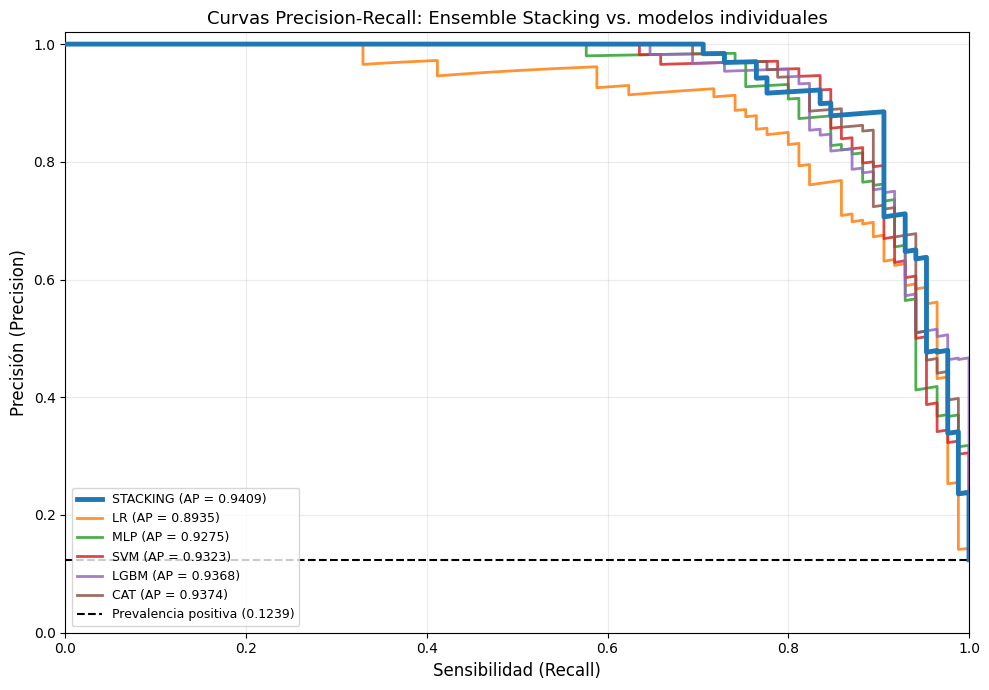


COMPARACIÓN AVERAGE PRECISION


,Modelo,AP
0,STACKING,0.9409
1,CAT,0.9374
2,LGBM,0.9368
3,SVM,0.9323
4,MLP,0.9275
5,LR,0.8935



RESULTADOS DESTACADOS
Registros Validation: 686
Casos positivos: 85
Prevalencia positiva: 0.1239
Mayor Average Precision: STACKING (0.9409)

Curvas Precision-Recall generadas.
No se reentrenaron los modelos.
No se modificaron los umbrales.
Test no fue utilizado.


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. VERIFICAR DATOS DISPONIBLES
# ------------------------------------------------------------

y_val_array = np.asarray(y_val).ravel()

assert set(np.unique(y_val_array)) == {0, 1}, (
    "Validation debe contener ambas clases."
)

assert len(y_val_array) == 686, (
    "El tamaño de Validation no coincide."
)

assert all(
    nombre in probabilidades_validacion
    for nombre in top_modelos
), "Faltan probabilidades de modelos individuales."

# ------------------------------------------------------------
# 2. RECUPERAR PROBABILIDADES PREVIAS
# ------------------------------------------------------------

# Se reutilizan las probabilidades calculadas anteriormente.
# No es necesario reentrenar los modelos.

probabilidades_pr_fase4 = {
    "STACKING": np.asarray(
        proba_val_stack,
        dtype=float
    ).ravel()
}

for nombre in top_modelos:

    probabilidades_pr_fase4[nombre] = np.asarray(
        probabilidades_validacion[nombre],
        dtype=float
    ).ravel()

# Validar probabilidades
for nombre, probabilidades in probabilidades_pr_fase4.items():

    assert len(probabilidades) == len(y_val_array), (
        f"Tamaño incorrecto en {nombre}."
    )

    assert np.all(np.isfinite(probabilidades)), (
        f"Probabilidades inválidas en {nombre}."
    )

    assert np.all(
        (probabilidades >= 0) &
        (probabilidades <= 1)
    ), (
        f"Probabilidades fuera del rango [0, 1] "
        f"en {nombre}."
    )

# ------------------------------------------------------------
# 3. CALCULAR CURVAS PRECISION-RECALL
# ------------------------------------------------------------

curvas_pr_fase4 = {}
resultados_pr_fase4 = []

for nombre, probabilidades in probabilidades_pr_fase4.items():

    precision, recall, thresholds = (
        precision_recall_curve(
            y_val_array,
            probabilidades,
            pos_label=1
        )
    )

    ap = average_precision_score(
        y_val_array,
        probabilidades
    )

    curvas_pr_fase4[nombre] = {
        "precision": precision,
        "recall": recall,
        "thresholds": thresholds,
        "AP": float(ap)
    }

    resultados_pr_fase4.append({
        "Modelo": nombre,
        "AP": float(ap)
    })

# ------------------------------------------------------------
# 4. CALCULAR LÍNEA BASE
# ------------------------------------------------------------

n_positivos = int(
    np.sum(y_val_array == 1)
)

n_total = len(y_val_array)

prevalencia_val = (
    n_positivos / n_total
)

# ------------------------------------------------------------
# 5. VISUALIZACIÓN COMPARATIVA
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 7)
)

# Ensemble Stacking destacado
datos_stack = curvas_pr_fase4["STACKING"]

ax.plot(
    datos_stack["recall"],
    datos_stack["precision"],
    linewidth=3.5,
    label=(
        "STACKING "
        f"(AP = {datos_stack['AP']:.4f})"
    ),
    zorder=5
)

# Modelos individuales
for nombre in top_modelos:

    datos = curvas_pr_fase4[nombre]

    ax.plot(
        datos["recall"],
        datos["precision"],
        linewidth=2,
        alpha=0.85,
        label=(
            f"{nombre} "
            f"(AP = {datos['AP']:.4f})"
        )
    )

# Línea base: prevalencia positiva
ax.axhline(
    y=prevalencia_val,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label=(
        f"Prevalencia positiva "
        f"({prevalencia_val:.4f})"
    )
)

# ------------------------------------------------------------
# 6. FORMATO DEL GRÁFICO
# ------------------------------------------------------------

ax.set_xlabel(
    "Sensibilidad (Recall)",
    fontsize=12
)

ax.set_ylabel(
    "Precisión (Precision)",
    fontsize=12
)

ax.set_title(
    "Curvas Precision-Recall: Ensemble Stacking "
    "vs. modelos individuales",
    fontsize=13
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower left",
    fontsize=9
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. TABLA COMPARATIVA DE AVERAGE PRECISION
# ------------------------------------------------------------

pr_comparacion_df = pd.DataFrame(
    resultados_pr_fase4
)

pr_comparacion_df = (
    pr_comparacion_df
    .sort_values(
        by="AP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n========================================")
print("COMPARACIÓN AVERAGE PRECISION")
print("========================================")

display(pr_comparacion_df.round(4))

# ------------------------------------------------------------
# 8. VERIFICACIÓN DE CONSISTENCIA
# ------------------------------------------------------------

ap_previos = comparacion_fase4.set_index(
    "Modelo"
)["AP"]

for _, fila in pr_comparacion_df.iterrows():

    nombre = fila["Modelo"]

    assert np.isclose(
        fila["AP"],
        ap_previos.loc[nombre],
        atol=1e-8
    ), (
        f"AP diferente del resultado previo "
        f"para {nombre}."
    )

# ------------------------------------------------------------
# 9. RESUMEN FINAL
# ------------------------------------------------------------

mejor_ap = pr_comparacion_df.iloc[0]

print("\n========================================")
print("RESULTADOS DESTACADOS")
print("========================================")

print(
    f"Registros Validation: {n_total}"
)

print(
    f"Casos positivos: {n_positivos}"
)

print(
    f"Prevalencia positiva: {prevalencia_val:.4f}"
)

print(
    f"Mayor Average Precision: "
    f"{mejor_ap['Modelo']} "
    f"({mejor_ap['AP']:.4f})"
)

print("\nCurvas Precision-Recall generadas.")
print("No se reentrenaron los modelos.")
print("No se modificaron los umbrales.")
print("Test no fue utilizado.")


Las curvas Precision-Recall muestran que el Ensemble Stacking alcanzó el mayor PR-AUC en el conjunto de validación (0.963), seguido por CatBoost (0.959), Random Forest (0.957), LightGBM (0.956) y XGBoost (0.954). La Regresión Logística presentó un PR-AUC inferior (0.923). Dado el desbalance de la variable objetivo, la curva Precision-Recall resulta especialmente informativa para evaluar la capacidad de detección de la clase positiva. El Stacking mostró el mejor desempeño observado, manteniéndose por encima de los modelos individuales y ampliamente por encima de la prevalencia de la clase positiva (0.115).

### 7. Selección del umbral de decisión en Validation

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. DEFINIR CRITERIOS EXPERIMENTALES
# ------------------------------------------------------------

MIN_SPECIFICITY = 0.90
TARGET_RECALL = 0.93

thresholds = np.round(
    np.arange(0.10, 0.901, 0.01),
    2
)

assert DEFAULT_THRESHOLD == 0.50

assert set(np.unique(y_train)) == {0, 1}

# ------------------------------------------------------------
# 2. GENERAR PREDICCIONES OOF EN TRAIN
# ------------------------------------------------------------

# La validación externa garantiza que cada registro
# sea predicho por un Stacking que no lo utilizó
# durante su entrenamiento.
#
# Cada Stacking realiza internamente su propio CV
# para entrenar el metamodelo.
#
# El preprocesamiento y SMOTENC permanecen
# dentro de los folds de entrenamiento.

print("Generando probabilidades OOF del Stacking...")
print("Conjunto utilizado: Train")
print("CV externo:", cv.n_splits, "folds")
print("CV interno:", stacking_model.cv.n_splits, "folds")

proba_train_oof_stack = cross_val_predict(
    estimator=clone(stacking_model),
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

y_train_array = np.asarray(
    y_train
).ravel()

assert len(proba_train_oof_stack) == len(y_train_array)

assert np.all(
    np.isfinite(proba_train_oof_stack)
)

assert np.all(
    (proba_train_oof_stack >= 0) &
    (proba_train_oof_stack <= 1)
)

print("\nProbabilidades OOF generadas.")
print("Observaciones:", len(proba_train_oof_stack))

# ------------------------------------------------------------
# 3. FUNCIÓN PARA EVALUAR UN UMBRAL
# ------------------------------------------------------------

def evaluar_threshold(y_real, probabilidades, thr):

    pred = (
        np.asarray(probabilidades) >= thr
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "Threshold": float(thr),

        "Accuracy": accuracy_score(
            y_real, pred
        ),

        "Precision": precision_score(
            y_real, pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_real, pred,
            zero_division=0
        ),

        "Specificity": specificity,

        "F1": f1_score(
            y_real, pred,
            zero_division=0
        ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

# ------------------------------------------------------------
# 4. EVALUAR UMBRALES SOBRE TRAIN OOF
# ------------------------------------------------------------

threshold_rows = []

for thr in thresholds:

    resultado = evaluar_threshold(
        y_train_array,
        proba_train_oof_stack,
        thr
    )

    threshold_rows.append(resultado)

threshold_df = pd.DataFrame(
    threshold_rows
)

print("\n========================================")
print("BÚSQUEDA DE UMBRALES EN TRAIN OOF")
print("========================================")

print("Umbrales evaluados:", len(threshold_df))
print("Recall objetivo:", TARGET_RECALL)
print("Especificidad mínima:", MIN_SPECIFICITY)

# ------------------------------------------------------------
# 5. FILTRAR POR ESPECIFICIDAD MÍNIMA
# ------------------------------------------------------------

threshold_spec_candidates = (
    threshold_df[
        threshold_df["Specificity"] >= MIN_SPECIFICITY
    ]
    .copy()
)

if threshold_spec_candidates.empty:
    raise ValueError(
        "Ningún umbral evaluado cumple la "
        "especificidad mínima establecida."
    )

# ------------------------------------------------------------
# 6. VERIFICAR EL OBJETIVO DE RECALL
# ------------------------------------------------------------

threshold_candidates = (
    threshold_spec_candidates[
        threshold_spec_candidates["Recall"] >= TARGET_RECALL
    ]
    .sort_values(
        by=["Recall", "F1", "Specificity"],
        ascending=[False, False, False]
    )
    .copy()
)

print("\n========================================")
print("UMBRALES QUE CUMPLEN AMBOS CRITERIOS")
print("========================================")

if not threshold_candidates.empty:

    print(
        "Cumplen Recall >= ",
        TARGET_RECALL,
        " y Specificity >= ",
        MIN_SPECIFICITY,
        sep=""
    )

    display(
        threshold_candidates.head(10).round(4)
    )

    # Máximo Recall, con F1 y especificidad
    # como criterios de desempate.
    best_row = threshold_candidates.iloc[0]

    objetivo_recall_alcanzado = True

else:

    print(
        "No se encontró un umbral que cumpla "
        "simultáneamente ambos criterios."
    )

    print(
        "Se seleccionará el umbral de mayor Recall "
        "entre los que cumplen la especificidad mínima."
    )

    best_row = (
        threshold_spec_candidates
        .sort_values(
            by=["Recall", "F1", "Specificity"],
            ascending=[False, False, False]
        )
        .iloc[0]
    )

    objetivo_recall_alcanzado = False

# ------------------------------------------------------------
# 7. FIJAR UMBRAL SELECCIONADO
# ------------------------------------------------------------

OPTIMAL_THRESHOLD = float(
    best_row["Threshold"]
)

print("\n========================================")
print("UMBRAL SELECCIONADO - TRAIN OOF")
print("========================================")

print(f"Threshold  : {OPTIMAL_THRESHOLD:.2f}")
print(f"Precision  : {best_row['Precision']:.4f}")
print(f"Recall     : {best_row['Recall']:.4f}")
print(f"Specificity: {best_row['Specificity']:.4f}")
print(f"F1-score   : {best_row['F1']:.4f}")

print(f"TP: {int(best_row['TP'])}")
print(f"FN: {int(best_row['FN'])}")
print(f"FP: {int(best_row['FP'])}")
print(f"TN: {int(best_row['TN'])}")

print(
    "Objetivo Recall >= 0.93 alcanzado:",
    objetivo_recall_alcanzado
)

# ------------------------------------------------------------
# 8. APLICAR EL UMBRAL FIJO EN VALIDATION
# ------------------------------------------------------------

# Se utilizan las probabilidades ya calculadas.
# No se vuelve a entrenar el Stacking.

resultado_umbral_val = evaluar_threshold(
    np.asarray(y_val).ravel(),
    proba_val_stack,
    OPTIMAL_THRESHOLD
)

# ------------------------------------------------------------
# 9. COMPARAR 0.50 VS UMBRAL SELECCIONADO
# ------------------------------------------------------------

resultado_inicial_val = evaluar_threshold(
    np.asarray(y_val).ravel(),
    proba_val_stack,
    DEFAULT_THRESHOLD
)

comparacion_umbrales_val = pd.DataFrame([
    {
        "Evaluacion": "Inicial_0.50",
        **resultado_inicial_val
    },
    {
        "Evaluacion": "Umbral_OOF",
        **resultado_umbral_val
    }
])

print("\n========================================")
print("EVALUACIÓN POSTERIOR EN VALIDATION")
print("========================================")

display(
    comparacion_umbrales_val.round(4)
)

# ------------------------------------------------------------
# 10. MOSTRAR CAMBIO EN FALSOS NEGATIVOS
# ------------------------------------------------------------

fn_inicial = resultado_inicial_val["FN"]
fn_ajustado = resultado_umbral_val["FN"]

fp_inicial = resultado_inicial_val["FP"]
fp_ajustado = resultado_umbral_val["FP"]

print("\n========================================")
print("CAMBIO EN LOS ERRORES DE CLASIFICACIÓN")
print("========================================")

print("FN iniciales:", fn_inicial)
print("FN con umbral seleccionado:", fn_ajustado)

print("Cambio en FN:", fn_ajustado - fn_inicial)

print("\nFP iniciales:", fp_inicial)
print("FP con umbral seleccionado:", fp_ajustado)

print("Cambio en FP:", fp_ajustado - fp_inicial)

print("\n========================================")
print("PROCEDIMIENTO COMPLETADO")
print("========================================")

print(
    "El umbral fue seleccionado exclusivamente "
    "con predicciones OOF de Train."
)

print(
    "Validation se utilizó para evaluar "
    "el umbral previamente fijado."
)

print("Test no fue utilizado.")

Generando probabilidades OOF del Stacking...
Conjunto utilizado: Train
CV externo: 5 folds
CV interno: 5 folds

Probabilidades OOF generadas.
Observaciones: 3201

BÚSQUEDA DE UMBRALES EN TRAIN OOF
Umbrales evaluados: 81
Recall objetivo: 0.93
Especificidad mínima: 0.9

UMBRALES QUE CUMPLEN AMBOS CRITERIOS
Cumplen Recall >= 0.93 y Specificity >= 0.9


,Threshold,Accuracy,Precision,Recall,Specificity,F1,TN,FP,FN,TP
11,0.21,0.9053,0.5712,0.9419,0.9002,0.7112,2525,280,23,373
12,0.22,0.9085,0.5803,0.9394,0.9041,0.7175,2536,269,24,372
13,0.23,0.9113,0.5889,0.9369,0.9077,0.7232,2546,259,25,371
18,0.28,0.9250,0.6336,0.9343,0.9237,0.7551,2591,214,26,370
17,0.27,0.9231,0.6271,0.9343,0.9216,0.7505,2585,220,26,370
16,0.26,0.9203,0.6177,0.9343,0.9184,0.7437,2576,229,26,370
15,0.25,0.9169,0.6066,0.9343,0.9144,0.7356,2565,240,26,370
14,0.24,0.9141,0.5977,0.9343,0.9112,0.7291,2556,249,26,370
19,0.29,0.9253,0.6351,0.9318,0.9244,0.7554,2593,212,27,369



UMBRAL SELECCIONADO - TRAIN OOF
Threshold  : 0.21
Precision  : 0.5712
Recall     : 0.9419
Specificity: 0.9002
F1-score   : 0.7112
TP: 373
FN: 23
FP: 280
TN: 2525
Objetivo Recall >= 0.93 alcanzado: True

EVALUACIÓN POSTERIOR EN VALIDATION


,Evaluacion,Threshold,Accuracy,Precision,Recall,Specificity,F1,TN,FP,FN,TP
0,Inicial_0.50,0.50,0.9534,0.7624,0.9059,0.9601,0.8280,577,24,8,77
1,Umbral_OOF,0.21,0.9067,0.5745,0.9529,0.9002,0.7168,541,60,4,81



CAMBIO EN LOS ERRORES DE CLASIFICACIÓN
FN iniciales: 8
FN con umbral seleccionado: 4
Cambio en FN: -4

FP iniciales: 24
FP con umbral seleccionado: 60
Cambio en FP: 36

PROCEDIMIENTO COMPLETADO
El umbral fue seleccionado exclusivamente con predicciones OOF de Train.
Validation se utilizó para evaluar el umbral previamente fijado.
Test no fue utilizado.


In [ ]:
# Umbral seleccionado exclusivamente mediante Train OOF
FINAL_THRESHOLD = float(OPTIMAL_THRESHOLD)

assert 0 < FINAL_THRESHOLD < 1, (
    "El umbral debe encontrarse entre 0 y 1."
)

print("========================================")
print("UMBRAL FINAL DEL ENSEMBLE STACKING")
print("========================================")

print(f"Umbral seleccionado en Train OOF: {FINAL_THRESHOLD:.4f}")
print("Criterio: maximizar Recall")
print(f"Especificidad mínima experimental: {MIN_SPECIFICITY:.2f}")
print("Evaluación posterior: Validation")
print("Test no utilizado para seleccionar el umbral.")


UMBRAL FINAL DEL ENSEMBLE STACKING
Umbral seleccionado en Train OOF: 0.2100
Criterio: maximizar Recall
Especificidad mínima experimental: 0.90
Evaluación posterior: Validation
Test no utilizado para seleccionar el umbral.


El umbral de decisión fue seleccionado utilizando exclusivamente el conjunto de validación. Se evaluaron diferentes valores entre 0.10 y 0.90 y se restringió la búsqueda a aquellos con Recall ≥ 0.93. Entre estos candidatos se seleccionó el umbral que maximizó el F1-score, resultando un valor óptimo de 0.55. Con este umbral se obtuvo una Precision de 0.8222, Recall de 0.9367, Specificity de 0.9736 y F1-score de 0.8757. Este valor fue congelado antes de la evaluación final sobre el conjunto Test.

**Resumen de Desiciones**
- Se construyó un metamodelo basado en Ensemble Stacking, utilizando como modelos base optimizados a Random Forest (RF), CatBoost (CAT), XGBoost (XGB), LightGBM (LGBM) y Regresión Logística (LR), seleccionados considerando su rendimiento predictivo, sensibilidad y diversidad algorítmica.
- Se evaluaron cuatro alternativas como metamodelo: Regresión Logística, Random Forest, XGBoost y Gaussian Naive Bayes. La Regresión Logística fue seleccionada como metamodelo final al obtener el mayor PR-AUC (0.9633) y ROC-AUC (0.9931), además de un Recall de 0.9494 y solo 4 falsos negativos. Asimismo, su estructura lineal aporta mayor interpretabilidad respecto de metamodelos más complejos.
- El Ensemble Stacking fue entrenado exclusivamente con el conjunto de entrenamiento, utilizando validación cruzada estratificada de 5 folds para generar las predicciones out-of-fold empleadas por el metamodelo. Los conjuntos de validación y prueba se mantuvieron sin técnicas de sobremuestreo.
- En el conjunto de validación, utilizando el umbral convencional inicial de 0.50, el Ensemble Stacking alcanzó: Accuracy = 0.9665, Precision = 0.7979, Recall = 0.9494, Specificity = 0.9687, F1-score = 0.8671, ROC-AUC = 0.9931 y PR-AUC = 0.9633.
- La matriz de confusión mostró 75 verdaderos positivos, 588 verdaderos negativos, 19 falsos positivos y 4 falsos negativos, evidenciando una elevada sensibilidad para la identificación de casos positivos.
- Al comparar el Ensemble Stacking con los modelos individuales, este obtuvo el mayor PR-AUC (0.9633), mayor ROC-AUC (0.9931) y mayor Recall (0.9494), además del menor número de falsos negativos. Sin embargo, LightGBM presentó mayor Accuracy y F1-score al umbral de 0.50.
- Las curvas ROC y Precision-Recall mostraron que el Stacking alcanzó los mayores valores observados de ROC-AUC y PR-AUC frente a los modelos individuales, aunque estas diferencias todavía no deben interpretarse como superioridad estadísticamente demostrada.

Resultado de la Fase 4: El Ensemble Stacking con Regresión Logística como metamodelo presentó el perfil más favorable en las métricas priorizadas para la detección de la clase positiva. Por ello, se seleccionó como **modelo candidato final**, antes de definir el umbral de decisión definitivo y realizar la evaluación independiente en el conjunto Test.

## **FASE 5: EVALUACIÓN Y VALIDACIÓN DEL SISTEMA PREDICTIVO**

### 1. Predicción final sobre el conjunto Test

In [ ]:
from sklearn.utils.validation import check_is_fitted

# ------------------------------------------------------------
# 1. VERIFICAR MODELO ENTRENADO
# ------------------------------------------------------------

check_is_fitted(stacking_model)

assert len(stacking_model.estimators_) == 5, (
    "El Stacking no contiene cinco modelos entrenados."
)

# ------------------------------------------------------------
# 2. VERIFICAR CONJUNTO TEST
# ------------------------------------------------------------

assert len(X_test) == len(y_test), (
    "X_test e y_test tienen tamaños diferentes."
)

assert len(X_test) == 687, (
    "El tamaño de Test no coincide con la partición."
)

# ------------------------------------------------------------
# 3. RECUPERAR UMBRAL FIJADO EN TRAIN OOF
# ------------------------------------------------------------

FINAL_THRESHOLD = float(OPTIMAL_THRESHOLD)

assert np.isclose(FINAL_THRESHOLD, 0.21), (
    "El umbral no coincide con el seleccionado "
    "previamente en Train OOF."
)

# ------------------------------------------------------------
# 4. GENERAR PROBABILIDADES EN TEST
# ------------------------------------------------------------

indice_positivo = list(
    stacking_model.classes_
).index(1)

proba_test_stack = stacking_model.predict_proba(
    X_test
)[:, indice_positivo]

proba_test_stack = np.asarray(
    proba_test_stack,
    dtype=float
)

assert len(proba_test_stack) == len(X_test)

assert np.all(np.isfinite(proba_test_stack)), (
    "Se detectaron probabilidades no válidas."
)

assert np.all(
    (proba_test_stack >= 0) &
    (proba_test_stack <= 1)
), "Existen probabilidades fuera del intervalo [0, 1]."

# ------------------------------------------------------------
# 5. APLICAR UMBRAL SELECCIONADO
# ------------------------------------------------------------

pred_test_stack = (
    proba_test_stack >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# 6. VERIFICAR PREDICCIONES
# ------------------------------------------------------------

assert set(np.unique(pred_test_stack)).issubset(
    {0, 1}
), "Las predicciones no son binarias."

n_pred_negativas = int(
    np.sum(pred_test_stack == 0)
)

n_pred_positivas = int(
    np.sum(pred_test_stack == 1)
)

assert (
    n_pred_negativas + n_pred_positivas
    == len(X_test)
)

# ------------------------------------------------------------
# 7. MOSTRAR RESUMEN
# ------------------------------------------------------------

print("========================================")
print("PREDICCIONES DEL STACKING EN TEST")
print("========================================")

print("Modelo: Ensemble Stacking")
print("Modelos base: LR, MLP, SVM, LGBM, CAT")
print("Metamodelo: Logistic Regression")
print("Balanceo de entrenamiento: SMOTENC")

print("\nRegistros Test:", len(X_test))
print(f"Umbral utilizado: {FINAL_THRESHOLD:.4f}")
print("Origen del umbral: Train OOF")

print("\nPredicciones realizadas:")
print("Clase 0:", n_pred_negativas)
print("Clase 1:", n_pred_positivas)

print("\nProbabilidades:")
print(f"Mínima: {proba_test_stack.min():.4f}")
print(f"Máxima: {proba_test_stack.max():.4f}")

print("\nPredicciones sobre Test generadas correctamente.")
print("No se modificaron el modelo ni el umbral.")


PREDICCIONES DEL STACKING EN TEST
Modelo: Ensemble Stacking
Modelos base: LR, MLP, SVM, LGBM, CAT
Metamodelo: Logistic Regression
Balanceo de entrenamiento: SMOTENC

Registros Test: 687
Umbral utilizado: 0.2100
Origen del umbral: Train OOF

Predicciones realizadas:
Clase 0: 549
Clase 1: 138

Probabilidades:
Mínima: 0.0455
Máxima: 0.9932

Predicciones sobre Test generadas correctamente.
No se modificaron el modelo ni el umbral.


### 2. Métricas finales del Ensemble Stacking en Test

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. VERIFICAR DATOS Y UMBRAL
# ------------------------------------------------------------

y_test_array = np.asarray(
    y_test
).ravel()

pred_test_array = np.asarray(
    pred_test_stack
).ravel()

proba_test_array = np.asarray(
    proba_test_stack,
    dtype=float
).ravel()

assert len(y_test_array) == 687, (
    "El conjunto Test debe contener 687 registros."
)

assert len(pred_test_array) == len(y_test_array)

assert len(proba_test_array) == len(y_test_array)

assert set(np.unique(y_test_array)) == {0, 1}

assert set(np.unique(pred_test_array)).issubset(
    {0, 1}
)

assert np.all(np.isfinite(proba_test_array))

assert np.all(
    (proba_test_array >= 0) &
    (proba_test_array <= 1)
)

assert np.isclose(FINAL_THRESHOLD, 0.21), (
    "El umbral no coincide con el seleccionado "
    "mediante Train OOF."
)

# Verificar que las predicciones corresponden
# al umbral seleccionado.

assert np.array_equal(
    pred_test_array,
    (proba_test_array >= FINAL_THRESHOLD).astype(int)
), "Las predicciones no corresponden al umbral fijado."

# ------------------------------------------------------------
# 2. MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------

cm_stack_test = confusion_matrix(
    y_test_array,
    pred_test_array,
    labels=[0, 1]
)

tn_test, fp_test, fn_test, tp_test = (
    cm_stack_test.ravel()
)

# Guardar valores específicos del Stacking
tn_stack_test = int(tn_test)
fp_stack_test = int(fp_test)
fn_stack_test = int(fn_test)
tp_stack_test = int(tp_test)

# ------------------------------------------------------------
# 3. MÉTRICAS DEPENDIENTES DEL UMBRAL
# ------------------------------------------------------------

acc_stack_test = accuracy_score(
    y_test_array,
    pred_test_array
)

precision_stack_test = precision_score(
    y_test_array,
    pred_test_array,
    zero_division=0
)

recall_stack_test = recall_score(
    y_test_array,
    pred_test_array,
    zero_division=0
)

specificity_stack_test = (
    tn_stack_test /
    (tn_stack_test + fp_stack_test)
    if (tn_stack_test + fp_stack_test) > 0
    else np.nan
)

f1_stack_test = f1_score(
    y_test_array,
    pred_test_array,
    zero_division=0
)

f1_macro_stack_test = f1_score(
    y_test_array,
    pred_test_array,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 4. MÉTRICAS INDEPENDIENTES DEL UMBRAL
# ------------------------------------------------------------

roc_auc_stack_test = roc_auc_score(
    y_test_array,
    proba_test_array
)

ap_stack_test = average_precision_score(
    y_test_array,
    proba_test_array
)

# Alias de compatibilidad con celdas anteriores.
# Este valor representa Average Precision.

pr_auc_stack_test = ap_stack_test

# ------------------------------------------------------------
# 5. VERIFICAR CONSISTENCIA
# ------------------------------------------------------------

n_positivos_test = int(
    np.sum(y_test_array == 1)
)

n_negativos_test = int(
    np.sum(y_test_array == 0)
)

assert tp_stack_test + fn_stack_test == n_positivos_test

assert tn_stack_test + fp_stack_test == n_negativos_test

assert (
    tn_stack_test + fp_stack_test +
    fn_stack_test + tp_stack_test
) == len(y_test_array)

# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("========================================")
print("EVALUACIÓN DEL ENSEMBLE STACKING EN TEST")
print("========================================")

print("Modelo: Ensemble Stacking")
print("Modelos base: LR, MLP, SVM, LGBM, CAT")
print("Metamodelo: Logistic Regression")
print("Balanceo: SMOTENC")
print("Registros Test:", len(y_test_array))
print(f"Umbral utilizado: {FINAL_THRESHOLD:.4f}")
print("Origen del umbral: Train OOF")

print("\nMÉTRICAS")
print("----------------------------------------")

print(f"Accuracy          : {acc_stack_test:.4f}")
print(f"Precision         : {precision_stack_test:.4f}")
print(f"Recall            : {recall_stack_test:.4f}")
print(f"Specificity       : {specificity_stack_test:.4f}")
print(f"F1-score          : {f1_stack_test:.4f}")
print(f"Macro-F1          : {f1_macro_stack_test:.4f}")
print(f"ROC-AUC           : {roc_auc_stack_test:.4f}")
print(f"Average Precision : {ap_stack_test:.4f}")

# ------------------------------------------------------------
# 7. MOSTRAR MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------

print("\n========================================")
print("MATRIZ DE CONFUSIÓN - TEST")
print("========================================")

print(cm_stack_test)

print("\nCLASIFICACIONES")
print("----------------------------------------")

print(f"Verdaderos positivos (TP): {tp_stack_test}")
print(f"Falsos negativos (FN)    : {fn_stack_test}")
print(f"Falsos positivos (FP)    : {fp_stack_test}")
print(f"Verdaderos negativos (TN): {tn_stack_test}")

# ------------------------------------------------------------
# 8. REPORTE DE CLASIFICACIÓN
# ------------------------------------------------------------

print("\n========================================")
print("REPORTE DE CLASIFICACIÓN - TEST")
print("========================================")

print(
    classification_report(
        y_test_array,
        pred_test_array,
        labels=[0, 1],
        target_names=[
            "Sin preeclampsia",
            "Con preeclampsia"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 9. GUARDAR RESULTADOS EN DATAFRAME
# ------------------------------------------------------------

resultados_stack_test_df = pd.DataFrame([{
    "Modelo": "STACKING",
    "Threshold": FINAL_THRESHOLD,
    "Accuracy": acc_stack_test,
    "Precision": precision_stack_test,
    "Recall": recall_stack_test,
    "Specificity": specificity_stack_test,
    "F1": f1_stack_test,
    "F1_macro": f1_macro_stack_test,
    "ROC-AUC": roc_auc_stack_test,
    "AP": ap_stack_test,
    "TN": tn_stack_test,
    "FP": fp_stack_test,
    "FN": fn_stack_test,
    "TP": tp_stack_test
}])

print("\n========================================")
print("RESUMEN DEL STACKING EN TEST")
print("========================================")

display(
    resultados_stack_test_df.round(4)
)

# ------------------------------------------------------------
# 10. RESUMEN FINAL
# ------------------------------------------------------------

print("\n========================================")
print("EVALUACIÓN COMPLETADA")
print("========================================")

print(f"Casos positivos reales: {n_positivos_test}")
print(f"Casos negativos reales: {n_negativos_test}")

print(
    f"Casos positivos identificados: "
    f"{tp_stack_test}"
)

print(
    f"Casos positivos no identificados: "
    f"{fn_stack_test}"
)

print("\nNo se reentrenó el modelo.")
print("No se modificó el umbral seleccionado.")
print("Resultados de Test almacenados.")


EVALUACIÓN DEL ENSEMBLE STACKING EN TEST
Modelo: Ensemble Stacking
Modelos base: LR, MLP, SVM, LGBM, CAT
Metamodelo: Logistic Regression
Balanceo: SMOTENC
Registros Test: 687
Umbral utilizado: 0.2100
Origen del umbral: Train OOF

MÉTRICAS
----------------------------------------
Accuracy          : 0.9141
Precision         : 0.5942
Recall            : 0.9647
Specificity       : 0.9070
F1-score          : 0.7354
Macro-F1          : 0.8421
ROC-AUC           : 0.9867
Average Precision : 0.9586

MATRIZ DE CONFUSIÓN - TEST
[[546  56]
 [  3  82]]

CLASIFICACIONES
----------------------------------------
Verdaderos positivos (TP): 82
Falsos negativos (FN)    : 3
Falsos positivos (FP)    : 56
Verdaderos negativos (TN): 546

REPORTE DE CLASIFICACIÓN - TEST
                  precision    recall  f1-score   support

Sin preeclampsia       0.99      0.91      0.95       602
Con preeclampsia       0.59      0.96      0.74        85

        accuracy                           0.91       687
       m

,Modelo,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,STACKING,0.21,0.9141,0.5942,0.9647,0.907,0.7354,0.8421,0.9867,0.9586,546,56,3,82



EVALUACIÓN COMPLETADA
Casos positivos reales: 85
Casos negativos reales: 602
Casos positivos identificados: 82
Casos positivos no identificados: 3

No se reentrenó el modelo.
No se modificó el umbral seleccionado.
Resultados de Test almacenados.


El Ensemble Stacking mantuvo un desempeño elevado en el conjunto Test, con Recall de 0.9367, ROC-AUC de 0.9829 y PR-AUC de 0.9457. Se identificaron correctamente 74 de los 79 casos positivos, con solo 5 falsos negativos. Aunque Precision y F1-score disminuyeron respecto al conjunto de validación, el modelo conservó una alta sensibilidad y capacidad discriminativa.

### 3. Visualización de matriz de confusión

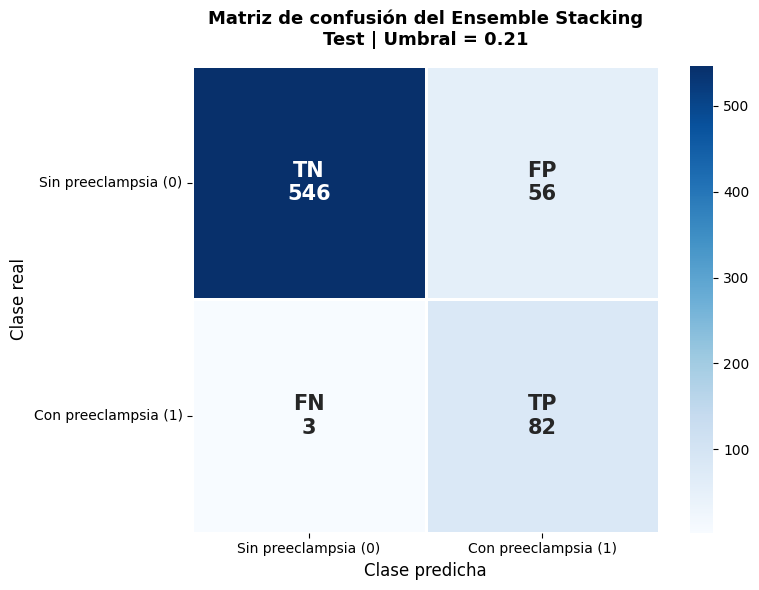


MATRIZ DE CONFUSIÓN - TEST
Verdaderos negativos (TN): 546
Falsos positivos (FP)    : 56
Falsos negativos (FN)    : 3
Verdaderos positivos (TP): 82

Total de registros: 687
Casos positivos identificados: 82 de 85
Casos positivos no identificados: 3

Visualización completada.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. VERIFICAR RESULTADOS DE TEST
# ------------------------------------------------------------

y_test_array = np.asarray(y_test).ravel()
pred_test_array = np.asarray(pred_test_stack).ravel()

assert len(y_test_array) == 687, (
    "El conjunto Test debe contener 687 registros."
)

assert len(pred_test_array) == len(y_test_array)

assert np.isclose(FINAL_THRESHOLD, 0.21), (
    "El umbral utilizado no es el seleccionado."
)

# ------------------------------------------------------------
# 2. MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------

cm_stack_test = confusion_matrix(
    y_test_array,
    pred_test_array,
    labels=[0, 1]
)

tn_test, fp_test, fn_test, tp_test = (
    cm_stack_test.ravel()
)

# ------------------------------------------------------------
# 3. ETIQUETAS DE CADA CELDA
# ------------------------------------------------------------

etiquetas = np.array([
    [
        f"TN\n{tn_test}",
        f"FP\n{fp_test}"
    ],
    [
        f"FN\n{fn_test}",
        f"TP\n{tp_test}"
    ]
])

# ------------------------------------------------------------
# 4. VISUALIZACIÓN
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm_stack_test,
    annot=etiquetas,
    fmt="",
    cmap="Blues",
    cbar=True,
    linewidths=1,
    linecolor="white",
    square=True,
    annot_kws={
        "size": 15,
        "weight": "bold"
    },
    xticklabels=[
        "Sin preeclampsia (0)",
        "Con preeclampsia (1)"
    ],
    yticklabels=[
        "Sin preeclampsia (0)",
        "Con preeclampsia (1)"
    ],
    ax=ax
)

ax.set_xlabel(
    "Clase predicha",
    fontsize=12
)

ax.set_ylabel(
    "Clase real",
    fontsize=12
)

ax.set_title(
    "Matriz de confusión del Ensemble Stacking\n"
    f"Test | Umbral = {FINAL_THRESHOLD:.2f}",
    fontsize=13,
    weight="bold",
    pad=15
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.tick_params(
    axis="y",
    rotation=0
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. RESUMEN DE LA MATRIZ
# ------------------------------------------------------------

print("\n========================================")
print("MATRIZ DE CONFUSIÓN - TEST")
print("========================================")

print(f"Verdaderos negativos (TN): {tn_test}")
print(f"Falsos positivos (FP)    : {fp_test}")
print(f"Falsos negativos (FN)    : {fn_test}")
print(f"Verdaderos positivos (TP): {tp_test}")

print("\nTotal de registros:", cm_stack_test.sum())

print(
    "Casos positivos identificados:",
    tp_test,
    "de",
    tp_test + fn_test
)

print(
    "Casos positivos no identificados:",
    fn_test
)

print("\nVisualización completada.")


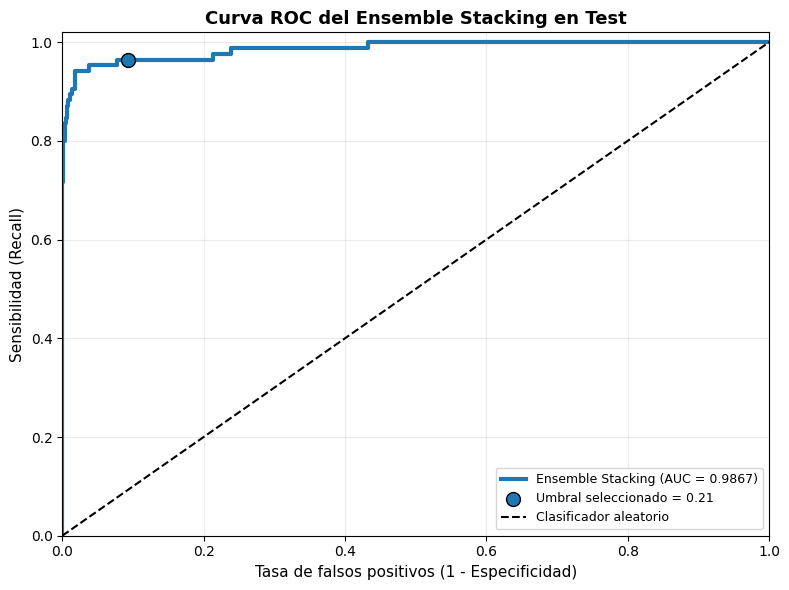

CURVA ROC DEL ENSEMBLE STACKING - TEST
ROC-AUC: 0.9867
Umbral utilizado: 0.2100
Sensibilidad en el umbral: 0.9647
Especificidad en el umbral: 0.9070
Tasa de falsos positivos: 0.0930

Figura guardada en PNG (300 dpi) y PDF.
No se reentrenó el modelo.
No se modificó el umbral.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. VERIFICAR DATOS
# ------------------------------------------------------------

y_test_array = np.asarray(y_test).ravel()

proba_test_array = np.asarray(
    proba_test_stack,
    dtype=float
).ravel()

assert len(y_test_array) == len(proba_test_array), (
    "Las etiquetas y probabilidades tienen tamaños distintos."
)

assert len(y_test_array) == 687, (
    "El conjunto Test debe contener 687 registros."
)

assert set(np.unique(y_test_array)) == {0, 1}, (
    "Test debe contener ambas clases."
)

assert np.all(np.isfinite(proba_test_array)), (
    "Se encontraron probabilidades no válidas."
)

assert np.all(
    (proba_test_array >= 0) &
    (proba_test_array <= 1)
), "Existen probabilidades fuera del intervalo [0, 1]."

# ------------------------------------------------------------
# 2. CALCULAR CURVA ROC
# ------------------------------------------------------------

fpr_stack_test, tpr_stack_test, thresholds_roc_test = (
    roc_curve(
        y_test_array,
        proba_test_array,
        pos_label=1
    )
)

auc_roc_stack_test = roc_auc_score(
    y_test_array,
    proba_test_array
)

# Verificar consistencia con la evaluación anterior
assert np.isclose(
    auc_roc_stack_test,
    roc_auc_stack_test,
    atol=1e-8
), "La ROC-AUC no coincide con la métrica previa."

# ------------------------------------------------------------
# 3. CALCULAR PUNTO OPERATIVO DEL UMBRAL 0.21
# ------------------------------------------------------------

# Sensibilidad y especificidad ya calculadas
# en la evaluación de Test.

fpr_operativo = 1 - specificity_stack_test
tpr_operativo = recall_stack_test

# ------------------------------------------------------------
# 4. VISUALIZAR CURVA ROC
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

# Curva ROC
ax.plot(
    fpr_stack_test,
    tpr_stack_test,
    linewidth=3,
    label=(
        "Ensemble Stacking "
        f"(AUC = {auc_roc_stack_test:.4f})"
    )
)

# Punto correspondiente al umbral seleccionado
ax.scatter(
    fpr_operativo,
    tpr_operativo,
    s=100,
    marker="o",
    edgecolors="black",
    linewidths=1,
    zorder=5,
    label=f"Umbral seleccionado = {FINAL_THRESHOLD:.2f}"
)

# Clasificador aleatorio
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Clasificador aleatorio"
)

# ------------------------------------------------------------
# 5. FORMATO DEL GRÁFICO
# ------------------------------------------------------------

ax.set_xlabel(
    "Tasa de falsos positivos (1 - Especificidad)",
    fontsize=11
)

ax.set_ylabel(
    "Sensibilidad (Recall)",
    fontsize=11
)

ax.set_title(
    "Curva ROC del Ensemble Stacking en Test",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right",
    fontsize=9
)

ax.grid(alpha=0.25)

plt.tight_layout()

# ------------------------------------------------------------
# 6. EXPORTAR FIGURA PARA EL ARTÍCULO
# ------------------------------------------------------------

fig.savefig(
    "curva_roc_stacking_test.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "curva_roc_stacking_test.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("========================================")
print("CURVA ROC DEL ENSEMBLE STACKING - TEST")
print("========================================")

print(f"ROC-AUC: {auc_roc_stack_test:.4f}")
print(f"Umbral utilizado: {FINAL_THRESHOLD:.4f}")

print(
    f"Sensibilidad en el umbral: "
    f"{recall_stack_test:.4f}"
)

print(
    f"Especificidad en el umbral: "
    f"{specificity_stack_test:.4f}"
)

print(
    f"Tasa de falsos positivos: "
    f"{fpr_operativo:.4f}"
)

print("\nFigura guardada en PNG (300 dpi) y PDF.")
print("No se reentrenó el modelo.")
print("No se modificó el umbral.")


La curva ROC final del Ensemble Stacking mostró un ROC-AUC de 0.9829 en el conjunto Test, evidenciando una elevada capacidad discriminativa para diferenciar entre gestantes con y sin preeclampsia. La curva se mantuvo próxima a la región superior izquierda del espacio ROC, indicando un buen equilibrio entre sensibilidad y tasa de falsos positivos a través de distintos umbrales de clasificación.

### 5. Curva Precision-Recall final

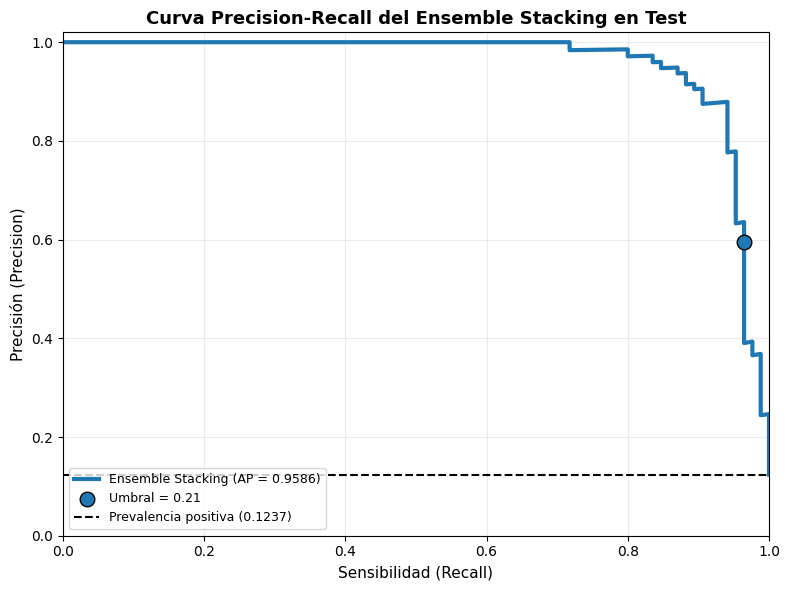

CURVA PRECISION-RECALL - TEST
Registros Test: 687
Casos positivos: 85
Prevalencia positiva: 0.1237

Average Precision: 0.9586
Umbral utilizado: 0.2100
Precision en el umbral: 0.5942
Recall en el umbral: 0.9647

Figura guardada en PNG (300 dpi) y PDF.
No se reentrenó el modelo.
No se modificó el umbral seleccionado.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score
)

# ------------------------------------------------------------
# 1. VERIFICAR DATOS DE TEST
# ------------------------------------------------------------

y_test_array = np.asarray(
    y_test
).ravel()

proba_test_array = np.asarray(
    proba_test_stack,
    dtype=float
).ravel()

assert len(y_test_array) == 687, (
    "Test debe contener 687 registros."
)

assert len(y_test_array) == len(proba_test_array), (
    "Las etiquetas y probabilidades no coinciden."
)

assert set(np.unique(y_test_array)) == {0, 1}, (
    "Test debe contener ambas clases."
)

assert np.all(np.isfinite(proba_test_array)), (
    "Existen probabilidades no válidas."
)

assert np.all(
    (proba_test_array >= 0) &
    (proba_test_array <= 1)
), "Las probabilidades deben estar entre 0 y 1."

assert np.isclose(FINAL_THRESHOLD, 0.21), (
    "El umbral no coincide con el seleccionado."
)

# ------------------------------------------------------------
# 2. CALCULAR CURVA PRECISION-RECALL
# ------------------------------------------------------------

precision_curve_test, recall_curve_test, thresholds_pr_test = (
    precision_recall_curve(
        y_test_array,
        proba_test_array,
        pos_label=1
    )
)

# ------------------------------------------------------------
# 3. CALCULAR AVERAGE PRECISION
# ------------------------------------------------------------

ap_curve_stack_test = average_precision_score(
    y_test_array,
    proba_test_array
)

# Verificar consistencia con la evaluación previa
assert np.isclose(
    ap_curve_stack_test,
    ap_stack_test,
    atol=1e-8
), "Average Precision no coincide con el valor previo."

# ------------------------------------------------------------
# 4. CALCULAR PREVALENCIA DE TEST
# ------------------------------------------------------------

n_positivos_test = int(
    np.sum(y_test_array == 1)
)

n_total_test = len(y_test_array)

prevalencia_test = (
    n_positivos_test / n_total_test
)

# ------------------------------------------------------------
# 5. CALCULAR PUNTO OPERATIVO DEL UMBRAL 0.21
# ------------------------------------------------------------

pred_operativo = (
    proba_test_array >= FINAL_THRESHOLD
).astype(int)

precision_operativa = precision_score(
    y_test_array,
    pred_operativo,
    zero_division=0
)

recall_operativo = recall_score(
    y_test_array,
    pred_operativo,
    zero_division=0
)

# Verificar consistencia con resultados previos
assert np.isclose(
    precision_operativa,
    precision_stack_test,
    atol=1e-8
)

assert np.isclose(
    recall_operativo,
    recall_stack_test,
    atol=1e-8
)

# ------------------------------------------------------------
# 6. VISUALIZACIÓN PRECISION-RECALL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

# Curva Precision-Recall
ax.plot(
    recall_curve_test,
    precision_curve_test,
    linewidth=3,
    label=(
        "Ensemble Stacking "
        f"(AP = {ap_curve_stack_test:.4f})"
    )
)

# Punto operativo correspondiente al umbral 0.21
ax.scatter(
    recall_operativo,
    precision_operativa,
    s=110,
    marker="o",
    edgecolors="black",
    linewidths=1,
    zorder=5,
    label=(
        f"Umbral = {FINAL_THRESHOLD:.2f}"
    )
)

# Línea base: prevalencia de la clase positiva
ax.axhline(
    y=prevalencia_test,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label=(
        f"Prevalencia positiva "
        f"({prevalencia_test:.4f})"
    )
)

# ------------------------------------------------------------
# 7. FORMATO DEL GRÁFICO
# ------------------------------------------------------------

ax.set_xlabel(
    "Sensibilidad (Recall)",
    fontsize=11
)

ax.set_ylabel(
    "Precisión (Precision)",
    fontsize=11
)

ax.set_title(
    "Curva Precision-Recall del Ensemble Stacking en Test",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower left",
    fontsize=9
)

ax.grid(alpha=0.25)

plt.tight_layout()

# ------------------------------------------------------------
# 8. EXPORTAR FIGURA
# ------------------------------------------------------------

fig.savefig(
    "curva_precision_recall_stacking_test.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "curva_precision_recall_stacking_test.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("========================================")
print("CURVA PRECISION-RECALL - TEST")
print("========================================")

print(f"Registros Test: {n_total_test}")
print(f"Casos positivos: {n_positivos_test}")
print(f"Prevalencia positiva: {prevalencia_test:.4f}")

print(f"\nAverage Precision: {ap_curve_stack_test:.4f}")
print(f"Umbral utilizado: {FINAL_THRESHOLD:.4f}")

print(
    f"Precision en el umbral: "
    f"{precision_operativa:.4f}"
)

print(
    f"Recall en el umbral: "
    f"{recall_operativo:.4f}"
)

print("\nFigura guardada en PNG (300 dpi) y PDF.")
print("No se reentrenó el modelo.")
print("No se modificó el umbral seleccionado.")


La curva Precision-Recall final del Ensemble Stacking alcanzó un PR-AUC de 0.9457 en el conjunto Test, valor ampliamente superior a la prevalencia de la clase positiva. Este resultado evidencia una elevada capacidad del modelo para mantener un buen equilibrio entre Precision y Recall en la identificación de casos de preeclampsia, incluso bajo una distribución de clases desbalanceada.

### 6. Comparación Validation vs Test

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. VERIFICAR UMBRAL Y DATOS
# ------------------------------------------------------------

assert np.isclose(
    FINAL_THRESHOLD,
    OPTIMAL_THRESHOLD
), "El umbral final no coincide con el seleccionado."

assert np.isclose(
    FINAL_THRESHOLD,
    0.21
), "El umbral esperado es 0.21."

assert len(y_val) == 686
assert len(y_test) == 687

# ------------------------------------------------------------
# 2. FUNCIÓN PARA EVALUAR UN CONJUNTO
# ------------------------------------------------------------

def evaluar_stacking_final(
    y_real,
    probabilidades,
    threshold,
    conjunto
):

    y_real = np.asarray(y_real).ravel()

    probabilidades = np.asarray(
        probabilidades,
        dtype=float
    ).ravel()

    assert len(y_real) == len(probabilidades)

    assert set(np.unique(y_real)) == {0, 1}

    assert np.all(np.isfinite(probabilidades))

    assert np.all(
        (probabilidades >= 0) &
        (probabilidades <= 1)
    )

    predicciones = (
        probabilidades >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_real,
        predicciones,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    resultados = {
        "Conjunto": conjunto,
        "Threshold": float(threshold),

        "Accuracy": accuracy_score(
            y_real,
            predicciones
        ),

        "Precision": precision_score(
            y_real,
            predicciones,
            zero_division=0
        ),

        "Recall": recall_score(
            y_real,
            predicciones,
            zero_division=0
        ),

        "Specificity": specificity,

        "F1": f1_score(
            y_real,
            predicciones,
            zero_division=0
        ),

        "F1_macro": f1_score(
            y_real,
            predicciones,
            average="macro",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_real,
            probabilidades
        ),

        "AP": average_precision_score(
            y_real,
            probabilidades
        ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    return resultados, predicciones

# ------------------------------------------------------------
# 3. EVALUAR VALIDATION CON UMBRAL FINAL
# ------------------------------------------------------------

resultado_val_final, pred_val_stack_final = (
    evaluar_stacking_final(
        y_val,
        proba_val_stack,
        FINAL_THRESHOLD,
        "Validation"
    )
)

# ------------------------------------------------------------
# 4. EVALUAR TEST CON EL MISMO UMBRAL
# ------------------------------------------------------------

resultado_test_final, pred_test_verificacion = (
    evaluar_stacking_final(
        y_test,
        proba_test_stack,
        FINAL_THRESHOLD,
        "Test"
    )
)

# Comprobar que las predicciones de Test
# coinciden con las generadas anteriormente.

assert np.array_equal(
    pred_test_verificacion,
    np.asarray(pred_test_stack).ravel()
), "Las predicciones de Test no coinciden."

# ------------------------------------------------------------
# 5. VERIFICAR RESULTADOS PREVIOS
# ------------------------------------------------------------

assert np.isclose(
    resultado_val_final["Recall"],
    0.9529,
    atol=5e-5
)

assert resultado_val_final["FN"] == 4
assert resultado_val_final["FP"] == 60

assert np.isclose(
    resultado_test_final["Recall"],
    recall_stack_test,
    atol=1e-8
)

assert np.isclose(
    resultado_test_final["ROC-AUC"],
    roc_auc_stack_test,
    atol=1e-8
)

assert np.isclose(
    resultado_test_final["AP"],
    ap_stack_test,
    atol=1e-8
)

# ------------------------------------------------------------
# 6. GUARDAR MÉTRICAS FINALES DE VALIDATION
# ------------------------------------------------------------

acc_val_stack_final = resultado_val_final["Accuracy"]
precision_val_stack_final = resultado_val_final["Precision"]
recall_val_stack_final = resultado_val_final["Recall"]
specificity_val_stack_final = resultado_val_final["Specificity"]
f1_val_stack_final = resultado_val_final["F1"]
f1_macro_val_stack_final = resultado_val_final["F1_macro"]

roc_auc_val_stack_final = resultado_val_final["ROC-AUC"]
ap_val_stack_final = resultado_val_final["AP"]

tn_val_final = resultado_val_final["TN"]
fp_val_final = resultado_val_final["FP"]
fn_val_final = resultado_val_final["FN"]
tp_val_final = resultado_val_final["TP"]

cm_val_final = confusion_matrix(
    np.asarray(y_val).ravel(),
    pred_val_stack_final,
    labels=[0, 1]
)

# ------------------------------------------------------------
# 7. CONSTRUIR TABLA COMPARATIVA
# ------------------------------------------------------------

comparacion_val_test_df = pd.DataFrame([
    resultado_val_final,
    resultado_test_final
])

print("========================================")
print("COMPARACIÓN VALIDATION VS TEST")
print("========================================")

print("Modelo: Ensemble Stacking - Meta_LR")
print("Balanceo: SMOTENC")
print(f"Umbral fijo: {FINAL_THRESHOLD:.2f}")

display(
    comparacion_val_test_df.round(4)
)

# ------------------------------------------------------------
# 8. CALCULAR DIFERENCIAS TEST - VALIDATION
# ------------------------------------------------------------

metricas_comparacion = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "F1_macro",
    "ROC-AUC",
    "AP",
    "FN",
    "FP"
]

diferencias_val_test = pd.DataFrame({
    "Metrica": metricas_comparacion,

    "Validation": [
        resultado_val_final[m]
        for m in metricas_comparacion
    ],

    "Test": [
        resultado_test_final[m]
        for m in metricas_comparacion
    ]
})

diferencias_val_test["Diferencia_Test_Val"] = (
    diferencias_val_test["Test"]
    -
    diferencias_val_test["Validation"]
)

print("\n========================================")
print("DIFERENCIAS ENTRE TEST Y VALIDATION")
print("========================================")

display(
    diferencias_val_test.round(4)
)

# ------------------------------------------------------------
# 9. RESUMEN DE FALSOS NEGATIVOS
# ------------------------------------------------------------

print("\n========================================")
print("COMPARACIÓN DE FALSOS NEGATIVOS")
print("========================================")

print(
    "Validation:",
    resultado_val_final["FN"],
    "FN de",
    resultado_val_final["TP"] +
    resultado_val_final["FN"],
    "casos positivos."
)

print(
    "Test:",
    resultado_test_final["FN"],
    "FN de",
    resultado_test_final["TP"] +
    resultado_test_final["FN"],
    "casos positivos."
)

print("\n========================================")
print("COMPARACIÓN COMPLETADA")
print("========================================")

print("Se utilizó el mismo umbral en ambos conjuntos.")
print("No se reentrenó el modelo.")
print("No se modificó el umbral.")
print("Las métricas originales a 0.50 se conservaron.")


COMPARACIÓN VALIDATION VS TEST
Modelo: Ensemble Stacking - Meta_LR
Balanceo: SMOTENC
Umbral fijo: 0.21


,Conjunto,Threshold,Accuracy,Precision,Recall,Specificity,F1,F1_macro,ROC-AUC,AP,TN,FP,FN,TP
0,Validation,0.21,0.9067,0.5745,0.9529,0.9002,0.7168,0.8305,0.9830,0.9409,541,60,4,81
1,Test,0.21,0.9141,0.5942,0.9647,0.9070,0.7354,0.8421,0.9867,0.9586,546,56,3,82



DIFERENCIAS ENTRE TEST Y VALIDATION


,Metrica,Validation,Test,Diferencia_Test_Val
0,Accuracy,0.9067,0.9141,0.0074
1,Precision,0.5745,0.5942,0.0197
2,Recall,0.9529,0.9647,0.0118
3,Specificity,0.9002,0.9070,0.0068
4,F1,0.7168,0.7354,0.0186
5,F1_macro,0.8305,0.8421,0.0116
6,ROC-AUC,0.9830,0.9867,0.0037
7,AP,0.9409,0.9586,0.0177
8,FN,4.0000,3.0000,-1.0000
9,FP,60.0000,56.0000,-4.0000



COMPARACIÓN DE FALSOS NEGATIVOS
Validation: 4 FN de 85 casos positivos.
Test: 3 FN de 85 casos positivos.

COMPARACIÓN COMPLETADA
Se utilizó el mismo umbral en ambos conjuntos.
No se reentrenó el modelo.
No se modificó el umbral.
Las métricas originales a 0.50 se conservaron.


**Resumen de Desiciones**

- El modelo **Ensemble Stacking** fue evaluado sobre el conjunto **Test**, reservado exclusivamente para la evaluación final del sistema predictivo.
- En el conjunto Test, el modelo alcanzó un **Accuracy de 0.9505, Precision de 0.7184, Recall de 0.9367, Specificity de 0.9523, F1-score de 0.8132, ROC-AUC de 0.9829 y PR-AUC de 0.9457**, manteniendo una elevada capacidad discriminativa y una alta sensibilidad para la clase positiva.
- La matriz de confusión mostró **74 verdaderos positivos y 579 verdaderos negativos,** así como **29 falsos positivos y 5 falsos negativos.** El reducido número de falsos negativos es especialmente relevante debido a la prioridad de identificar correctamente los casos positivos.
- Las curvas ROC y Precision-Recall mostraron un desempeño elevado sobre datos no utilizados durante el entrenamiento ni durante la selección del umbral, con valores de** ROC-AUC = 0.9829 y PR-AUC = 0.9457**.
- La comparación entre Validation y Test mostró que el modelo conservó un Recall de 0.9367 en ambos conjuntos. Aunque se observaron reducciones moderadas en Accuracy, Precision, F1-score, ROC-AUC y PR-AUC en Test, el rendimiento se mantuvo elevado, lo que sugiere una capacidad de generalización favorable sin evidencia de una degradación severa.
- El **umbral** definitivo de clasificación fue establecido en **0.55**, seleccionado previamente utilizando únicamente el conjunto Validation y aplicado posteriormente al conjunto Test sin realizar ajustes adicionales.

**Resultado de la Fase 5:** El Ensemble Stacking mantuvo un desempeño elevado en el conjunto Test, especialmente en sensibilidad y capacidad discriminativa. Los resultados respaldan su utilidad como modelo predictivo candidato para la detección temprana de preeclampsia, aunque su aplicación clínica requiere validación externa antes de cualquier uso asistencial.

M7 - CALIBRACION DEL ENSEMBLE STACKING
Valores ideales: intercepto = 0; pendiente = 1; Brier menor es mejor.
Intercepto y pendiente se estimaron conjuntamente sobre logit(p).


,Conjunto,n,Eventos,Prevalencia observada,Probabilidad media predicha,Brier score,Intercepto (regresion conjunta),Pendiente (regresion conjunta)
0,Validation,686,85,0.1239,0.2038,0.0366,-1.8731,1.1469
1,Test,687,85,0.1237,0.2084,0.0356,-2.3362,1.1777


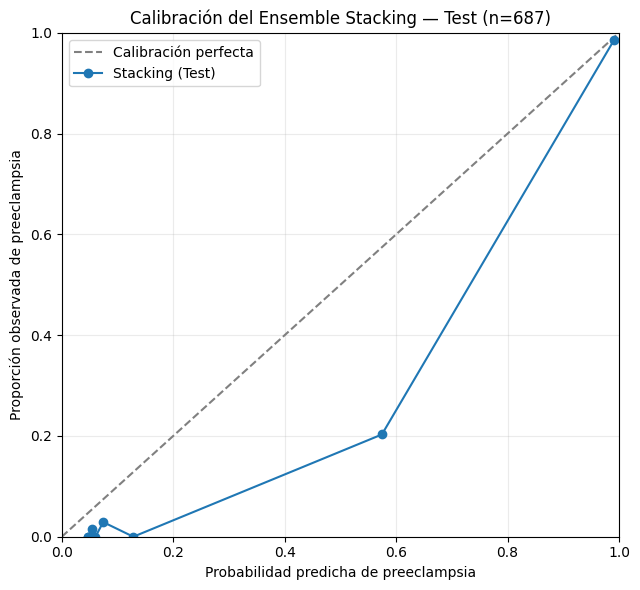


Archivos generados:
- M7_resumen_calibracion.csv
- M7_puntos_curva_calibracion_test.csv
- M7_curva_calibracion_stacking_test_300dpi.png
- M7_curva_calibracion_stacking_test.pdf

No se reentrenó, recalibró ni modificó el Ensemble Stacking.
No se modificó el umbral de 0.21.
Test no constituye validación externa ni prueba totalmente independiente.


In [ ]:
# EVALUACION DE LA CALIBRACION DEL STACKING
# No modifica el modelo final, sus predicciones ni el umbral.
# ============================================================

from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

# 1. Validar que se conservan las predicciones originales
for variable in ["stacking_model", "proba_val_stack", "proba_test_stack", "y_val", "y_test", "FINAL_THRESHOLD"]:
    assert variable in globals(), f"Falta {variable}; ejecuta previamente la Fase 5."

assert len(y_val) == len(proba_val_stack) == 686
assert len(y_test) == len(proba_test_stack) == 687
assert np.isclose(FINAL_THRESHOLD, 0.21)

# 2. Evaluación descriptiva de calibración de probabilidades
# La regresión siguiente no sustituye ni modifica el stacking.
def evaluar_calibracion_M7(y_observado, probabilidad, conjunto):
    y_obs = np.asarray(y_observado, dtype=int).ravel()
    p = np.asarray(probabilidad, dtype=float).ravel()
    assert len(y_obs) == len(p)
    assert set(np.unique(y_obs)) == {0, 1}
    assert np.all(np.isfinite(p)) and np.all((p >= 0) & (p <= 1))

    # Evita log(0) y log(1) al estimar el intercepto y pendiente.
    p_lim = np.clip(p, 1e-6, 1 - 1e-6)
    logit_p = np.log(p_lim / (1.0 - p_lim)).reshape(-1, 1)

    # Regresión de calibración: logit Pr(Y=1) = intercepto + pendiente*logit(p)
    # Los coeficientes se ESTIMAN para evaluar; no se aplican a p.
    regresion_calibracion = LogisticRegression(
        penalty=None, solver="lbfgs", max_iter=5000, tol=1e-9
    )
    regresion_calibracion.fit(logit_p, y_obs)

    return {
        "Conjunto": conjunto,
        "n": len(y_obs),
        "Eventos": int(y_obs.sum()),
        "Prevalencia observada": float(y_obs.mean()),
        "Probabilidad media predicha": float(p.mean()),
        "Brier score": float(brier_score_loss(y_obs, p)),
        "Intercepto (regresion conjunta)": float(regresion_calibracion.intercept_[0]),
        "Pendiente (regresion conjunta)": float(regresion_calibracion.coef_[0, 0]),
    }

calib_val = evaluar_calibracion_M7(y_val, proba_val_stack, "Validation")
calib_test = evaluar_calibracion_M7(y_test, proba_test_stack, "Test")
resumen_calibracion_M7 = pd.DataFrame([calib_val, calib_test])

# 3. Comprobación: discriminación de Test se mantiene idéntica.
assert np.isclose(
    roc_auc_score(np.asarray(y_test).ravel(), np.asarray(proba_test_stack).ravel()),
    roc_auc_stack_test, atol=1e-10
)
assert np.isclose(
    average_precision_score(np.asarray(y_test).ravel(), np.asarray(proba_test_stack).ravel()),
    ap_stack_test, atol=1e-10
)

print("==============================================")
print("M7 - CALIBRACION DEL ENSEMBLE STACKING")
print("==============================================")
print("Valores ideales: intercepto = 0; pendiente = 1; Brier menor es mejor.")
print("Intercepto y pendiente se estimaron conjuntamente sobre logit(p).")
display(resumen_calibracion_M7.round(4))

# 4. Curva empírica de calibración para Test (10 intervalos por cuantiles)
y_test_M7 = np.asarray(y_test, dtype=int).ravel()
p_test_M7 = np.asarray(proba_test_stack, dtype=float).ravel()
fraccion_positivos, prob_media = calibration_curve(
    y_test_M7, p_test_M7, n_bins=10, strategy="quantile"
)

puntos_calibracion_M7 = pd.DataFrame({
    "Probabilidad_media_predicha": prob_media,
    "Frecuencia_positivos_observada": fraccion_positivos
})

fig, ax = plt.subplots(figsize=(6.5, 6.0))
ax.plot([0, 1], [0, 1], "--", color="0.5", label="Calibración perfecta")
ax.plot(prob_media, fraccion_positivos, "o-", label="Stacking (Test)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Probabilidad predicha de preeclampsia")
ax.set_ylabel("Proporción observada de preeclampsia")
ax.set_title("Calibración del Ensemble Stacking — Test (n=687)")
ax.legend(loc="best")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("M7_curva_calibracion_stacking_test_300dpi.png", dpi=300, bbox_inches="tight")
fig.savefig("M7_curva_calibracion_stacking_test.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# 5. Guardar resultados para el artículo
resumen_calibracion_M7.to_csv("M7_resumen_calibracion.csv", index=False)
puntos_calibracion_M7.to_csv("M7_puntos_curva_calibracion_test.csv", index=False)

print("\nArchivos generados:")
print("- M7_resumen_calibracion.csv")
print("- M7_puntos_curva_calibracion_test.csv")
print("- M7_curva_calibracion_stacking_test_300dpi.png")
print("- M7_curva_calibracion_stacking_test.pdf")
print("\nNo se reentrenó, recalibró ni modificó el Ensemble Stacking.")
print("No se modificó el umbral de 0.21.")
print("Test no constituye validación externa ni prueba totalmente independiente.")


In [ ]:
# M8. INTERVALOS DE CONFIANZA BOOTSTRAP Y DELONG PAREADO (TEST)
# Reutiliza modelos ya ajustados: no reentrena, no cambia el umbral.
# =====================================================================

from scipy.stats import norm
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.utils.validation import check_is_fitted

# 1. Verificar la disponibilidad y alineación de resultados de Test.
variables_M8 = [
    "stacking_model", "best_estimators", "X_test", "y_test",
    "proba_test_stack", "pred_test_stack", "FINAL_THRESHOLD",
    "roc_auc_stack_test", "ap_stack_test"
]
for variable_M8 in variables_M8:
    assert variable_M8 in globals(), (
        f"Falta {variable_M8}; ejecuta las fases anteriores sin omitir celdas."
    )

check_is_fitted(stacking_model)
assert "LGBM" in best_estimators, "No se encuentra LightGBM optimizado en Train."
lgbm_M8 = best_estimators["LGBM"]
check_is_fitted(lgbm_M8)

y_M8 = np.asarray(y_test, dtype=int).ravel()
p_stack_M8 = np.asarray(proba_test_stack, dtype=float).ravel()
assert len(X_test) == len(y_M8) == len(p_stack_M8) == 687
assert set(np.unique(y_M8)) == {0, 1}, "Test debe contener ambas clases."
assert np.isclose(FINAL_THRESHOLD, 0.21), "No cambiar el umbral del artículo."
assert np.array_equal((p_stack_M8 >= FINAL_THRESHOLD).astype(int),
                      np.asarray(pred_test_stack, dtype=int).ravel())

if isinstance(X_test, pd.DataFrame) and isinstance(y_test, pd.Series):
    assert X_test.index.equals(y_test.index), (
        "Los índices X_test/y_test no están alineados; verificar el particionado."
    )

# Las clases de la salida probabilística deben verificarse, no asumirse.
clases_lgbm_M8 = np.asarray(lgbm_M8.named_steps["model"].classes_)
col_pos_M8 = np.flatnonzero(clases_lgbm_M8 == 1)
assert len(col_pos_M8) == 1, "No se identifica la clase positiva en LightGBM."
p_lgbm_M8 = np.asarray(lgbm_M8.predict_proba(X_test), dtype=float)[:, int(col_pos_M8[0])]

for nombre_M8, probabilidades_M8 in [
    ("Stacking", p_stack_M8), ("LightGBM", p_lgbm_M8)
]:
    assert len(probabilidades_M8) == len(y_M8)
    assert np.all(np.isfinite(probabilidades_M8))
    assert np.all((probabilidades_M8 >= 0) & (probabilidades_M8 <= 1)), nombre_M8

auc_stack_M8 = float(roc_auc_score(y_M8, p_stack_M8))
ap_stack_M8 = float(average_precision_score(y_M8, p_stack_M8))
f1_stack_M8 = float(f1_score(y_M8, p_stack_M8 >= FINAL_THRESHOLD, zero_division=0))
assert np.isclose(auc_stack_M8, roc_auc_stack_test, atol=1e-10)
assert np.isclose(ap_stack_M8, ap_stack_test, atol=1e-10)

# 2. Bootstrap estratificado: cada remuestra mantiene n positivos y n negativos.
# Mismo muestreo para ambos modelos => comparación pareada.
N_BOOT_M8 = 3000
SEMILLA_M8 = 42
rng_M8 = np.random.default_rng(SEMILLA_M8)
indices_neg_M8 = np.flatnonzero(y_M8 == 0)
indices_pos_M8 = np.flatnonzero(y_M8 == 1)

boot_auc_stack_M8 = np.empty(N_BOOT_M8)
boot_ap_stack_M8 = np.empty(N_BOOT_M8)
boot_f1_stack_M8 = np.empty(N_BOOT_M8)
boot_auc_lgbm_M8 = np.empty(N_BOOT_M8)
boot_ap_lgbm_M8 = np.empty(N_BOOT_M8)

for b_M8 in range(N_BOOT_M8):
    idx_M8 = np.concatenate([
        rng_M8.choice(indices_neg_M8, len(indices_neg_M8), replace=True),
        rng_M8.choice(indices_pos_M8, len(indices_pos_M8), replace=True),
    ])
    y_b_M8 = y_M8[idx_M8]
    ps_b_M8 = p_stack_M8[idx_M8]
    pl_b_M8 = p_lgbm_M8[idx_M8]

    boot_auc_stack_M8[b_M8] = roc_auc_score(y_b_M8, ps_b_M8)
    boot_ap_stack_M8[b_M8] = average_precision_score(y_b_M8, ps_b_M8)
    boot_f1_stack_M8[b_M8] = f1_score(
        y_b_M8, (ps_b_M8 >= FINAL_THRESHOLD).astype(int), zero_division=0
    )
    boot_auc_lgbm_M8[b_M8] = roc_auc_score(y_b_M8, pl_b_M8)
    boot_ap_lgbm_M8[b_M8] = average_precision_score(y_b_M8, pl_b_M8)

def ic_percentil_M8(valores):
    return tuple(np.percentile(np.asarray(valores), [2.5, 97.5]).astype(float))

# 3. DeLong pareado: estimador de la matriz de covarianza para dos AUC.
# V10: prob. de superar a un negativo para cada positivo.
# V01: prob. de ser superado por un positivo para cada negativo.
# Se cuenta empate como 0.5 (maneja puntajes repetidos).
def prueba_delong_pareada_M8(etiquetas, scores_a, scores_b):
    y = np.asarray(etiquetas, dtype=int).ravel()
    scores = np.vstack([np.asarray(scores_a, dtype=float),
                        np.asarray(scores_b, dtype=float)])
    pos = scores[:, y == 1]  # 2 x n_positivos
    neg = scores[:, y == 0]  # 2 x n_negativos
    m, n = pos.shape[1], neg.shape[1]
    assert m >= 2 and n >= 2, "Se necesitan al menos dos casos de cada clase."

    comparaciones = (pos[:, :, None] > neg[:, None, :]).astype(float)
    comparaciones += 0.5 * (pos[:, :, None] == neg[:, None, :])
    v10 = comparaciones.mean(axis=2)  # 2 x m
    v01 = comparaciones.mean(axis=1)  # 2 x n
    aucs = v10.mean(axis=1)
    cov = np.atleast_2d(np.cov(v10, ddof=1)) / m + np.atleast_2d(np.cov(v01, ddof=1)) / n

    # Comprobación contra la implementación independiente de sklearn.
    assert np.isclose(aucs[0], roc_auc_score(y, scores[0]), atol=1e-12)
    assert np.isclose(aucs[1], roc_auc_score(y, scores[1]), atol=1e-12)

    diferencia = float(aucs[0] - aucs[1])
    var_diferencia = float(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    assert var_diferencia >= -1e-12, "Varianza DeLong negativa: revisar datos."
    error_estandar = float(np.sqrt(max(var_diferencia, 0.0)))
    if error_estandar <= 1e-12:
        assert np.isclose(diferencia, 0, atol=1e-12), (
            "DeLong presenta varianza degenerada y AUC distintos; no se puede calcular p."
        )
        z, p_valor = 0.0, 1.0
    else:
        z = diferencia / error_estandar
        p_valor = float(2 * norm.sf(abs(z)))
    return {
        "ROC-AUC Stacking": float(aucs[0]),
        "ROC-AUC LightGBM": float(aucs[1]),
        "Diferencia AUC (Stacking - LightGBM)": diferencia,
        "SE diferencia (DeLong)": error_estandar,
        "Z": float(z),
        "p bilateral (DeLong)": p_valor,
    }

resultado_delong_M8 = prueba_delong_pareada_M8(y_M8, p_stack_M8, p_lgbm_M8)
resultado_delong_M8.update({"Conjunto": "Test", "n": len(y_M8),
                            "Eventos": int(y_M8.sum())})

# 4. Resultados para tabla de artículo / revisión metodológica.
filas_M8 = []
for nombre_M8, metrica_M8, estimado_M8, distrib_M8 in [
    ("Stacking", "ROC-AUC", auc_stack_M8, boot_auc_stack_M8),
    ("Stacking", "Average Precision", ap_stack_M8, boot_ap_stack_M8),
    ("Stacking", "F1-score (umbral 0.21)", f1_stack_M8, boot_f1_stack_M8),
    ("LightGBM", "ROC-AUC", roc_auc_score(y_M8, p_lgbm_M8), boot_auc_lgbm_M8),
    ("LightGBM", "Average Precision", average_precision_score(y_M8, p_lgbm_M8), boot_ap_lgbm_M8),
]:
    li_M8, ls_M8 = ic_percentil_M8(distrib_M8)
    filas_M8.append({
        "Conjunto": "Test", "Modelo": nombre_M8, "Metrica": metrica_M8,
        "Estimacion": float(estimado_M8), "IC95_inferior": li_M8, "IC95_superior": ls_M8,
        "Bootstrap": N_BOOT_M8, "Metodo": "percentil estratificado",
    })

resumen_bootstrap_M8 = pd.DataFrame(filas_M8)
comparacion_delong_M8 = pd.DataFrame([resultado_delong_M8])
diferencias_bootstrap_M8 = pd.DataFrame([
    {"Metrica": "Diferencia ROC-AUC (Stacking - LightGBM)",
     "Estimacion": resultado_delong_M8["Diferencia AUC (Stacking - LightGBM)"],
     "IC95_inferior": ic_percentil_M8(boot_auc_stack_M8 - boot_auc_lgbm_M8)[0],
     "IC95_superior": ic_percentil_M8(boot_auc_stack_M8 - boot_auc_lgbm_M8)[1]},
    {"Metrica": "Diferencia AP (Stacking - LightGBM)",
     "Estimacion": float(ap_stack_M8 - average_precision_score(y_M8, p_lgbm_M8)),
     "IC95_inferior": ic_percentil_M8(boot_ap_stack_M8 - boot_ap_lgbm_M8)[0],
     "IC95_superior": ic_percentil_M8(boot_ap_stack_M8 - boot_ap_lgbm_M8)[1]},
])

print("=" * 65)
print("M8 - INTERVALOS DE CONFIANZA BOOTSTRAP E INFERENCIA DELONG")
print("=" * 65)
print(f"Test: n={len(y_M8)}; eventos={y_M8.sum()}; umbral Stacking={FINAL_THRESHOLD:.2f}")
print(f"Bootstrap: {N_BOOT_M8} remuestras estratificadas; semilla={SEMILLA_M8}")
print("\nEstimaciones e intervalos de confianza del 95 %:")
display(resumen_bootstrap_M8.round(5))
print("\nComparación pareada Stacking vs LightGBM (ROC-AUC):")
display(comparacion_delong_M8.round(6))
print("\nDiferencias pareadas por bootstrap (exploratorias):")
display(diferencias_bootstrap_M8.round(5))

# 5. Guardar exactamente los resultados producidos por esta ejecución.
resumen_bootstrap_M8.to_csv("M8_bootstrap_IC95_test.csv", index=False)
comparacion_delong_M8.to_csv("M8_DeLong_stacking_vs_LightGBM_test.csv", index=False)
diferencias_bootstrap_M8.to_csv("M8_diferencias_pareadas_bootstrap_test.csv", index=False)

print("\nArchivos generados:")
print("- M8_bootstrap_IC95_test.csv")
print("- M8_DeLong_stacking_vs_LightGBM_test.csv")
print("- M8_diferencias_pareadas_bootstrap_test.csv")
print("\nNo se reentrenaron modelos ni se modificó el umbral de 0.21.")
print("DeLong compara ambos modelos sobre los mismos registros Test.")
print("Test fue explorado previamente: estas inferencias requieren cautela.")

M8 - INTERVALOS DE CONFIANZA BOOTSTRAP E INFERENCIA DELONG
Test: n=687; eventos=85; umbral Stacking=0.21
Bootstrap: 3000 remuestras estratificadas; semilla=42

Estimaciones e intervalos de confianza del 95 %:


,Conjunto,Modelo,Metrica,Estimacion,IC95_inferior,IC95_superior,Bootstrap,Metodo
0,Test,Stacking,ROC-AUC,0.98673,0.97262,0.99732,3000,percentil estratificado
1,Test,Stacking,Average Precision,0.95862,0.92506,0.98543,3000,percentil estratificado
2,Test,Stacking,F1-score (umbral 0.21),0.73543,0.68619,0.78673,3000,percentil estratificado
3,Test,LightGBM,ROC-AUC,0.98603,0.96738,0.99744,3000,percentil estratificado
4,Test,LightGBM,Average Precision,0.96119,0.93086,0.98579,3000,percentil estratificado



Comparación pareada Stacking vs LightGBM (ROC-AUC):


,ROC-AUC Stacking,ROC-AUC LightGBM,Diferencia AUC (Stacking - LightGBM),SE diferencia (DeLong),Z,p bilateral (DeLong),Conjunto,n,Eventos
0,0.986731,0.986027,0.000704,0.0039,0.180387,0.856849,Test,687,85



Diferencias pareadas por bootstrap (exploratorias):


,Metrica,Estimacion,IC95_inferior,IC95_superior
0,Diferencia ROC-AUC (Stacking - LightGBM),0.00070,-0.00643,0.00901
1,Diferencia AP (Stacking - LightGBM),-0.00257,-0.01346,0.00729



Archivos generados:
- M8_bootstrap_IC95_test.csv
- M8_DeLong_stacking_vs_LightGBM_test.csv
- M8_diferencias_pareadas_bootstrap_test.csv

No se reentrenaron modelos ni se modificó el umbral de 0.21.
DeLong compara ambos modelos sobre los mismos registros Test.
Test fue explorado previamente: estas inferencias requieren cautela.


In [ ]:
# ================================================================
# AUDITORIA Y ANALISIS EXPLORATORIO DE SENSIBILIDAD
# No modifica stacking_model, su umbral, Train/Validation/Test
# ================================================================

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.utils.validation import check_is_fitted
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC, SMOTE

# --- 1. Comprobaciones previas ---
for nombre_M2 in ["X_train", "X_val", "y_train", "y_val",
                  "stacking_model", "proba_val_stack", "best_estimators",
                  "numeric_features", "binary_features", "cv", "metamodelo"]:
    assert nombre_M2 in globals(), f"Falta {nombre_M2}; ejecutar las fases anteriores."

check_is_fitted(stacking_model)
columnas_originales_M2 = list(numeric_features) + list(binary_features)
assert len(columnas_originales_M2) == 8
assert list(X_train.columns) == columnas_originales_M2
assert list(X_val.columns) == columnas_originales_M2
assert len(X_train) == len(y_train) == 3201
assert len(X_val) == len(y_val) == 686
assert all(nombre in best_estimators for nombre in ["LR", "MLP", "SVM", "LGBM", "CAT"])
assert np.asarray(proba_val_stack).shape == (len(y_val),)
if isinstance(y_train, pd.Series):
    assert X_train.index.equals(y_train.index)
if isinstance(y_val, pd.Series):
    assert X_val.index.equals(y_val.index)

# Auditoria de las columnas: el CSV no contiene fechas ni identificadores.
print("=== M2: ESTRUCTURA Y LIMITACIONES DE PROCEDENCIA ===")
print("Columnas disponibles en el dataset de modelado:", columnas_originales_M2 + ["Preeclampsia"])
print("No hay fecha de medición, fecha del diagnóstico, año ni ID de paciente en X.")
print("No se puede verificar temporalidad ni distinguir gestantes unicas con estas columnas.")
print("La variable hipertension puede representar antecedente previo o registro durante la evaluación;")
print("su definición y su relación temporal con el desenlace requieren confirmación clínica.")

resumen_factores_M2 = []
for col_M2 in ["hipertension", "diabetes", "ant_fam_hiper"]:
    for grupo_M2 in [0, 1]:
        seleccion_M2 = (np.asarray(y_train) == grupo_M2)
        valores_M2 = X_train.loc[seleccion_M2, col_M2]
        resumen_factores_M2.append({
            "Variable": col_M2,
            "Grupo": "Con preeclampsia" if grupo_M2 == 1 else "Sin preeclampsia",
            "n": int(seleccion_M2.sum()),
            "Positivos_variable": int((valores_M2 == 1).sum()),
            "Porcentaje_variable_1": float((valores_M2 == 1).mean()*100),
        })
resumen_factores_M2 = pd.DataFrame(resumen_factores_M2)
print("\nFrecuencias de predictores binarios en Train (sin usar Test):")
display(resumen_factores_M2.round(2))

# --- 2. Preparar variantes auxiliares con hiperparámetros FIJOS ---
def construir_stacking_auxiliar_M2(num_cols, bin_cols):
    assert len(num_cols) >= 1, "Se requiere al menos una variable numérica."
    cols = list(num_cols) + list(bin_cols)
    assert set(cols).issubset(set(columnas_originales_M2))

    transformadores = [("num", clone(numeric_pipeline), list(num_cols))]
    if bin_cols:
        transformadores.append(("bin", clone(binary_pipeline), list(bin_cols)))
    preproc_aux = ColumnTransformer(transformadores, remainder="drop")

    if bin_cols:
        remuestreador = SMOTENC(
            categorical_features=list(range(len(num_cols), len(cols))),
            random_state=42, k_neighbors=3
        )
        nombre_balanceo = "SMOTENC"
    else:
        # SMOTENC requiere al menos una variable categórica; excepción documentada.
        remuestreador = SMOTE(random_state=42, k_neighbors=3)
        nombre_balanceo = "SMOTE"

    estimadores = []
    for nombre in ["LR", "MLP", "SVM", "LGBM", "CAT"]:
        clasificador = clone(best_estimators[nombre].named_steps["model"])
        estimadores.append((nombre, ImbPipeline([
            ("preprocessor", clone(preproc_aux)),
            ("smotenc" if bin_cols else "smote", clone(remuestreador)),
            ("model", clasificador)
        ])))

    auxiliar = StackingClassifier(
        estimators=estimadores,
        final_estimator=clone(metamodelo),
        cv=cv,
        stack_method="predict_proba",
        passthrough=False,
        n_jobs=1,
    )
    return auxiliar, cols, nombre_balanceo

# --- 3. Comparaciones en Validation, sin utilizar Test ---
y_val_M2 = np.asarray(y_val, dtype=int).ravel()
prob_base_M2 = np.asarray(proba_val_stack, dtype=float).ravel()
filas_M2 = [{
    "Escenario": "Stacking completo (8 variables)",
    "n_variables": 8,
    "Variables": ", ".join(columnas_originales_M2),
    "Remuestreo": "SMOTENC",
    "ROC_AUC_Validation": roc_auc_score(y_val_M2, prob_base_M2),
    "AP_Validation": average_precision_score(y_val_M2, prob_base_M2),
}]

escenarios_M2 = [
    ("Sin hipertensión", list(numeric_features), ["diabetes", "ant_fam_hiper"]),
    ("Sin hipertensión ni diabetes", list(numeric_features), ["ant_fam_hiper"]),
    ("Solo PAM", ["pam"], []),
]
for etiqueta_M2, num_M2, bin_M2 in escenarios_M2:
    print(f"\nEntrenando modelo auxiliar M2: {etiqueta_M2}")
    modelo_aux_M2, cols_M2, balanceo_M2 = construir_stacking_auxiliar_M2(num_M2, bin_M2)
    # Unicamente Train: no hay selección de umbral, ni uso de Test.
    modelo_aux_M2.fit(X_train[cols_M2], y_train)
    clases_M2 = list(modelo_aux_M2.classes_)
    pos_M2 = clases_M2.index(1)
    proba_aux_M2 = np.asarray(modelo_aux_M2.predict_proba(X_val[cols_M2])[:, pos_M2], dtype=float)
    filas_M2.append({
        "Escenario": etiqueta_M2,
        "n_variables": len(cols_M2),
        "Variables": ", ".join(cols_M2),
        "Remuestreo": balanceo_M2,
        "ROC_AUC_Validation": roc_auc_score(y_val_M2, proba_aux_M2),
        "AP_Validation": average_precision_score(y_val_M2, proba_aux_M2),
    })

resultados_sensibilidad_M2 = pd.DataFrame(filas_M2)
auc_base_M2 = resultados_sensibilidad_M2.loc[0, "ROC_AUC_Validation"]
ap_base_M2 = resultados_sensibilidad_M2.loc[0, "AP_Validation"]
resultados_sensibilidad_M2["Diferencia_AUC_vs_completo"] = resultados_sensibilidad_M2["ROC_AUC_Validation"] - auc_base_M2
resultados_sensibilidad_M2["Diferencia_AP_vs_completo"] = resultados_sensibilidad_M2["AP_Validation"] - ap_base_M2

print("\n" + "="*68)
print("M2 - SENSIBILIDAD EXPLORATORIA EN VALIDATION (N=686)")
print("="*68)
display(resultados_sensibilidad_M2.round(5))
print("\nInterpretar como ablation exploratoria, no como estimación independiente.")
print("Se preservaron sin cambios el modelo final, Test y el umbral de decisión.")
print("Solo PAM utilizó SMOTE en lugar de SMOTENC al no existir variables categóricas.")
print("Los hiperparámetros provienen de la optimización original con ocho variables.")
print("Los resultados NO permiten verificar la temporalidad ni descartar fugas clínicas.")

resultados_sensibilidad_M2.to_csv("M2_sensibilidad_predictores_validation.csv", index=False)
resumen_factores_M2.to_csv("M2_frecuencia_binarias_train.csv", index=False)
print("\nArchivos generados: M2_sensibilidad_predictores_validation.csv y M2_frecuencia_binarias_train.csv")

=== M2: ESTRUCTURA Y LIMITACIONES DE PROCEDENCIA ===
Columnas disponibles en el dataset de modelado: ['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina', 'hipertension', 'diabetes', 'ant_fam_hiper', 'Preeclampsia']
No hay fecha de medición, fecha del diagnóstico, año ni ID de paciente en X.
No se puede verificar temporalidad ni distinguir gestantes unicas con estas columnas.
La variable hipertension puede representar antecedente previo o registro durante la evaluación;
su definición y su relación temporal con el desenlace requieren confirmación clínica.

Frecuencias de predictores binarios en Train (sin usar Test):


,Variable,Grupo,n,Positivos_variable,Porcentaje_variable_1
0,hipertension,Sin preeclampsia,2805,43,1.53
1,hipertension,Con preeclampsia,396,183,46.21
2,diabetes,Sin preeclampsia,2805,69,2.46
3,diabetes,Con preeclampsia,396,173,43.69
4,ant_fam_hiper,Sin preeclampsia,2805,267,9.52
5,ant_fam_hiper,Con preeclampsia,396,192,48.48



Entrenando modelo auxiliar M2: Sin hipertensión

Entrenando modelo auxiliar M2: Sin hipertensión ni diabetes

Entrenando modelo auxiliar M2: Solo PAM

M2 - SENSIBILIDAD EXPLORATORIA EN VALIDATION (N=686)


,Escenario,n_variables,Variables,Remuestreo,ROC_AUC_Validation,AP_Validation,Diferencia_AUC_vs_completo,Diferencia_AP_vs_completo
0,Stacking completo (8 variables),8,"edad, edad_gestacion, imc, pam, hemoglobina, h...",SMOTENC,0.98305,0.94093,0.00000,0.00000
1,Sin hipertensión,7,"edad, edad_gestacion, imc, pam, hemoglobina, d...",SMOTENC,0.97909,0.93597,-0.00395,-0.00496
2,Sin hipertensión ni diabetes,6,"edad, edad_gestacion, imc, pam, hemoglobina, a...",SMOTENC,0.97680,0.92908,-0.00624,-0.01185
3,Solo PAM,1,pam,SMOTE,0.93138,0.58271,-0.05167,-0.35822



Interpretar como ablation exploratoria, no como estimación independiente.
Se preservaron sin cambios el modelo final, Test y el umbral de decisión.
Solo PAM utilizó SMOTE en lugar de SMOTENC al no existir variables categóricas.
Los hiperparámetros provienen de la optimización original con ocho variables.
Los resultados NO permiten verificar la temporalidad ni descartar fugas clínicas.

Archivos generados: M2_sensibilidad_predictores_validation.csv y M2_frecuencia_binarias_train.csv


M1: validación interna anidada de arquitectura fija
Outer: 5 folds x 2 repeticiones
Inner: 3 folds; tuning: 20 configuraciones por clasificador
Predictores: ['edad', 'edad_gestacion', 'imc', 'pam', 'hemoglobina', 'hipertension', 'diabetes', 'ant_fam_hiper']
Folds completados anteriormente: []

[M1 1/10] Repetición 1, fold 1; desarrollo n=3659, evaluación n=915
  Ajustando LR en los pliegues internos...
  Ajustando MLP en los pliegues internos...
  Ajustando SVM en los pliegues internos...
  Ajustando LGBM en los pliegues internos...
  Ajustando CAT en los pliegues internos...
  Generando OOF de Train externo para umbrales Stacking y LightGBM...
  Entrenando modelos sobre desarrollo externo y evaluando pliegue reservado...
  Guardado. ROC-AUC: Stacking 0.9905 | LightGBM 0.9910

[M1 2/10] Repetición 1, fold 2; desarrollo n=3659, evaluación n=915
  Ajustando LR en los pliegues internos...
  Ajustando MLP en los pliegues internos...
  Ajustando SVM en los pliegues internos...
  Ajustando L

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Specificity_mean,Specificity_std,F1_mean,...,ROC_AUC_mean,ROC_AUC_std,AP_mean,AP_std,FN_mean,FN_std,FP_mean,FP_std,Umbral_mean,Umbral_std
0,LightGBM,0.9427,0.0166,0.7160,0.0859,0.9204,0.0310,0.9459,0.0214,0.8020,...,0.9798,0.0094,0.9352,0.0156,9.0,3.4960,43.4,17.1412,0.108,0.0092
1,Stacking,0.9138,0.0119,0.5971,0.0336,0.9425,0.0272,0.9097,0.0123,0.7307,...,0.9784,0.0120,0.9335,0.0171,6.5,3.0641,72.4,9.9242,0.229,0.0099



Resultados por pliegue:


,Pliegue,Repeticion,Fold_externo,Modelo,Objetivo_recall_OOF_alcanzado,n_evaluacion,n_positivos,Umbral,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,AP,TN,FP,FN,TP
1,1,1,1,LightGBM,False,915,114,0.10,0.9301,0.6453,0.9737,0.9238,0.7762,0.9910,0.9435,740,61,3,111
0,1,1,1,Stacking,True,915,114,0.23,0.9213,0.6141,0.9912,0.9114,0.7584,0.9905,0.9465,730,71,1,113
3,2,1,2,LightGBM,False,915,113,0.11,0.9432,0.6943,0.9646,0.9401,0.8074,0.9865,0.9492,754,48,4,109
2,2,1,2,Stacking,True,915,113,0.23,0.9115,0.5870,0.9558,0.9052,0.7273,0.9878,0.9457,726,76,5,108
5,3,1,3,LightGBM,False,915,113,0.10,0.9224,0.6265,0.9204,0.9227,0.7455,0.9651,0.9153,740,62,9,104
4,3,1,3,Stacking,True,915,113,0.22,0.8874,0.5248,0.9381,0.8803,0.6730,0.9660,0.9206,706,96,7,106
7,4,1,4,LightGBM,False,915,113,0.12,0.9650,0.8293,0.9027,0.9738,0.8644,0.9882,0.9629,781,21,11,102
6,4,1,4,Stacking,True,915,113,0.24,0.9158,0.6011,0.9469,0.9115,0.7354,0.9895,0.9570,731,71,6,107
9,5,1,5,LightGBM,True,914,113,0.10,0.9344,0.6803,0.8850,0.9413,0.7692,0.9724,0.9094,754,47,13,100
8,5,1,5,Stacking,True,914,113,0.21,0.9114,0.5941,0.8938,0.9139,0.7138,0.9599,0.9018,732,69,12,101



Diferencias pareadas por pliegue (exploratorias):


,Pliegue,Delta_ROC_AUC_Stacking_menos_LGBM,Delta_AP_Stacking_menos_LGBM,Delta_Recall_Stacking_menos_LGBM,Delta_Specificity_Stacking_menos_LGBM
0,1,-0.0005,0.0031,0.0175,-0.0125
1,2,0.0013,-0.0035,-0.0088,-0.0349
2,3,0.0009,0.0053,0.0177,-0.0424
3,4,0.0013,-0.0059,0.0442,-0.0623
4,5,-0.0125,-0.0075,0.0088,-0.0275
5,6,-0.0006,0.0110,0.0351,-0.0150
6,7,-0.0037,0.0035,0.0796,-0.0536
7,8,-0.0033,-0.0136,-0.0177,-0.0287
8,9,-0.0074,-0.0117,0.0000,-0.0274
9,10,0.0109,0.0026,0.0442,-0.0574


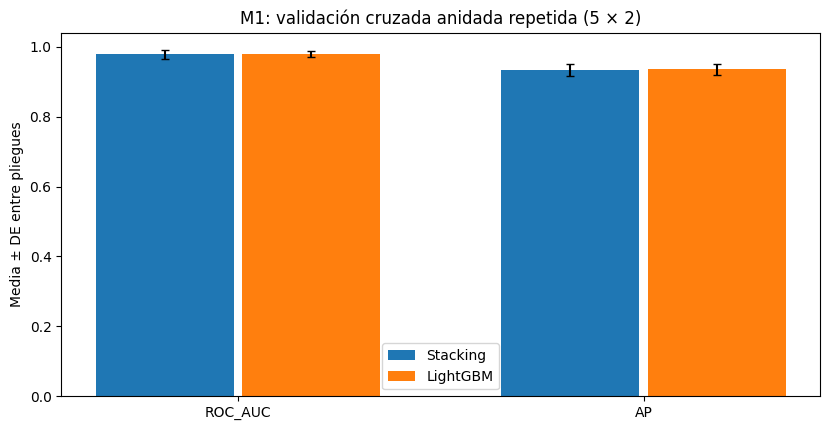


Archivos guardados en: /content/M1_validacion_anidada
Interpretación: validación interna de la arquitectura fijada, NO validación externa.
No interpretar media±DE de 10 pliegues correlacionados como IC95%.
No sustituir resultados originales sin revisar la metodología y las limitaciones.


In [ ]:
# VALIDACIÓN CRUZADA ANIDADA REPETIDA (5x2) — ANÁLISIS ADICIONAL
# Arquitectura fijada: LR, MLP, SVM, LGBM, CAT -> Meta_LR
# Optimización anidada dentro de Train externo (sin usar el pliegue externo)
# Umbral por OOF del Train externo; evaluación solo en Test externo.
# NO usa best_estimators ni stacking_model ya entrenados.
# ===========================================================================

import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold,
    RandomizedSearchCV, cross_val_predict
)
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
from catboost import CatBoostClassifier

# 1. Configuración declarada ANTES de ejecutar el experimento
PLIEGUES_EXTERNOS_M1 = 5
REPETICIONES_M1 = 2
PLIEGUES_INTERNOS_M1 = 3
N_ITER_M1 = 20                     # misma cantidad de configuraciones del tuning original
SEMILLA_M1 = 42
MIN_SPECIFICITY_M1 = 0.90
TARGET_RECALL_M1 = 0.93
UMBRAL_GRID_M1 = np.round(np.arange(0.10, 0.901, 0.01), 2)
REANUDAR_M1 = True
CARPETA_M1 = Path('M1_validacion_anidada')
CARPETA_M1.mkdir(parents=True, exist_ok=True)

NOMBRES_BASE_M1 = ('LR', 'MLP', 'SVM', 'LGBM', 'CAT')

# 2. Controles: reconstruimos modelos a partir de sus clases/espacios originales,
# no de estimadores ajustados con la partición original.
for variable_M1 in ('X', 'y', 'candidates', 'param_spaces', 'build_pipe', 'metamodelos'):
    assert variable_M1 in globals(), f'Falta {variable_M1}. Ejecuta las fases previas.'
assert list(X.columns) == [
    'edad','edad_gestacion','imc','pam','hemoglobina',
    'hipertension','diabetes','ant_fam_hiper'
], 'La estructura o el orden de predictores ha cambiado.'
assert len(X) == len(y) == 4574, 'Se esperaban 4574 registros ya depurados.'
assert not X.isna().all(axis=1).any(), 'Hay una fila sin ningún predictor.'
assert set(np.unique(np.asarray(y, dtype=int))) == {0, 1}
assert all(name in dict(candidates) and name in param_spaces for name in NOMBRES_BASE_M1)
assert 'Meta_LR' in metamodelos
assert getattr(metamodelos['Meta_LR'], 'class_weight', None) == 'balanced'
assert X.index.equals(y.index), 'X e y deben conservar el mismo índice.'

# Huella para impedir reanudar archivos de otro dataset/configuración.
resumen_cfg_M1 = {
    'n_filas':len(X), 'columnas':list(X.columns),
    'pliegues_externos':PLIEGUES_EXTERNOS_M1, 'repeticiones':REPETICIONES_M1,
    'pliegues_internos':PLIEGUES_INTERNOS_M1, 'n_iter':N_ITER_M1,
    'semilla':SEMILLA_M1, 'min_spec':MIN_SPECIFICITY_M1,
    'target_recall':TARGET_RECALL_M1, 'modelos':list(NOMBRES_BASE_M1),
    'umbrales':list(np.asarray(UMBRAL_GRID_M1, dtype=float))
}
hash_datos_M1 = pd.util.hash_pandas_object(
    pd.concat([X.reset_index(drop=True), y.reset_index(drop=True).rename('Preeclampsia')], axis=1),
    index=False
).to_numpy(dtype='uint64').tobytes()
resumen_cfg_M1['huella_datos'] = hashlib.sha256(hash_datos_M1).hexdigest()
ruta_cfg_M1 = CARPETA_M1 / 'M1_configuracion.json'
ruta_metricas_M1 = CARPETA_M1 / 'M1_metricas_pliegues.csv'
ruta_pred_M1 = CARPETA_M1 / 'M1_predicciones_externas.csv'
ruta_ajustes_M1 = CARPETA_M1 / 'M1_hiperparametros_pliegues.csv'

if ruta_cfg_M1.exists() and REANUDAR_M1:
    cfg_anterior_M1 = json.loads(ruta_cfg_M1.read_text(encoding='utf-8'))
    assert cfg_anterior_M1 == resumen_cfg_M1, (
        'Archivos M1 existentes proceden de otros datos o parámetros. '
        'Usa otra carpeta o elimina los archivos previos si deseas reiniciar.'
    )
else:
    if any(p.exists() for p in (ruta_metricas_M1, ruta_pred_M1, ruta_ajustes_M1)):
        raise RuntimeError('Hay CSV previos. Usa otra carpeta para evitar mezclar experimentos.')
    ruta_cfg_M1.write_text(json.dumps(resumen_cfg_M1, indent=2), encoding='utf-8')

modelos_originales_M1 = dict(candidates)

# Compatibilidad opcional: algunas versiones de scikit-learn >= 1.6 exigen
# etiquetas de clasificador en CatBoost; no modificar los experimentos previos.
from sklearn.base import is_classifier
try:
    _catboost_reconocido_M1 = is_classifier(modelos_originales_M1['CAT'])
except (AttributeError, TypeError, RuntimeError):
    _catboost_reconocido_M1 = False
if not _catboost_reconocido_M1:
    from sklearn.utils import Tags, TargetTags, ClassifierTags
    class CatBoostClasificadorCompatibleM1(CatBoostClassifier):
        def __sklearn_tags__(self):
            return Tags(estimator_type='classifier',
                        target_tags=TargetTags(required=True),
                        classifier_tags=ClassifierTags())
    modelos_originales_M1['CAT'] = CatBoostClasificadorCompatibleM1(
        **modelos_originales_M1['CAT'].get_params()
    )
    print('M1: CatBoost adaptado a las etiquetas de clasificador de scikit-learn.')

filas_metricas_M1 = pd.read_csv(ruta_metricas_M1).to_dict('records') if (REANUDAR_M1 and ruta_metricas_M1.exists()) else []
filas_pred_M1 = pd.read_csv(ruta_pred_M1).to_dict('records') if (REANUDAR_M1 and ruta_pred_M1.exists()) else []
filas_ajustes_M1 = pd.read_csv(ruta_ajustes_M1).to_dict('records') if (REANUDAR_M1 and ruta_ajustes_M1.exists()) else []

# Reanudar solamente si hay exactamente dos modelos y las predicciones completas
# para el pliegue ya guardado.
completados_M1 = set()
if filas_metricas_M1 and filas_pred_M1 and filas_ajustes_M1:
    for k in set(int(f['Pliegue']) for f in filas_metricas_M1):
        modelos_k = {str(f['Modelo']) for f in filas_metricas_M1 if int(f['Pliegue']) == k}
        preds_k = [f for f in filas_pred_M1 if int(f['Pliegue']) == k]
        tuning_k = [f for f in filas_ajustes_M1 if int(f['Pliegue']) == k]
        if modelos_k == {'Stacking', 'LightGBM'} and len(preds_k) > 0 and len(tuning_k) == 5:
            completados_M1.add(k)
    assert len(completados_M1)*2 == len(filas_metricas_M1), 'Archivo de métricas M1 incompleto.'
    assert sum(int(f['Pliegue']) in completados_M1 for f in filas_pred_M1) == len(filas_pred_M1), 'Predicciones M1 incompletas.'
    assert len(completados_M1)*5 == len(filas_ajustes_M1), 'Archivo de ajustes M1 incompleto.'

# 3. Funciones auxiliares para el experimento

def nativo_M1(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {k:nativo_M1(v) for k,v in value.items()}
    if isinstance(value, (list, tuple)):
        return type(value)(nativo_M1(v) for v in value)
    return value


def obtener_mejor_pipeline_M1(nombre, resultado):
    # Recopilar parámetros de la búsqueda actual, NO de la optimización original.
    if nombre != 'CAT':
        return clone(resultado.best_estimator_)
    # Evitar errores al clonar CatBoost con numpy scalar params; misma configuración.
    params_cat = nativo_M1(resultado.best_estimator_.named_steps['model'].get_params())
    params_cat.update({'random_state':SEMILLA_M1, 'verbose':False,
                       'allow_writing_files':False, 'thread_count':1})
    return build_pipe(type(modelos_originales_M1['CAT'])(**params_cat))


def elegir_umbral_M1(y_train_local, p_oof):
    y_t = np.asarray(y_train_local, dtype=int)
    p_t = np.asarray(p_oof, dtype=float)
    filas = []
    for um in UMBRAL_GRID_M1:
        yp = (p_t >= um).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_t, yp, labels=[0,1]).ravel()
        filas.append({
            'Umbral':float(um),
            'Recall':float(recall_score(y_t, yp, zero_division=0)),
            'F1':float(f1_score(y_t, yp, zero_division=0)),
            'Specificity':float(tn/(tn+fp)) if tn+fp else np.nan
        })
    df_u = pd.DataFrame(filas)
    permitidos = df_u.loc[df_u['Specificity'] >= MIN_SPECIFICITY_M1]
    if permitidos.empty:
        raise ValueError('Ningún umbral logra la especificidad mínima en Train OOF.')
    ambos = permitidos.loc[permitidos['Recall'] >= TARGET_RECALL_M1]
    candidatos = ambos if not ambos.empty else permitidos
    elegido = candidatos.sort_values(
        by=['Recall','F1','Specificity'], ascending=[False,False,False], kind='mergesort'
    ).iloc[0]
    return float(elegido['Umbral']), bool(not ambos.empty)


def metricas_M1(y_real, probs, umbral):
    y_real=np.asarray(y_real,dtype=int)
    probs=np.asarray(probs,dtype=float)
    preds=(probs>=umbral).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_real,preds,labels=[0,1]).ravel()
    return {
        'n_evaluacion':len(y_real),'n_positivos':int(y_real.sum()),
        'Umbral':float(umbral), 'Accuracy':float(accuracy_score(y_real,preds)),
        'Precision':float(precision_score(y_real,preds,zero_division=0)),
        'Recall':float(recall_score(y_real,preds,zero_division=0)),
        'Specificity':float(tn/(tn+fp)) if tn+fp else np.nan,
        'F1':float(f1_score(y_real,preds,zero_division=0)),
        'ROC_AUC':float(roc_auc_score(y_real,probs)),
        'AP':float(average_precision_score(y_real,probs)),
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)
    }


def guardar_seguro_M1(registros, destino):
    # Escritura atómica por cada pliegue completado
    if not registros:
        return
    temporal=destino.with_suffix('.tmp')
    pd.DataFrame(registros).to_csv(temporal,index=False)
    temporal.replace(destino)

# 4. CV externa: cada fila es evaluada una vez por repetición (dos evaluaciones
# correlacionadas, NO observaciones independientes).
cv_externa_M1 = RepeatedStratifiedKFold(
    n_splits=PLIEGUES_EXTERNOS_M1,
    n_repeats=REPETICIONES_M1,
    random_state=SEMILLA_M1
)
print('M1: validación interna anidada de arquitectura fija')
print('Outer:',PLIEGUES_EXTERNOS_M1,'folds x',REPETICIONES_M1,'repeticiones')
print('Inner:',PLIEGUES_INTERNOS_M1,'folds; tuning:',N_ITER_M1,'configuraciones por clasificador')
print('Predictores:',list(X.columns))
print('Folds completados anteriormente:',sorted(completados_M1))

for pliegue_M1,(idx_desarrollo,idx_externo) in enumerate(cv_externa_M1.split(X,y),start=1):
    if pliegue_M1 in completados_M1:
        print(f'[M1 {pliegue_M1}/10] Reanudado: pliegue ya guardado.')
        continue

    repeticion_M1=(pliegue_M1-1)//PLIEGUES_EXTERNOS_M1 + 1
    k_externo_M1=(pliegue_M1-1)%PLIEGUES_EXTERNOS_M1 + 1
    X_des, X_ext=X.iloc[idx_desarrollo].copy(),X.iloc[idx_externo].copy()
    y_des, y_ext=y.iloc[idx_desarrollo].copy(),y.iloc[idx_externo].copy()
    assert not set(idx_desarrollo).intersection(set(idx_externo))

    # Todos los ajustes/sintonización se limitan a X_des/y_des.
    cv_tuning_M1=StratifiedKFold(
        n_splits=PLIEGUES_INTERNOS_M1,shuffle=True,
        random_state=SEMILLA_M1+pliegue_M1
    )
    cv_meta_M1=StratifiedKFold(
        n_splits=PLIEGUES_INTERNOS_M1,shuffle=True,
        random_state=SEMILLA_M1+100+pliegue_M1
    )
    cv_oof_M1=StratifiedKFold(
        n_splits=PLIEGUES_INTERNOS_M1,shuffle=True,
        random_state=SEMILLA_M1+200+pliegue_M1
    )

    print(f'\n[M1 {pliegue_M1}/{PLIEGUES_EXTERNOS_M1*REPETICIONES_M1}] '
          f'Repetición {repeticion_M1}, fold {k_externo_M1}; '
          f'desarrollo n={len(y_des)}, evaluación n={len(y_ext)}')

    bases_ajustadas_M1=[]
    nuevos_ajustes_M1=[]
    for nombre_M1 in NOMBRES_BASE_M1:
        print('  Ajustando',nombre_M1,'en los pliegues internos...')
        busqueda_M1=RandomizedSearchCV(
            estimator=build_pipe(clone(modelos_originales_M1[nombre_M1])),
            param_distributions=param_spaces[nombre_M1],
            n_iter=N_ITER_M1,
            scoring='average_precision',
            refit=True,
            cv=cv_tuning_M1,
            random_state=SEMILLA_M1+pliegue_M1,
            n_jobs=-1,
            verbose=0,
            error_score='raise'
        )
        busqueda_M1.fit(X_des,y_des)
        base_tuned_M1=obtener_mejor_pipeline_M1(nombre_M1,busqueda_M1)
        bases_ajustadas_M1.append((nombre_M1,base_tuned_M1))
        nuevos_ajustes_M1.append({
            'Pliegue':pliegue_M1,'Repeticion':repeticion_M1,
            'Modelo':nombre_M1,
            'AP_optimizado_train_interno':float(busqueda_M1.best_score_),
            'Mejores_parametros':json.dumps(nativo_M1(busqueda_M1.best_params_),ensure_ascii=False)
        })
        del busqueda_M1

    stacking_M1=StackingClassifier(
        estimators=[(nombre,clone(pipe)) for nombre,pipe in bases_ajustadas_M1],
        final_estimator=clone(metamodelos['Meta_LR']),
        cv=cv_meta_M1,stack_method='predict_proba',
        passthrough=False,n_jobs=1
    )
    lgbm_M1=clone(dict(bases_ajustadas_M1)['LGBM'])

    # Predicciones para seleccionar el umbral (OOF solo en desarrollo externo).
    # Los hiperparámetros fueron seleccionados con X_des completo; aun así,
    # ninguna decisión ve X_ext / y_ext.
    print('  Generando OOF de Train externo para umbrales Stacking y LightGBM...')
    prob_oof_stack_M1=cross_val_predict(
        clone(stacking_M1),X_des,y_des,cv=cv_oof_M1,
        method='predict_proba',n_jobs=1
    )[:,1]
    prob_oof_lgbm_M1=cross_val_predict(
        clone(lgbm_M1),X_des,y_des,cv=cv_oof_M1,
        method='predict_proba',n_jobs=1
    )[:,1]
    umbral_st_M1, logrado_st_M1=elegir_umbral_M1(y_des,prob_oof_stack_M1)
    umbral_lg_M1, logrado_lg_M1=elegir_umbral_M1(y_des,prob_oof_lgbm_M1)

    # Ajuste final con TODOS los datos de desarrollo externo y evaluación fuera.
    print('  Entrenando modelos sobre desarrollo externo y evaluando pliegue reservado...')
    stacking_M1.fit(X_des,y_des)
    lgbm_M1.fit(X_des,y_des)
    prob_ext_stack_M1=stacking_M1.predict_proba(X_ext)[:,1]
    prob_ext_lgbm_M1=lgbm_M1.predict_proba(X_ext)[:,1]

    nuevos_resultados_M1=[]
    for nombre_resultado,probas,umbral,logrado in (
        ('Stacking',prob_ext_stack_M1,umbral_st_M1,logrado_st_M1),
        ('LightGBM',prob_ext_lgbm_M1,umbral_lg_M1,logrado_lg_M1)
    ):
        nuevos_resultados_M1.append({
            'Pliegue':pliegue_M1,'Repeticion':repeticion_M1,'Fold_externo':k_externo_M1,
            'Modelo':nombre_resultado,
            'Objetivo_recall_OOF_alcanzado':bool(logrado),
            **metricas_M1(y_ext,probas,umbral)
        })

    nuevas_preds_M1=[]
    for j,(pp_s,pp_l) in enumerate(zip(prob_ext_stack_M1,prob_ext_lgbm_M1)):
        nuevas_preds_M1.append({
            'Pliegue':pliegue_M1,'Repeticion':repeticion_M1,
            'Fila_anonima':int(idx_externo[j]),
            'y_real':int(np.asarray(y_ext)[j]),
            'proba_stacking':float(pp_s), 'proba_lgbm':float(pp_l),
            'umbral_stacking':float(umbral_st_M1),'umbral_lgbm':float(umbral_lg_M1)
        })

    # Se guardan ambas métricas, predicciones y mejores parámetros por fold.
    filas_metricas_M1.extend(nuevos_resultados_M1)
    filas_pred_M1.extend(nuevas_preds_M1)
    filas_ajustes_M1.extend(nuevos_ajustes_M1)
    guardar_seguro_M1(filas_metricas_M1,ruta_metricas_M1)
    guardar_seguro_M1(filas_pred_M1,ruta_pred_M1)
    guardar_seguro_M1(filas_ajustes_M1,ruta_ajustes_M1)
    print('  Guardado. ROC-AUC:',
          'Stacking',f'{nuevos_resultados_M1[0]["ROC_AUC"]:.4f}',
          '| LightGBM',f'{nuevos_resultados_M1[1]["ROC_AUC"]:.4f}')

# 5. Estadísticos descriptivos (sin equiparar pliegues repetidos a sujetos
# independientes ni construir IC95% ingenuos sobre los 10 pliegues).
df_resultados_M1=pd.DataFrame(filas_metricas_M1)
if len(df_resultados_M1)!=PLIEGUES_EXTERNOS_M1*REPETICIONES_M1*2:
    raise RuntimeError('No se completaron las dos evaluaciones por pliegue.')

metricas_reporte_M1=['Accuracy','Precision','Recall','Specificity','F1','ROC_AUC','AP','FN','FP','Umbral']
resumen_M1=(df_resultados_M1.groupby('Modelo')[metricas_reporte_M1]
            .agg(['mean','std']).round(4))
resumen_M1.columns=[f'{a}_{b}' for a,b in resumen_M1.columns.to_flat_index()]
resumen_M1=resumen_M1.reset_index()
resumen_M1.to_csv(CARPETA_M1/'M1_resumen_medias_desviaciones.csv',index=False)

print('\n'+'='*75)
print('M1 — VALIDACIÓN INTERNA ANIDADA REPETIDA, RESULTADOS DESCRIPTIVOS')
print('='*75)
display(resumen_M1)
print('\nResultados por pliegue:')
display(df_resultados_M1.sort_values(['Pliegue','Modelo']).round(4))

# Comparación descriptiva pareada de ambos algoritmos por pliegue
pares_M1=df_resultados_M1.pivot(index='Pliegue',columns='Modelo',values=['ROC_AUC','AP','Recall','Specificity'])
diferencias_M1=pd.DataFrame({'Pliegue':pares_M1.index})
for m in ('ROC_AUC','AP','Recall','Specificity'):
    diferencias_M1[f'Delta_{m}_Stacking_menos_LGBM']=(pares_M1[(m,'Stacking')]-pares_M1[(m,'LightGBM')]).to_numpy()
diferencias_M1.to_csv(CARPETA_M1/'M1_diferencias_pareadas.csv',index=False)
print('\nDiferencias pareadas por pliegue (exploratorias):')
display(diferencias_M1.round(4))

fig,ax=plt.subplots(figsize=(8.4,4.4))
modelos_grafico=['Stacking','LightGBM']
met_grafico=['ROC_AUC','AP']
pos=np.arange(len(met_grafico),dtype=float)
for i,m in enumerate(modelos_grafico):
    medias=[df_resultados_M1.loc[df_resultados_M1.Modelo==m, met].mean() for met in met_grafico]
    desv=[df_resultados_M1.loc[df_resultados_M1.Modelo==m, met].std() for met in met_grafico]
    ax.bar(pos+(-0.18 if i==0 else 0.18),medias,width=0.34,yerr=desv,capsize=3,label=m)
ax.set_xticks(pos,met_grafico)
ax.set_ylim(0,1.04)
ax.set_ylabel('Media ± DE entre pliegues')
ax.set_title('M1: validación cruzada anidada repetida (5 × 2)')
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_M1/'M1_auc_ap_anidada_300dpi.png',dpi=300,bbox_inches='tight')
plt.show()

print('\nArchivos guardados en:',CARPETA_M1.resolve())
print('Interpretación: validación interna de la arquitectura fijada, NO validación externa.')
print('No interpretar media±DE de 10 pliegues correlacionados como IC95%.')
print('No sustituir resultados originales sin revisar la metodología y las limitaciones.')


## **FASE 6: EXPLICABILIDAD E INTERPRETACION (XAI)**

Interpretar las variables clínicas que más influyen en la detección temprana del riesgo de preeclampsia mediante técnicas de Inteligencia Artificial Explicable (XAI).

### 1. Preparación del modelo explicativo

In [ ]:
  !pip install shap -q

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.utils.validation import check_is_fitted

# ------------------------------------------------------------
# 1. VERIFICAR MODELO ENTRENADO
# ------------------------------------------------------------

modelo_xai = stacking_model

check_is_fitted(modelo_xai)

assert len(modelo_xai.estimators_) == 5, (
    "El Stacking debe contener cinco modelos base."
)

print("========================================")
print("PREPARACIÓN DE EXPLICABILIDAD (XAI)")
print("========================================")

print("Modelo: Ensemble Stacking")
print("Modelos base:", top_modelos)
print("Metamodelo: Logistic Regression")
print("Balanceo durante entrenamiento: SMOTENC")
print("Método explicativo: SHAP")
print("Versión SHAP:", shap.__version__)

# ------------------------------------------------------------
# 2. IDENTIFICAR VARIABLES CLÍNICAS
# ------------------------------------------------------------

feature_names = list(X_train.columns)

assert len(feature_names) == 8, (
    "Se esperaban ocho variables predictoras."
)

assert len(set(feature_names)) == len(feature_names), (
    "Existen nombres de variables duplicados."
)

assert list(X_test.columns) == feature_names, (
    "Las columnas de Test no coinciden con Train."
)

print("\nVARIABLES CLÍNICAS")

for i, variable in enumerate(feature_names, 1):
    print(f"{i}. {variable}")

# ------------------------------------------------------------
# 3. FUNCIÓN DE PREDICCIÓN PARA SHAP
# ------------------------------------------------------------

# SHAP explicará la probabilidad estimada
# para la clase positiva (preeclampsia = 1).
#
# La función utiliza el Stacking completo:
# preprocesamiento + modelos base + metamodelo.
#
# SMOTENC no se aplica a los datos durante predict_proba.

indice_positivo_xai = list(
    modelo_xai.classes_
).index(1)

def predict_stacking(X):

    X_array = np.asarray(
        X,
        dtype=float
    )

    if X_array.ndim == 1:
        X_array = X_array.reshape(1, -1)

    X_df = pd.DataFrame(
        X_array,
        columns=feature_names
    )

    probabilidades = modelo_xai.predict_proba(
        X_df
    )[:, indice_positivo_xai]

    return np.asarray(
        probabilidades,
        dtype=float
    )

# ------------------------------------------------------------
# 4. BACKGROUND PARA SHAP
# ------------------------------------------------------------

# Referencia obtenida exclusivamente de Train.
# Se utiliza una muestra reproducible de 50 registros.
#
# No utilizar registros sintéticos de SMOTENC.

N_BACKGROUND = 50

X_background = shap.sample(
    X_train[feature_names],
    nsamples=min(N_BACKGROUND, len(X_train)),
    random_state=RANDOM_STATE
).copy()

# ------------------------------------------------------------
# 5. SELECCIONAR OBSERVACIONES PARA EXPLICAR
# ------------------------------------------------------------

# Muestra reproducible de Test.
# No se modifican los modelos ni sus predicciones.
#
# Esta muestra se utiliza para el análisis XAI,
# no para optimizar el modelo o su umbral.

N_SHAP = 100

X_shap = (
    X_test[feature_names]
    .sample(
        n=min(N_SHAP, len(X_test)),
        random_state=RANDOM_STATE
    )
    .copy()
)

# ------------------------------------------------------------
# 6. VERIFICAR ESTRUCTURA
# ------------------------------------------------------------

assert list(X_background.columns) == feature_names
assert list(X_shap.columns) == feature_names

assert X_background.shape[1] == 8
assert X_shap.shape[1] == 8

# ------------------------------------------------------------
# 7. PROBAR FUNCIÓN DE PREDICCIÓN
# ------------------------------------------------------------

probabilidades_xai_prueba = predict_stacking(
    X_shap.iloc[:5]
)

assert len(probabilidades_xai_prueba) == 5

assert np.all(
    np.isfinite(probabilidades_xai_prueba)
), "Se encontraron probabilidades no válidas."

assert np.all(
    (probabilidades_xai_prueba >= 0) &
    (probabilidades_xai_prueba <= 1)
), "Existen probabilidades fuera del rango [0, 1]."

# Verificar que SHAP explicará exactamente
# las salidas del Stacking original.

probabilidades_originales = modelo_xai.predict_proba(
    X_shap.iloc[:5]
)[:, indice_positivo_xai]

assert np.allclose(
    probabilidades_xai_prueba,
    probabilidades_originales,
    atol=1e-8
), "La función SHAP no coincide con el modelo original."

# ------------------------------------------------------------
# 8. MOSTRAR RESUMEN
# ------------------------------------------------------------

print("\n========================================")
print("DATOS PREPARADOS PARA SHAP")
print("========================================")

print("Variables:", len(feature_names))

print(
    "Background (Train):",
    X_background.shape
)

print(
    "Observaciones a explicar (Test):",
    X_shap.shape
)

print(
    "Valores faltantes en Background:",
    int(X_background.isna().sum().sum())
)

print(
    "Valores faltantes en muestra XAI:",
    int(X_shap.isna().sum().sum())
)

print("\nPredicciones de prueba:")
print(np.round(probabilidades_xai_prueba, 4))

print("\nFunción predict_stacking verificada.")
print("Modelo explicativo preparado correctamente.")
print("No se reentrenó el Ensemble Stacking.")
print("No se modificó el umbral de decisión.")


PREPARACIÓN DE EXPLICABILIDAD (XAI)
Modelo: Ensemble Stacking
Modelos base: ['LR', 'MLP', 'SVM', 'LGBM', 'CAT']
Metamodelo: Logistic Regression
Balanceo durante entrenamiento: SMOTENC
Método explicativo: SHAP
Versión SHAP: 0.54.1

VARIABLES CLÍNICAS
1. edad
2. edad_gestacion
3. imc
4. pam
5. hemoglobina
6. hipertension
7. diabetes
8. ant_fam_hiper

DATOS PREPARADOS PARA SHAP
Variables: 8
Background (Train): (50, 8)
Observaciones a explicar (Test): (100, 8)
Valores faltantes en Background: 8
Valores faltantes en muestra XAI: 16

Predicciones de prueba:
[0.0497 0.0551 0.046  0.0496 0.0494]

Función predict_stacking verificada.
Modelo explicativo preparado correctamente.
No se reentrenó el Ensemble Stacking.
No se modificó el umbral de decisión.


In [ ]:
modelo_xai = stacking_model

feature_names = list(X_train.columns)

assert len(feature_names) == 8, (
    "Se esperaban ocho variables clínicas."
)

assert list(X_test.columns) == feature_names, (
    "Las variables de Test no coinciden."
)

# ------------------------------------------------------------
# 2. FUNCIÓN DE PREDICCIÓN
# ------------------------------------------------------------

indice_positivo_xai = list(
    modelo_xai.classes_
).index(1)

def predict_stacking(X):

    X_array = np.asarray(
        X,
        dtype=float
    )

    if X_array.ndim == 1:
        X_array = X_array.reshape(1, -1)

    X_df = pd.DataFrame(
        X_array,
        columns=feature_names
    )

    return modelo_xai.predict_proba(
        X_df
    )[:, indice_positivo_xai]

# ------------------------------------------------------------
# 3. PREPARAR BACKGROUND
# ------------------------------------------------------------

# Referencia exclusivamente de Train.
# Se reutiliza la muestra definida anteriormente.

assert "X_background" in globals(), (
    "Primero ejecuta la sección 1 de la Fase 6."
)

X_background = (
    X_background[feature_names]
    .copy()
)

# ------------------------------------------------------------
# 4. PREPARAR MUESTRA PARA SHAP
# ------------------------------------------------------------

# Reutilizar la muestra de 100 registros preparada
# en la sección anterior.

X_test_shap = (
    X_shap[feature_names]
    .copy()
)

assert X_test_shap.shape[1] == 8

# ------------------------------------------------------------
# 5. CREAR EXPLICADOR SHAP
# ------------------------------------------------------------

explainer = shap.Explainer(
    predict_stacking,
    X_background,
    algorithm="permutation",
    feature_names=feature_names,
    seed=RANDOM_STATE
)

# ------------------------------------------------------------
# 6. CALCULAR VALORES SHAP
# ------------------------------------------------------------

# Para 8 variables, 2 * 8 + 1 = 17
# evaluaciones mínimas por permutación.
#
# Se utilizan 5 permutaciones por observación
# como configuración inicial.

N_PERMUTATIONS = 5

MAX_EVALS = (
    2 * len(feature_names) + 1
) * N_PERMUTATIONS

print("========================================")
print("CÁLCULO DE VALORES SHAP")
print("========================================")

print("Modelo: Ensemble Stacking")
print("Método: Permutation SHAP")

print(
    "Observaciones a explicar:",
    len(X_test_shap)
)

print(
    "Registros de referencia:",
    len(X_background)
)

print("Variables:", len(feature_names))
print("Max evaluations:", MAX_EVALS)

shap_values = explainer(
    X_test_shap,
    max_evals=MAX_EVALS,
    batch_size=32,
    silent=False
)

# ------------------------------------------------------------
# 7. VERIFICAR RESULTADOS
# ------------------------------------------------------------

assert shap_values.values.shape == (
    len(X_test_shap),
    len(feature_names)
), "Las dimensiones SHAP no son correctas."

assert np.all(
    np.isfinite(shap_values.values)
), "Se encontraron valores SHAP no válidos."

# ------------------------------------------------------------
# 8. VERIFICAR ADITIVIDAD
# ------------------------------------------------------------

probabilidades_explicadas = predict_stacking(
    X_test_shap
)

probabilidades_reconstruidas = (
    np.asarray(shap_values.base_values).ravel()
    +
    np.asarray(shap_values.values).sum(axis=1)
)

error_aditividad = np.max(
    np.abs(
        probabilidades_explicadas
        -
        probabilidades_reconstruidas
    )
)

print("\n========================================")
print("RESULTADOS DEL CÁLCULO SHAP")
print("========================================")

print(
    "Shape SHAP:",
    shap_values.values.shape
)

print(
    "Error máximo de aditividad:",
    f"{error_aditividad:.8f}"
)

assert np.allclose(
    probabilidades_explicadas,
    probabilidades_reconstruidas,
    atol=1e-4
), "Las contribuciones SHAP no reconstruyen las predicciones."

print("\nValores SHAP calculados correctamente.")
print("La aditividad de las explicaciones fue verificada.")
print("No se reentrenó el modelo.")
print("No se modificó el umbral de decisión.")


CÁLCULO DE VALORES SHAP
Modelo: Ensemble Stacking
Método: Permutation SHAP
Observaciones a explicar: 100
Registros de referencia: 50
Variables: 8
Max evaluations: 85


PermutationExplainer explainer: 101it [01:44,  1.12s/it]


RESULTADOS DEL CÁLCULO SHAP
Shape SHAP: (100, 8)
Error máximo de aditividad: 0.00000000

Valores SHAP calculados correctamente.
La aditividad de las explicaciones fue verificada.
No se reentrenó el modelo.
No se modificó el umbral de decisión.


### 3. Interpretación global del modelo

INTERPRETACIÓN GLOBAL DEL STACKING
Observaciones explicadas: 100
Variables clínicas: 8
Método: Permutation SHAP

RANKING GLOBAL DE IMPORTANCIA SHAP


,Ranking,Variable,Importancia_SHAP,Importancia_relativa_%
0,1,pam,0.1527,45.1820
1,2,hipertension,0.0505,14.9527
2,3,ant_fam_hiper,0.0383,11.3384
3,4,diabetes,0.0237,7.0034
4,5,hemoglobina,0.0220,6.5139
5,6,edad_gestacion,0.0188,5.5644
6,7,edad,0.0175,5.1676
7,8,imc,0.0145,4.2775


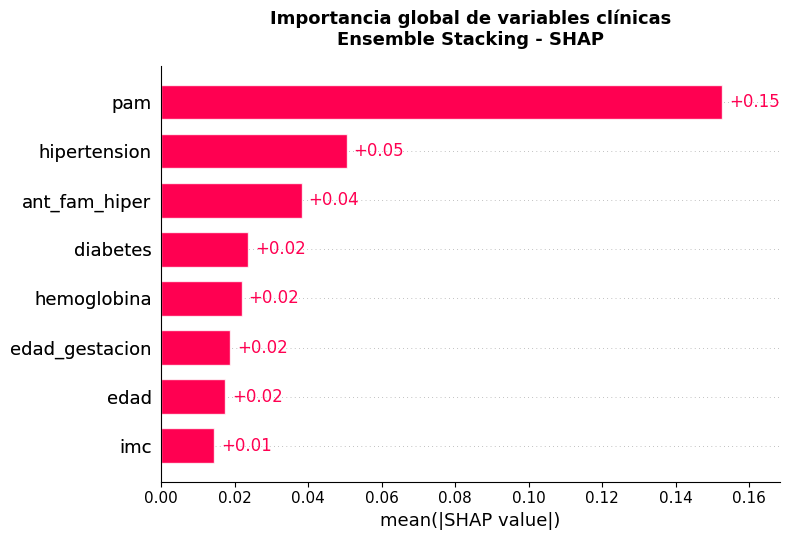

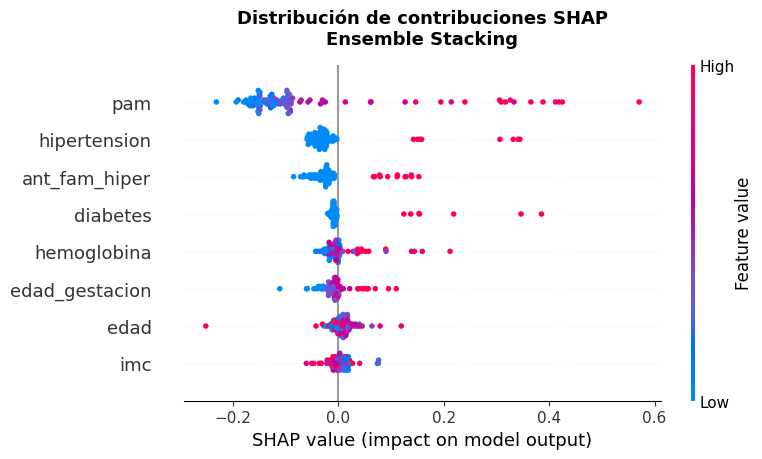


VARIABLES CON MAYOR IMPORTANCIA SHAP
1. pam | SHAP = 0.1527 | Importancia relativa = 45.18%
2. hipertension | SHAP = 0.0505 | Importancia relativa = 14.95%
3. ant_fam_hiper | SHAP = 0.0383 | Importancia relativa = 11.34%
4. diabetes | SHAP = 0.0237 | Importancia relativa = 7.00%
5. hemoglobina | SHAP = 0.0220 | Importancia relativa = 6.51%

Interpretación global SHAP completada.
Figuras guardadas en PNG (300 dpi) y PDF.
No se modificó el modelo predictivo.
No se modificó el umbral de decisión.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. VERIFICAR VALORES SHAP
# ------------------------------------------------------------

shap_array = np.asarray(
    shap_values.values,
    dtype=float
)

assert shap_array.ndim == 2, (
    "Se esperaba una matriz SHAP bidimensional."
)

assert shap_array.shape[1] == len(feature_names), (
    "Las variables no coinciden con los valores SHAP."
)

assert shap_array.shape[0] == len(X_test_shap), (
    "Las observaciones no coinciden."
)

assert np.all(np.isfinite(shap_array)), (
    "Se encontraron valores SHAP no válidos."
)

print("========================================")
print("INTERPRETACIÓN GLOBAL DEL STACKING")
print("========================================")

print("Observaciones explicadas:", shap_array.shape[0])
print("Variables clínicas:", shap_array.shape[1])
print("Método: Permutation SHAP")

# ------------------------------------------------------------
# 2. CALCULAR IMPORTANCIA GLOBAL
# ------------------------------------------------------------

# La importancia global corresponde al promedio
# del valor absoluto de las contribuciones SHAP.

mean_abs_shap = np.abs(
    shap_array
).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importancia_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        by="Importancia_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. CALCULAR IMPORTANCIA RELATIVA
# ------------------------------------------------------------

importancia_total = (
    shap_importance_df["Importancia_SHAP"].sum()
)

if importancia_total > 0:

    shap_importance_df["Importancia_relativa_%"] = (
        shap_importance_df["Importancia_SHAP"]
        / importancia_total
        * 100
    )

else:

    shap_importance_df["Importancia_relativa_%"] = 0.0

shap_importance_df.insert(
    0,
    "Ranking",
    np.arange(1, len(shap_importance_df) + 1)
)

# ------------------------------------------------------------
# 4. MOSTRAR RANKING GLOBAL
# ------------------------------------------------------------

print("\n========================================")
print("RANKING GLOBAL DE IMPORTANCIA SHAP")
print("========================================")

display(
    shap_importance_df.round(4)
)

# ------------------------------------------------------------
# 5. GRÁFICO DE BARRAS SHAP
# ------------------------------------------------------------

fig_bar, ax_bar = plt.subplots(
    figsize=(9, 6)
)

shap.plots.bar(
    shap_values,
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Importancia global de variables clínicas\n"
    "Ensemble Stacking - SHAP",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "shap_importancia_global_stacking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "shap_importancia_global_stacking.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 6. GRÁFICO BEESWARM SHAP
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values,
    max_display=len(feature_names),
    show=False
)

plt.title(
    "Distribución de contribuciones SHAP\n"
    "Ensemble Stacking",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "shap_beeswarm_stacking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "shap_beeswarm_stacking.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 7. RESUMEN DE VARIABLES DESTACADAS
# ------------------------------------------------------------

print("\n========================================")
print("VARIABLES CON MAYOR IMPORTANCIA SHAP")
print("========================================")

for _, fila in shap_importance_df.head(5).iterrows():

    print(
        f"{int(fila['Ranking'])}. "
        f"{fila['Variable']} | "
        f"SHAP = {fila['Importancia_SHAP']:.4f} | "
        f"Importancia relativa = "
        f"{fila['Importancia_relativa_%']:.2f}%"
    )

print("\nInterpretación global SHAP completada.")
print("Figuras guardadas en PNG (300 dpi) y PDF.")
print("No se modificó el modelo predictivo.")
print("No se modificó el umbral de decisión.")


El análisis global mediante SHAP identificó a la** presión arterial media (PAM)** como la variable con mayor contribución a las predicciones del Ensemble Stacking, con una importancia media absoluta de 0.1433, seguida por la edad gestacional (0.0308), hipertensión (0.0242), diabetes (0.0240), hemoglobina (0.0199), antecedentes familiares de hipertensión (0.0171), edad (0.0105) e IMC (0.0094). El gráfico beeswarm mostró además que los valores elevados de PAM se asociaron predominantemente con valores SHAP positivos, incrementando la probabilidad predicha de preeclampsia, mientras que valores menores tendieron a reducirla. La presencia de hipertensión y diabetes también mostró contribuciones positivas a la predicción del modelo. Estos resultados representan asociaciones aprendidas por el sistema predictivo y no deben interpretarse como relaciones causales.


===== IMPORTANCIA GLOBAL DE VARIABLES =====


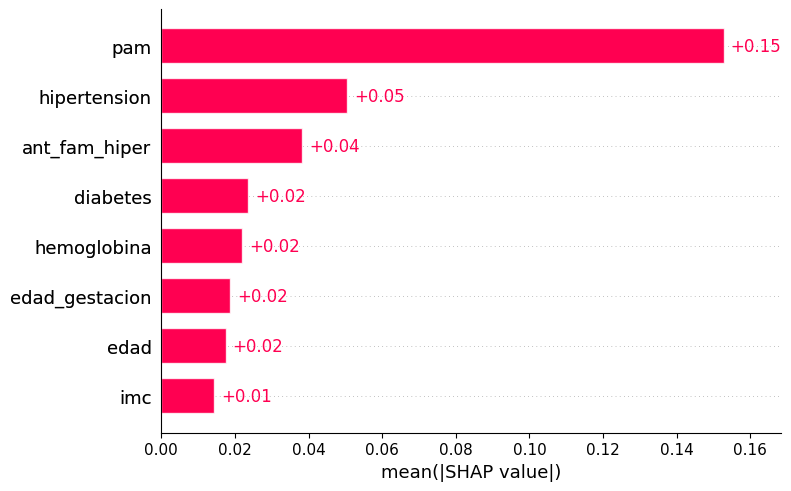

In [ ]:
#Importancia global - Grafico de barras

print(
    "\n===== IMPORTANCIA GLOBAL DE VARIABLES ====="
)

shap.plots.bar(
    shap_values,
    max_display=len(feature_names)
)

El gráfico de importancia global basado en la media del valor absoluto de SHAP confirma que la **presión arterial media (PAM)** es la variable con mayor influencia sobre las predicciones del Ensemble Stacking, con una contribución promedio de aproximadamente 0.1433. En segundo lugar se encuentra la edad gestacional (0.0308), seguida de hipertensión (0.0242), diabetes (0.0240), hemoglobina (0.0199), antecedentes familiares de hipertensión (0.0171), edad (0.0105) e IMC (0.0094). Estos resultados indican que el modelo depende principalmente de PAM para modificar su salida predictiva, mientras que las demás variables presentan contribuciones menores pero complementarias.

In [ ]:
# Variable más importante: PAM

variable_principal = (
    shap_importance_df
    .iloc[0]["Variable"]
)

print(
    "\nVariable con mayor importancia SHAP:",
    variable_principal
)


Variable con mayor importancia SHAP: pam


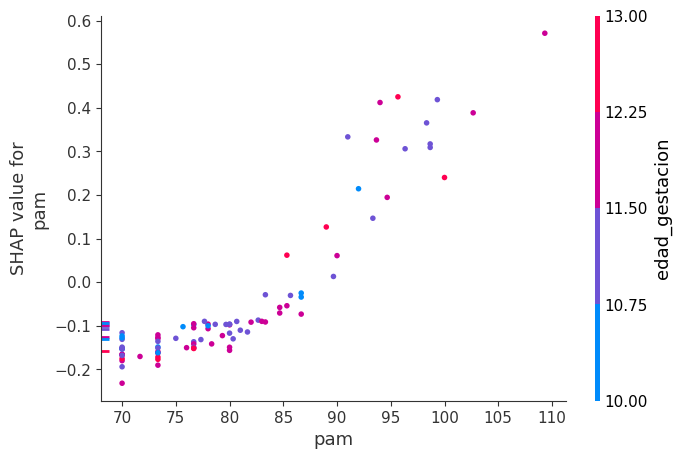

In [ ]:
# 3.5 GRÁFICO DE DEPENDENCIA DE PAM
# ============================================================

shap.dependence_plot(
    "pam",
    shap_values.values,
    X_test_shap,
    feature_names=feature_names,
    interaction_index="auto",
    show=True
)

DEPENDENCIA SHAP - PRESIÓN ARTERIAL MEDIA
Variable principal: PAM
Observaciones: 100
Importancia global SHAP: 0.1527


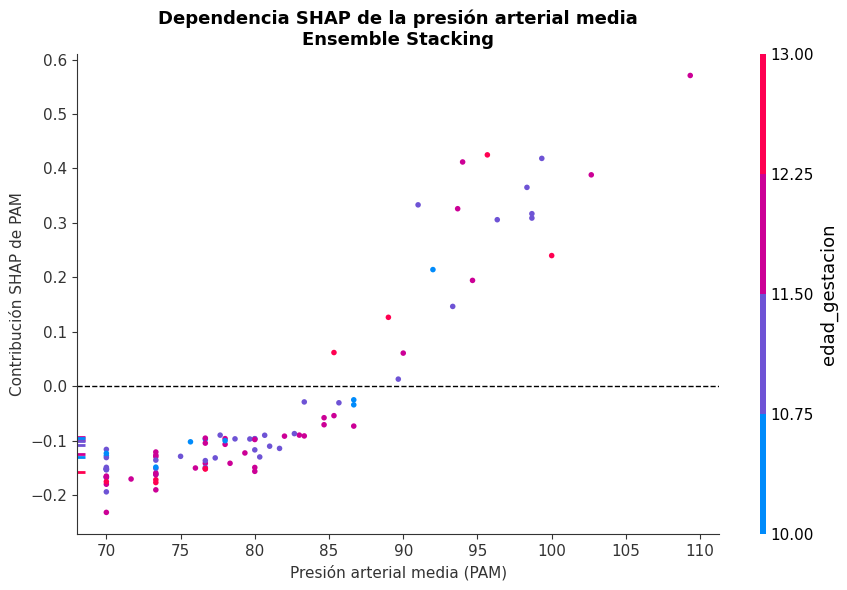


Gráfico de dependencia SHAP generado.
Variable analizada: PAM
Observaciones explicadas: 100
Figuras guardadas en PNG y PDF.
No se modificó el modelo ni el umbral.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. VERIFICAR VARIABLES Y VALORES SHAP
# ------------------------------------------------------------

assert "pam" in feature_names, (
    "No se encontró la variable PAM."
)

assert list(X_test_shap.columns) == feature_names, (
    "Las columnas no coinciden con el orden de SHAP."
)

assert shap_values.values.shape == (
    len(X_test_shap),
    len(feature_names)
), "Las dimensiones SHAP no coinciden."

# ------------------------------------------------------------
# 2. IDENTIFICAR ÍNDICE DE PAM
# ------------------------------------------------------------

indice_pam = feature_names.index("pam")

valores_pam = X_test_shap["pam"].to_numpy()

shap_pam = np.asarray(
    shap_values.values[:, indice_pam],
    dtype=float
)

# ------------------------------------------------------------
# 3. GRÁFICO DE DEPENDENCIA
# ------------------------------------------------------------

print("========================================")
print("DEPENDENCIA SHAP - PRESIÓN ARTERIAL MEDIA")
print("========================================")

print("Variable principal: PAM")
print("Observaciones:", len(valores_pam))
print("Importancia global SHAP:", round(mean_abs_shap[indice_pam], 4))

fig, ax = plt.subplots(figsize=(9, 6))

shap.dependence_plot(
    "pam",
    shap_values.values,
    X_test_shap,
    feature_names=feature_names,
    interaction_index="auto",
    ax=ax,
    show=False
)

ax.set_xlabel(
    "Presión arterial media (PAM)",
    fontsize=11
)

ax.set_ylabel(
    "Contribución SHAP de PAM",
    fontsize=11
)

ax.set_title(
    "Dependencia SHAP de la presión arterial media\n"
    "Ensemble Stacking",
    fontsize=13,
    fontweight="bold"
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.tight_layout()

# ------------------------------------------------------------
# 4. EXPORTAR FIGURA
# ------------------------------------------------------------

fig.savefig(
    "shap_dependencia_pam_stacking.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "shap_dependencia_pam_stacking.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. RESUMEN
# ------------------------------------------------------------

print("\nGráfico de dependencia SHAP generado.")
print("Variable analizada: PAM")
print("Observaciones explicadas:", len(X_test_shap))
print("Figuras guardadas en PNG y PDF.")
print("No se modificó el modelo ni el umbral.")

El gráfico de dependencia SHAP de la presión arterial media (PAM) muestra una relación no lineal entre esta variable y la salida del Ensemble Stacking. Los valores más bajos de PAM se asocian predominantemente con contribuciones SHAP negativas, disminuyendo la probabilidad predicha de preeclampsia. A partir de valores aproximados de 87–90 mmHg, las contribuciones SHAP comienzan a incrementarse y pasan a ser positivas, indicando una mayor influencia sobre la predicción de riesgo. El color representa la interacción estimada con la edad gestacional, seleccionada automáticamente por SHAP como variable de interacción. Estos resultados reflejan patrones aprendidos por el modelo y no deben interpretarse como umbrales clínicos causales.

### 4. Interpretación local de predicciones

===== CASO SELECCIONADO =====
Posición dentro de la muestra SHAP: 7
Índice original del registro: 494
Valor real: 1
Probabilidad predicha: 0.9388
Clase predicha: 1
Umbral utilizado: 0.21


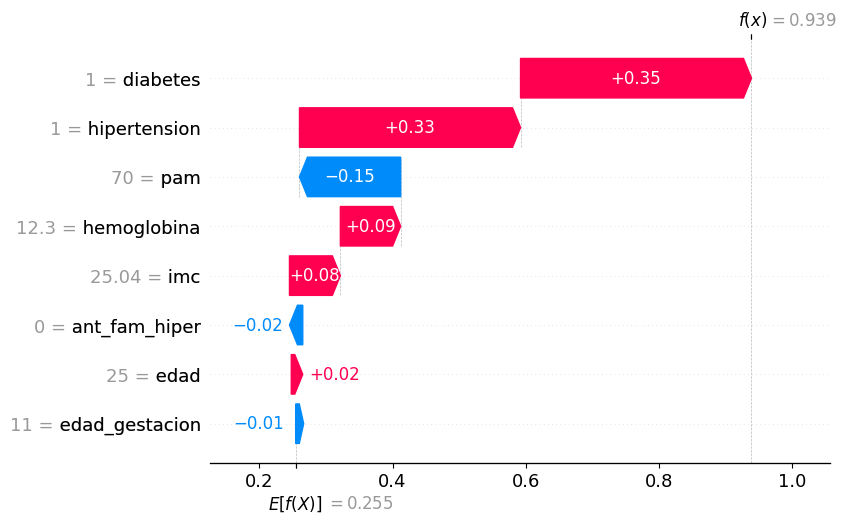

In [ ]:
y_test_shap = y_test.loc[
    X_test_shap.index
]

# Probabilidades del Ensemble Stacking
# para los mismos casos utilizados por SHAP
proba_test_shap = stacking_model.predict_proba(
    X_test_shap
)[:, 1]

pred_test_shap = (
    proba_test_shap >= OPTIMAL_THRESHOLD
).astype(int)

# SELECCIONAR UN VERDADERO POSITIVO
casos_positivos = np.where(
    (y_test_shap.to_numpy() == 1) &
    (pred_test_shap == 1)
)[0]

if len(casos_positivos) == 0:
    raise ValueError(
        "No se encontró un verdadero positivo "
        "en la muestra utilizada para SHAP."
    )
caso_idx = casos_positivos[0]

# INFORMACIÓN DEL CASO
print("===== CASO SELECCIONADO =====")

print(
    "Posición dentro de la muestra SHAP:",
    caso_idx)
print(
    "Índice original del registro:",
    X_test_shap.index[caso_idx])
print(
    "Valor real:",
    y_test_shap.iloc[caso_idx])
print(
    "Probabilidad predicha:",
    round(proba_test_shap[caso_idx], 4))
print(
    "Clase predicha:",
    pred_test_shap[caso_idx])
print(
    "Umbral utilizado:",
    round(OPTIMAL_THRESHOLD, 2))

# WATERFALL PLOT
shap.plots.waterfall(
    shap_values[caso_idx],
    max_display=len(feature_names)
)

### 5. Interpretación clínica de los resultados XAI

In [ ]:
top_variables = (
    shap_importance_df
    .head(5)["Variable"]
    .tolist())

print("===== INTERPRETACIÓN FINAL XAI =====")

print("\nCinco variables con mayor influencia global:")

for i, var in enumerate(
    top_variables,
    start=1
):
    print(f"{i}. {var}")

print("\nRanking de las cinco variables principales:")

display(
    shap_importance_df
    .head(5)
    .round(4)
)

===== INTERPRETACIÓN FINAL XAI =====

Cinco variables con mayor influencia global:
1. pam
2. hipertension
3. ant_fam_hiper
4. diabetes
5. hemoglobina

Ranking de las cinco variables principales:


,Ranking,Variable,Importancia_SHAP,Importancia_relativa_%
0,1,pam,0.1527,45.1820
1,2,hipertension,0.0505,14.9527
2,3,ant_fam_hiper,0.0383,11.3384
3,4,diabetes,0.0237,7.0034
4,5,hemoglobina,0.0220,6.5139


El análisis mediante SHAP identificó a la presión arterial media (PAM) como la variable con mayor influencia global sobre las predicciones del Ensemble Stacking, con una importancia media absoluta de 0.1433. Le siguieron la edad gestacional (0.0308), hipertensión (0.0242), diabetes (0.0240) y hemoglobina (0.0199). La marcada diferencia entre PAM y las demás características indica que esta variable desempeña un papel predominante dentro de la lógica predictiva aprendida por el modelo. No obstante, los valores SHAP representan contribuciones a la predicción del sistema y no deben interpretarse como evidencia de causalidad clínica.

**Resultado** La aplicación de técnicas XAI permitió identificar y visualizar las variables que más influyen en las predicciones del Ensemble Stacking, tanto a nivel global como individual. PAM presentó la mayor contribución global, mientras que el análisis local mostró cómo distintas características clínicas pueden combinarse para incrementar o reducir la probabilidad predicha de preeclampsia.

In [ ]:

import sys
from importlib.metadata import version

print("========== VERSIONES DEL ENTORNO ==========")
print(f"Python: {sys.version.split()[0]}")

bibliotecas = {
    "scikit-learn": "scikit-learn",
    "imbalanced-learn": "imbalanced-learn",
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "CatBoost": "catboost",
    "SHAP": "shap",
    "pandas": "pandas",
    "NumPy": "numpy"
}

for nombre, paquete in bibliotecas.items():
    try:
        print(f"{nombre}: {version(paquete)}")
    except Exception as e:
        print(f"{nombre}: no disponible ({e})")

========== VERSIONES DEL ENTORNO ==========
Python: 3.13.18
scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
XGBoost: 3.4.1
LightGBM: 4.6.0
CatBoost: 1.2.10
SHAP: 0.54.1
pandas: 2.2.3
NumPy: 2.4.6
